C:\Users\VEDANT\AppData\Local\Temp\ipykernel_7208\4236406497.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start, end=end)["Close"]
[*********************100%***********************]  4 of 4 completed


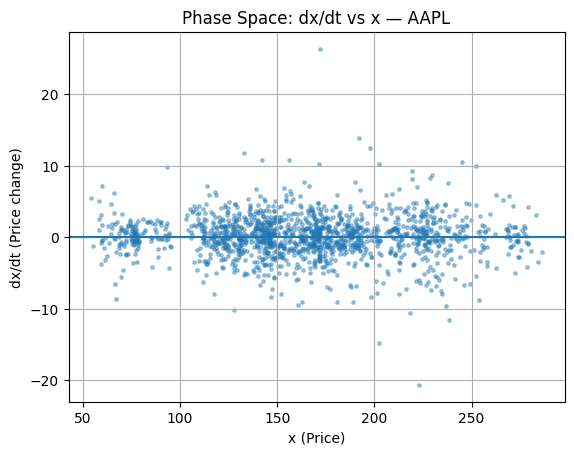

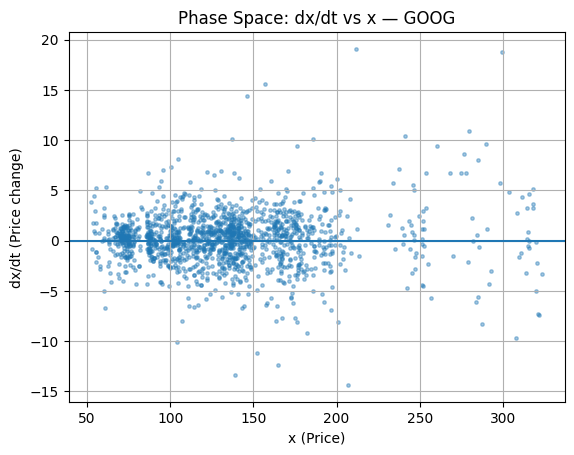

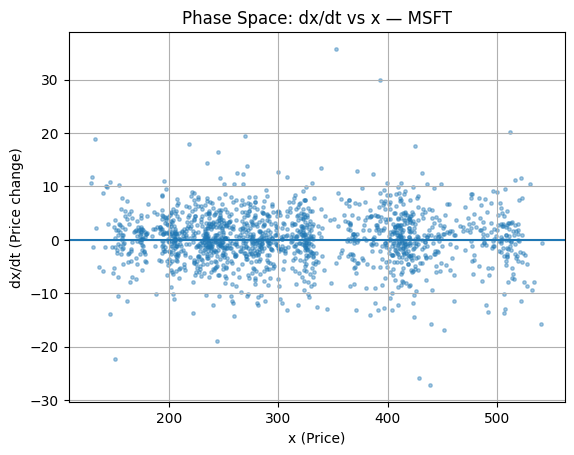

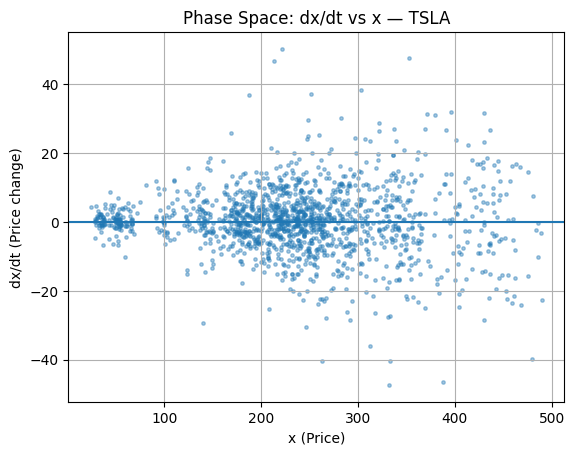

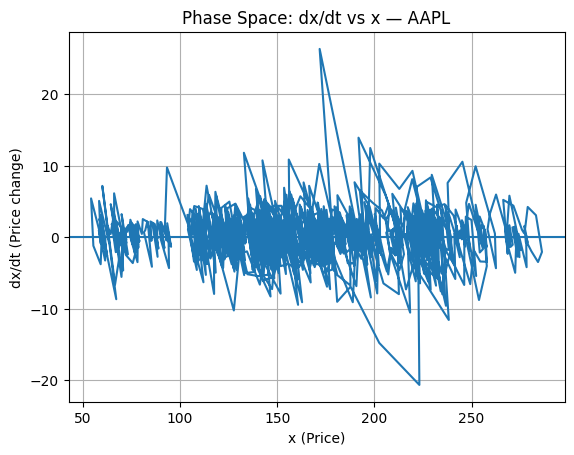

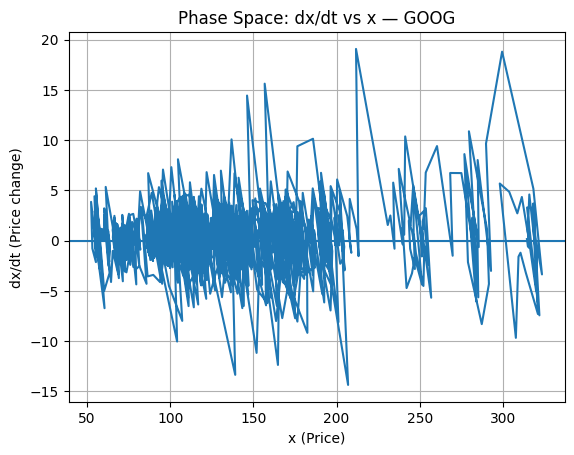

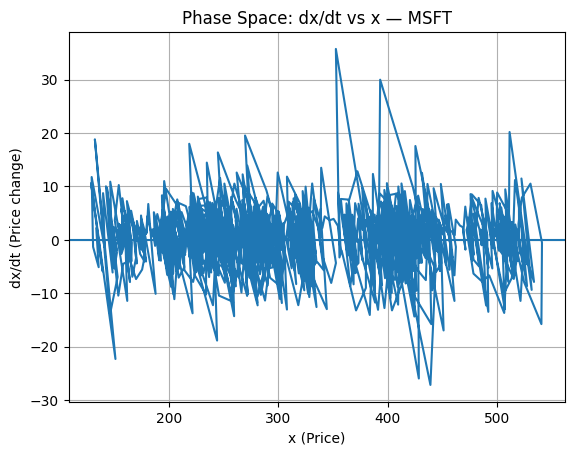

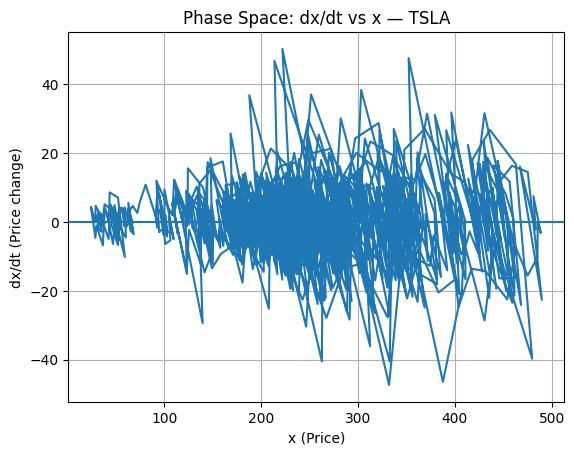

In [4]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# -----------------------------
# Parameters
# -----------------------------
tickers = ["AAPL", "MSFT", "GOOG", "TSLA"]
start = "2020-01-01"
end   = "2025-12-31"

# -----------------------------
# Download data
# -----------------------------
data = yf.download(tickers, start=start, end=end)["Close"]

# Ensure DataFrame even for single ticker
if isinstance(data, pd.Series):
    data = data.to_frame()

# -----------------------------
# Plot dx/dt vs x
# -----------------------------
for ticker in data.columns:
    x = data[ticker].dropna().values
    
    # Discrete time derivative
    dxdt = np.diff(x)
    x_mid = x[:-1]   # align with dx/dt

    plt.figure()
    plt.scatter(
        x_mid,
        dxdt,
        s=6,
        alpha=0.4
    )
    
    plt.axhline(0)
    plt.xlabel("x (Price)")
    plt.ylabel("dx/dt (Price change)")
    plt.title(f"Phase Space: dx/dt vs x — {ticker}")
    plt.grid(True)
    plt.show()

# -----------------------------
# Plot dx/dt vs x
# -----------------------------
for ticker in data.columns:
    x = data[ticker].dropna().values
    
    # Discrete time derivative
    dxdt = np.diff(x)
    x_mid = x[:-1]   # align with dx/dt

    plt.figure()
    plt.plot(
        x_mid,
        dxdt
    )
    
    plt.axhline(0)
    plt.xlabel("x (Price)")
    plt.ylabel("dx/dt (Price change)")
    plt.title(f"Phase Space: dx/dt vs x — {ticker}")
    plt.grid(True)
    plt.show()

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


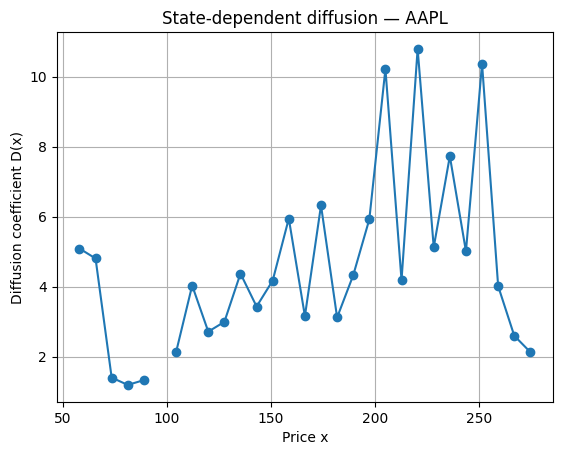

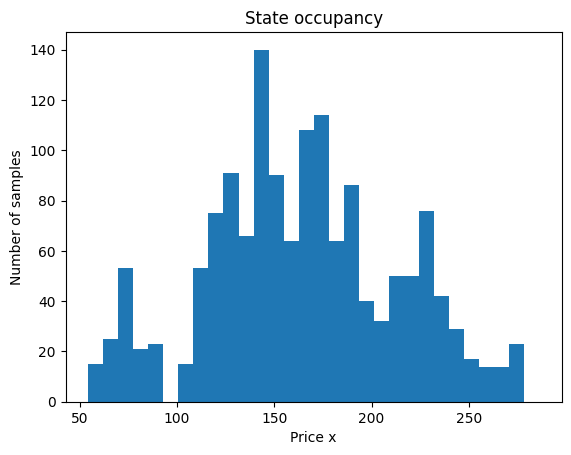

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


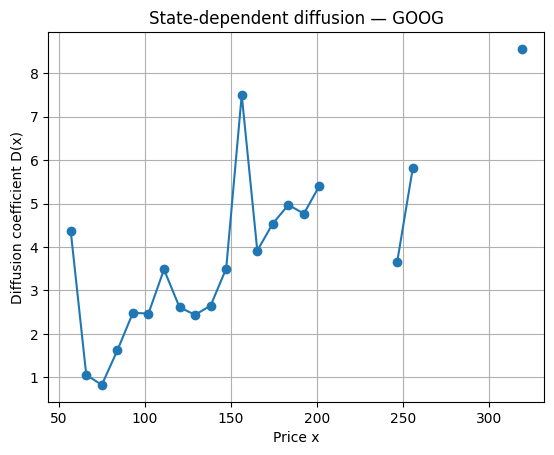

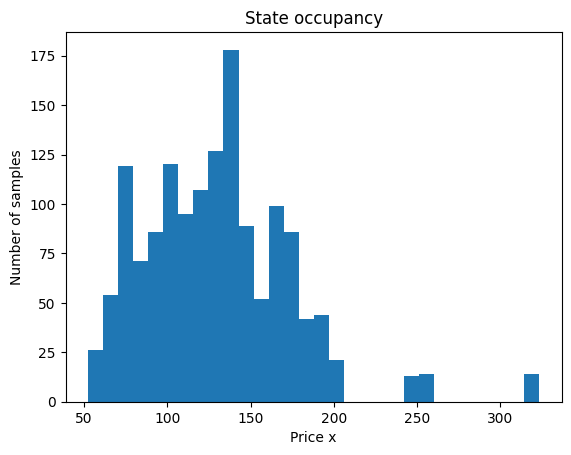

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


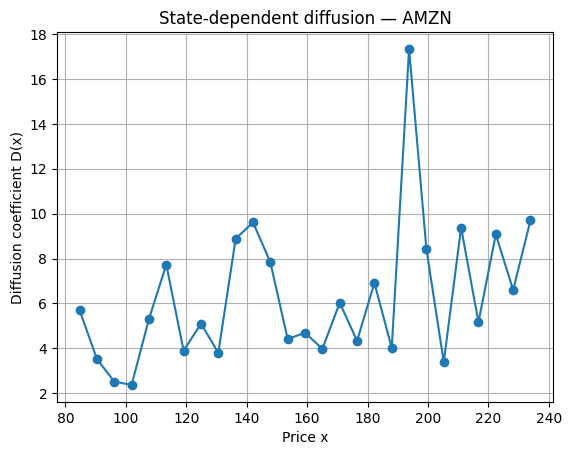

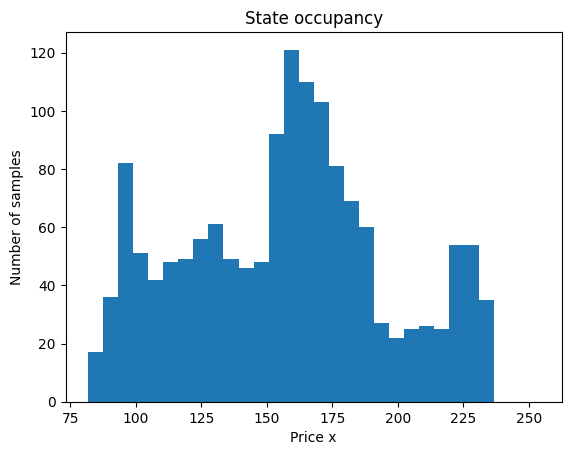

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


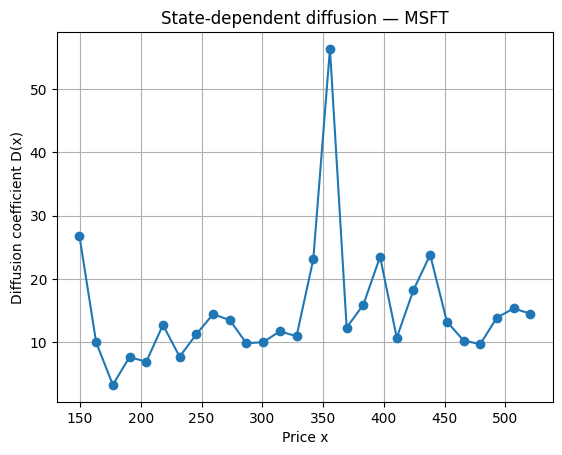

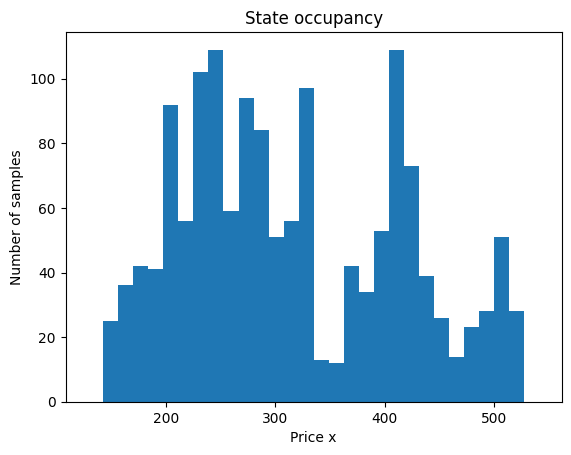

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


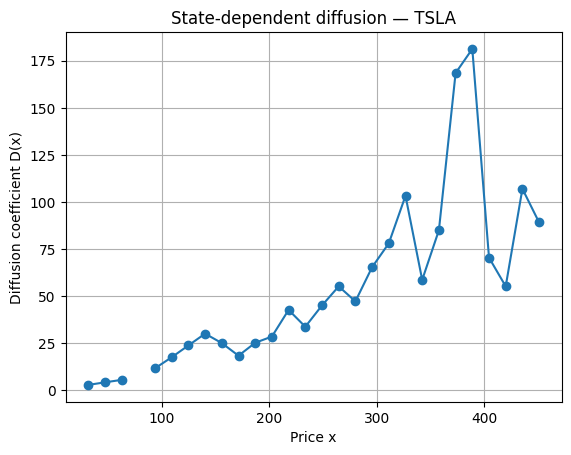

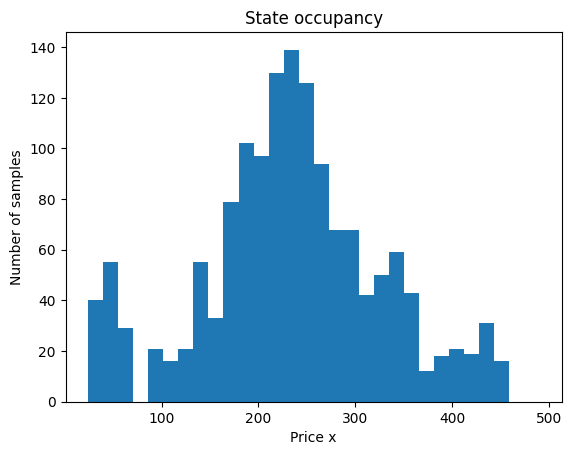

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


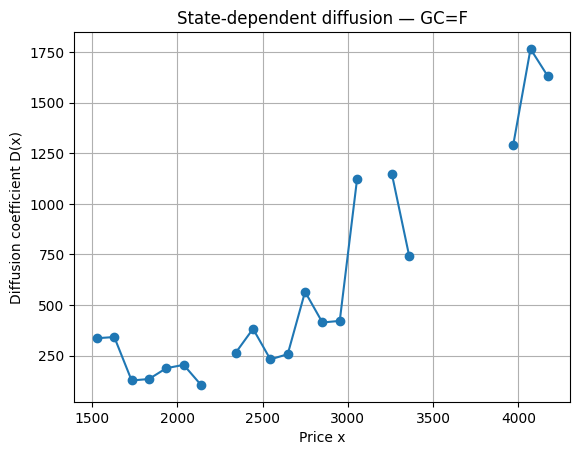

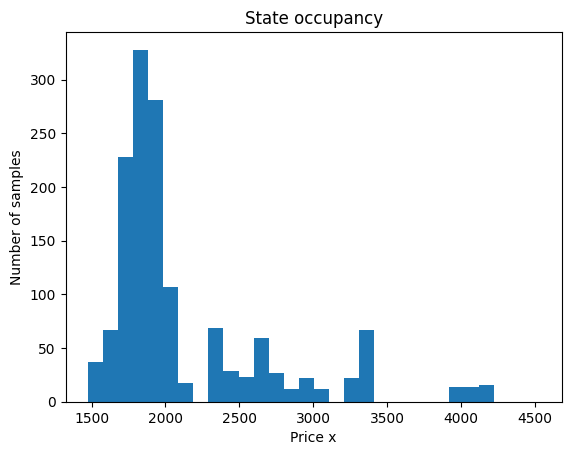

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


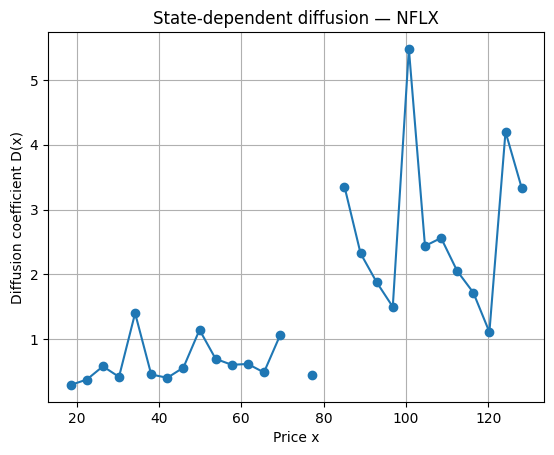

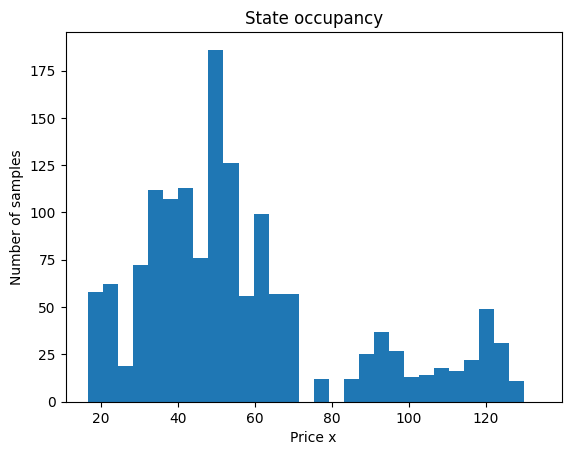

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


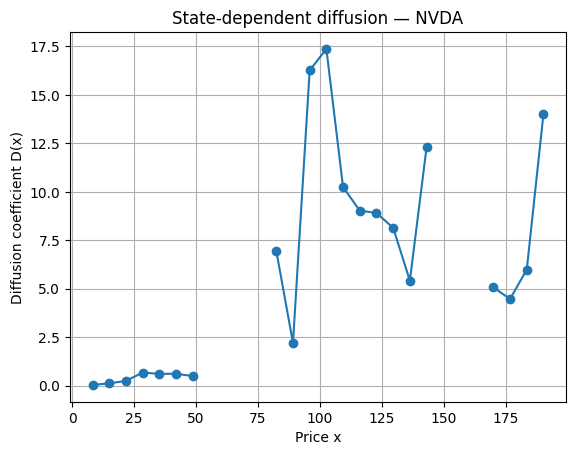

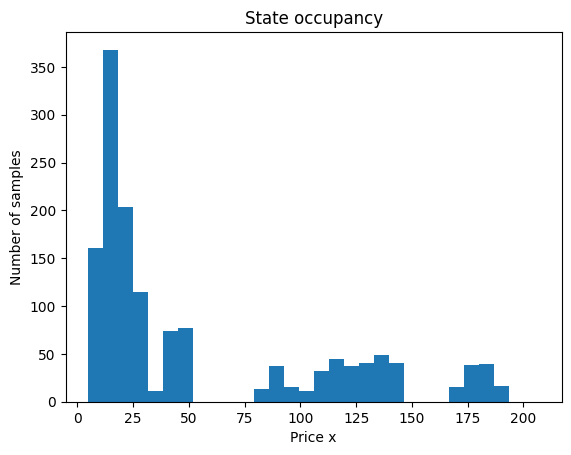

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


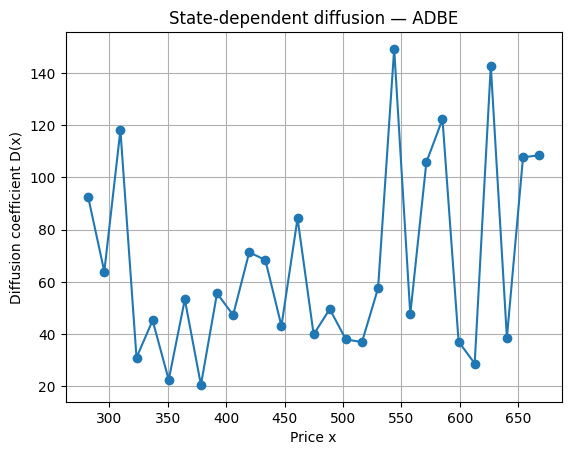

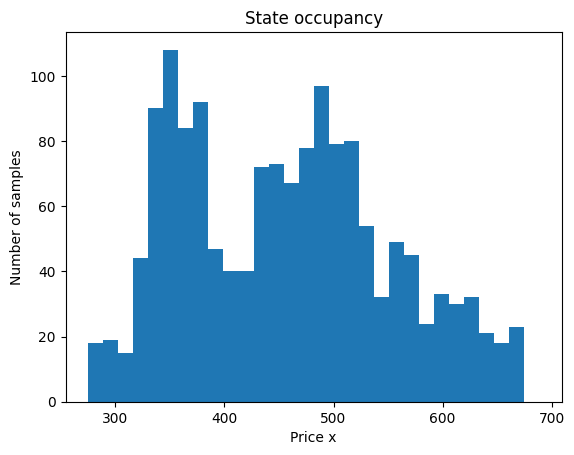

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


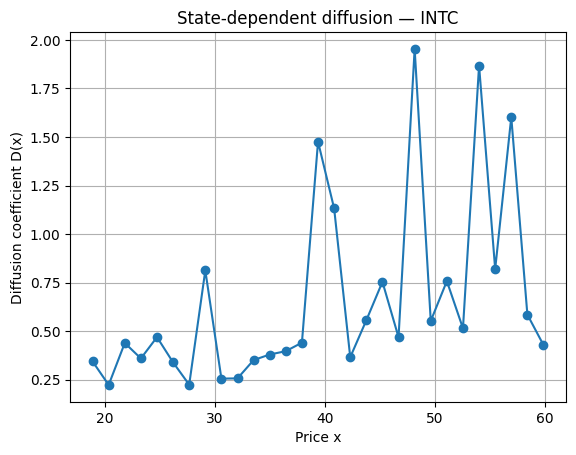

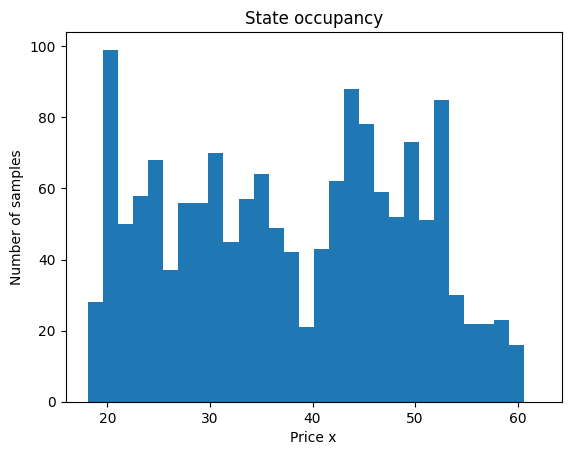

In [14]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

tickers = ["AAPL", "GOOG", "AMZN", "MSFT", "TSLA", "GC=F", "NFLX", "NVDA", "ADBE", "INTC"]
start = "2020-01-01"
end   = "2025-12-31"
n_bins = 30
dt = 1.0

for ticker in tickers:
    prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values

    # --- FIXED ALIGNMENT ---
    x  = prices[:-1]
    dx = prices[1:] - prices[:-1]

    bins = np.linspace(x.min(), x.max(), n_bins + 1)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])

    D = np.full(n_bins, np.nan)
    counts = np.zeros(n_bins)

    for i in range(n_bins):
        mask = (x >= bins[i]) & (x < bins[i+1])
        if np.sum(mask) > 10:
            D[i] = np.var(dx[mask], ddof=1) / (2 * dt)
            counts[i] = np.sum(mask)

    plt.figure()
    plt.plot(bin_centers, D, marker="o")
    plt.xlabel("Price x")
    plt.ylabel("Diffusion coefficient D(x)")
    plt.title(f"State-dependent diffusion — {ticker}")
    plt.grid(True)
    plt.show()

    plt.figure()
    plt.bar(bin_centers, counts, width=(bins[1]-bins[0]))
    plt.xlabel("Price x")
    plt.ylabel("Number of samples")
    plt.title("State occupancy")
    plt.show()


[*********************100%***********************]  4 of 4 completed


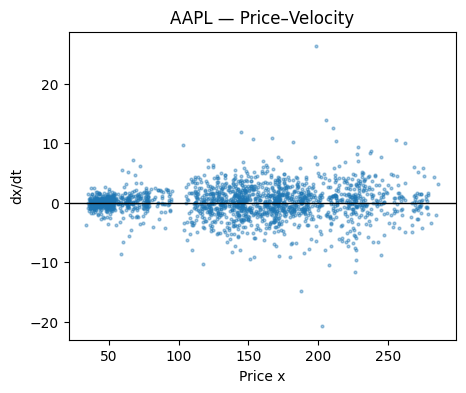

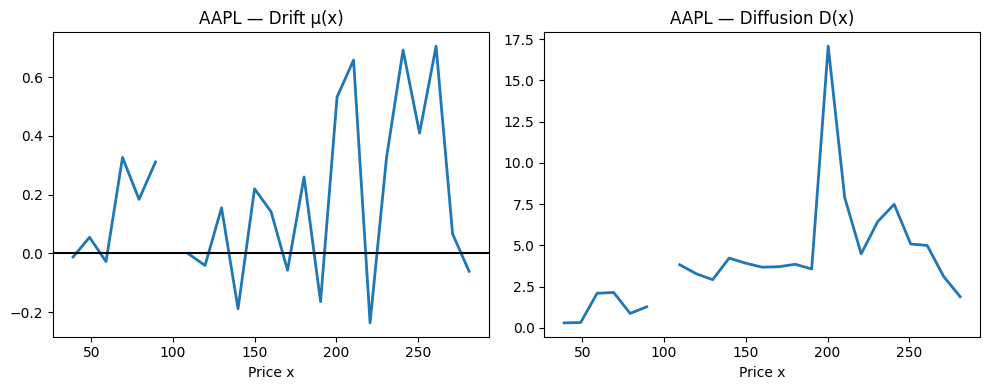

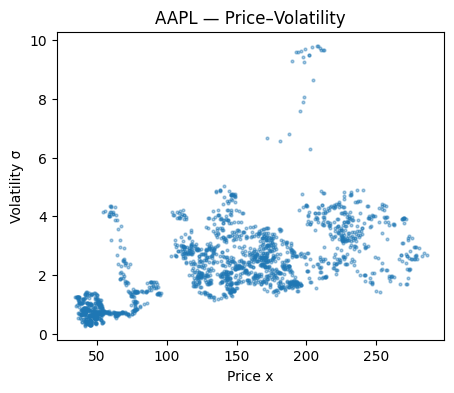

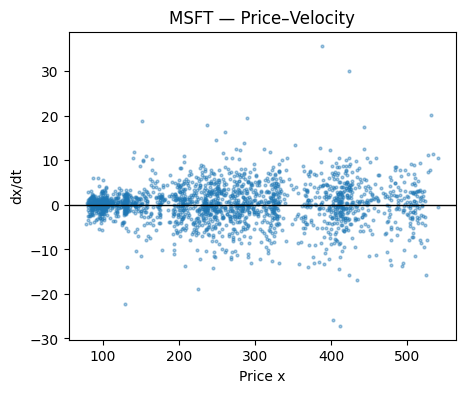

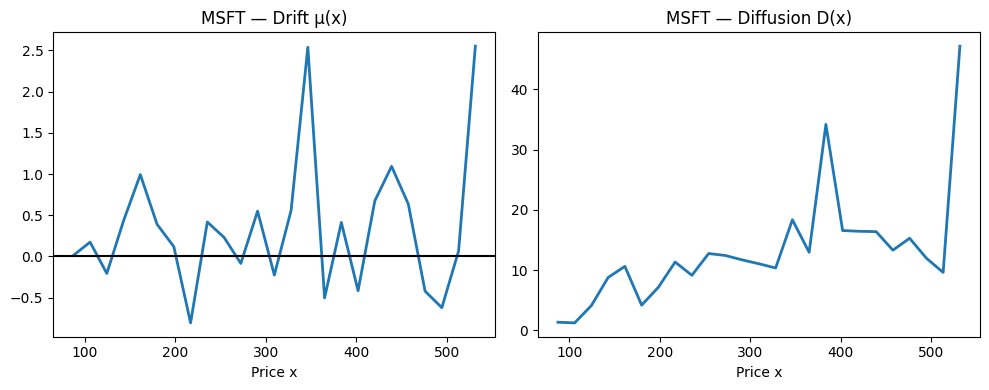

...

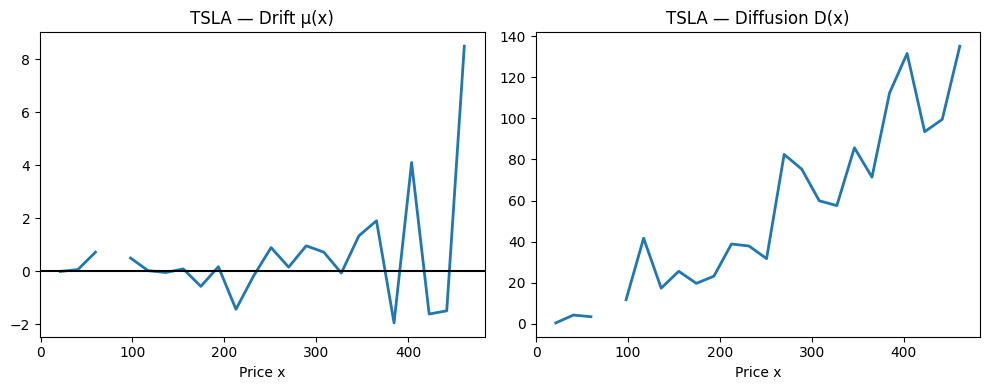

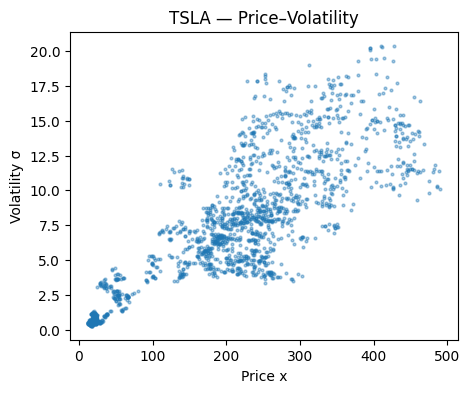

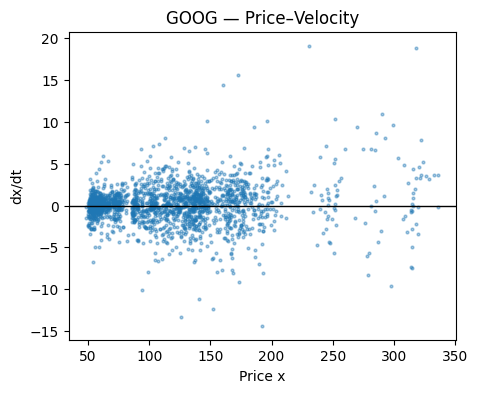

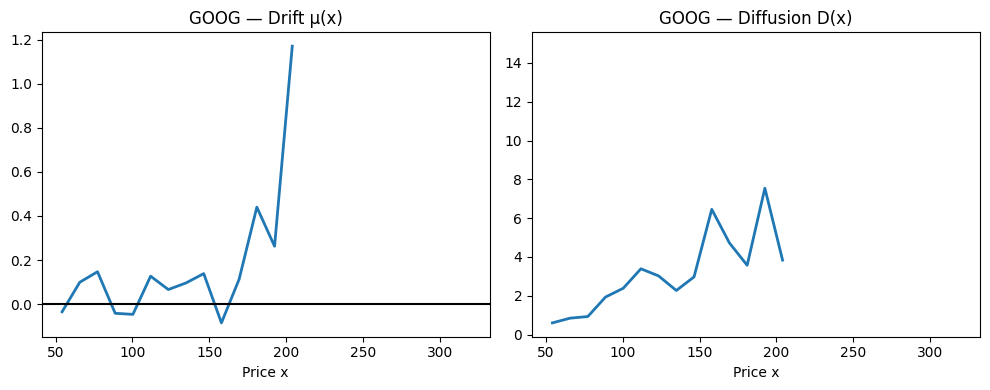

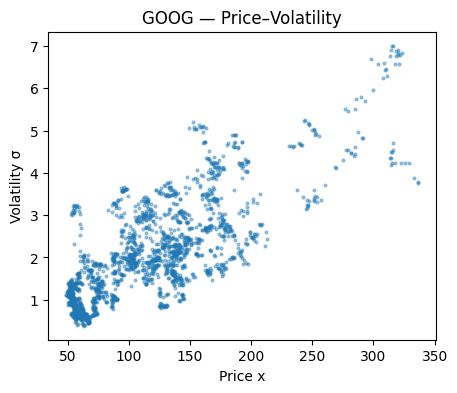

In [15]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# -----------------------------
# PARAMETERS
# -----------------------------
tickers = ["AAPL", "MSFT", "TSLA", "GOOG"]
start = "2018-01-01"
nbins = 25
vol_window = 20

# -----------------------------
# LOAD DATA
# -----------------------------
prices = yf.download(tickers, start=start, auto_adjust=True)["Close"].dropna()

# -----------------------------
# MAIN LOOP
# -----------------------------
for ticker in tickers:
    p = prices[ticker].dropna().values

    # ---------- 1. PRICE–VELOCITY ----------
    x = p[1:]
    dx = np.diff(p)

    plt.figure(figsize=(5,4))
    plt.scatter(x, dx, s=4, alpha=0.4)
    plt.axhline(0, color="k", lw=1)
    plt.xlabel("Price x")
    plt.ylabel("dx/dt")
    plt.title(f"{ticker} — Price–Velocity")
    plt.show()

    # ---------- 2. DRIFT & DIFFUSION ----------
    bins = np.linspace(x.min(), x.max(), nbins+1)
    centers = 0.5 * (bins[:-1] + bins[1:])
    drift = np.full(nbins, np.nan)
    diffusion = np.full(nbins, np.nan)

    for i in range(nbins):
        mask = (x >= bins[i]) & (x < bins[i+1])
        if np.sum(mask) > 10:
            drift[i] = np.mean(dx[mask])
            diffusion[i] = 0.5 * np.mean(dx[mask]**2)

    fig, ax = plt.subplots(1, 2, figsize=(10,4))

    ax[0].plot(centers, drift, lw=2)
    ax[0].axhline(0, color="k")
    ax[0].set_title(f"{ticker} — Drift μ(x)")
    ax[0].set_xlabel("Price x")

    ax[1].plot(centers, diffusion, lw=2)
    ax[1].set_title(f"{ticker} — Diffusion D(x)")
    ax[1].set_xlabel("Price x")

    plt.tight_layout()
    plt.show()

    # ---------- 3. PRICE–VOLATILITY ----------
    vol = pd.Series(dx).rolling(vol_window).std().values

    plt.figure(figsize=(5,4))
    plt.scatter(x, vol, s=4, alpha=0.4)
    plt.xlabel("Price x")
    plt.ylabel("Volatility σ")
    plt.title(f"{ticker} — Price–Volatility")
    plt.show()


[*********************100%***********************]  3 of 3 completed


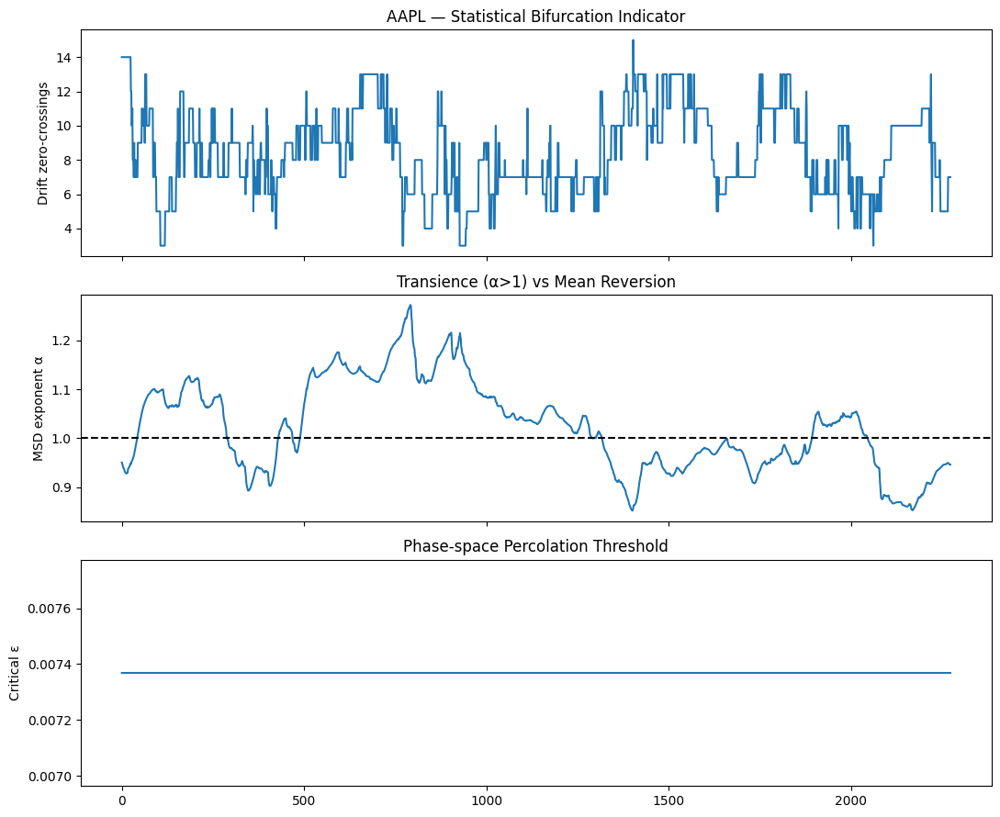

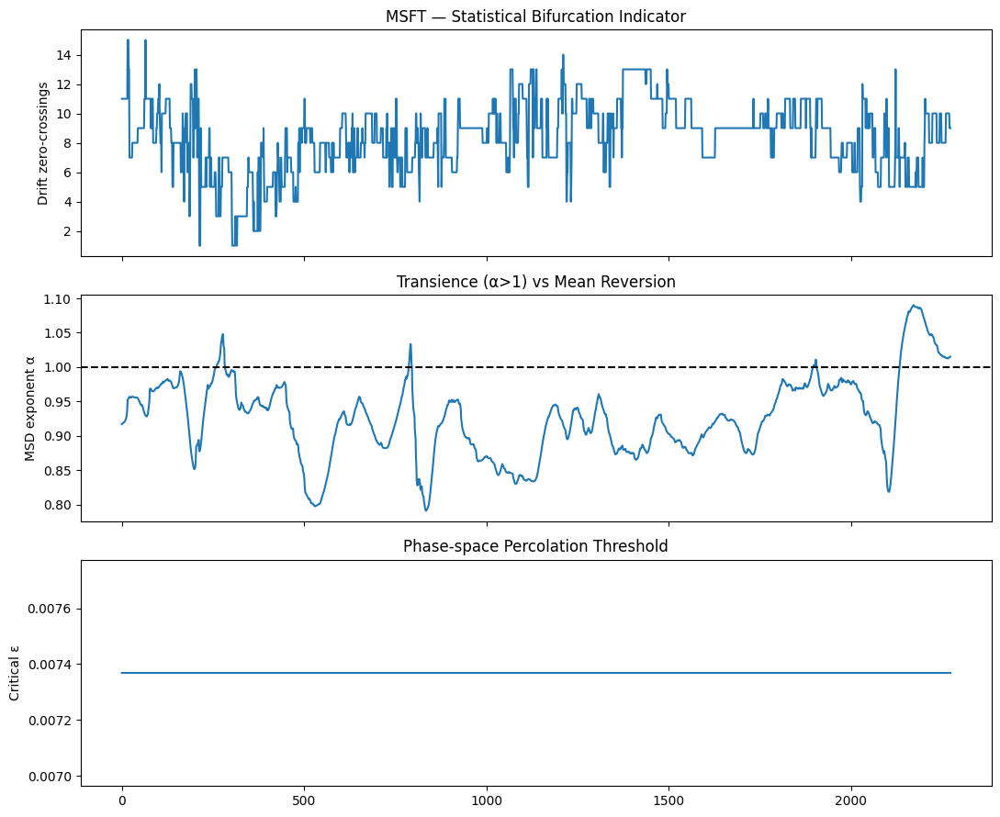

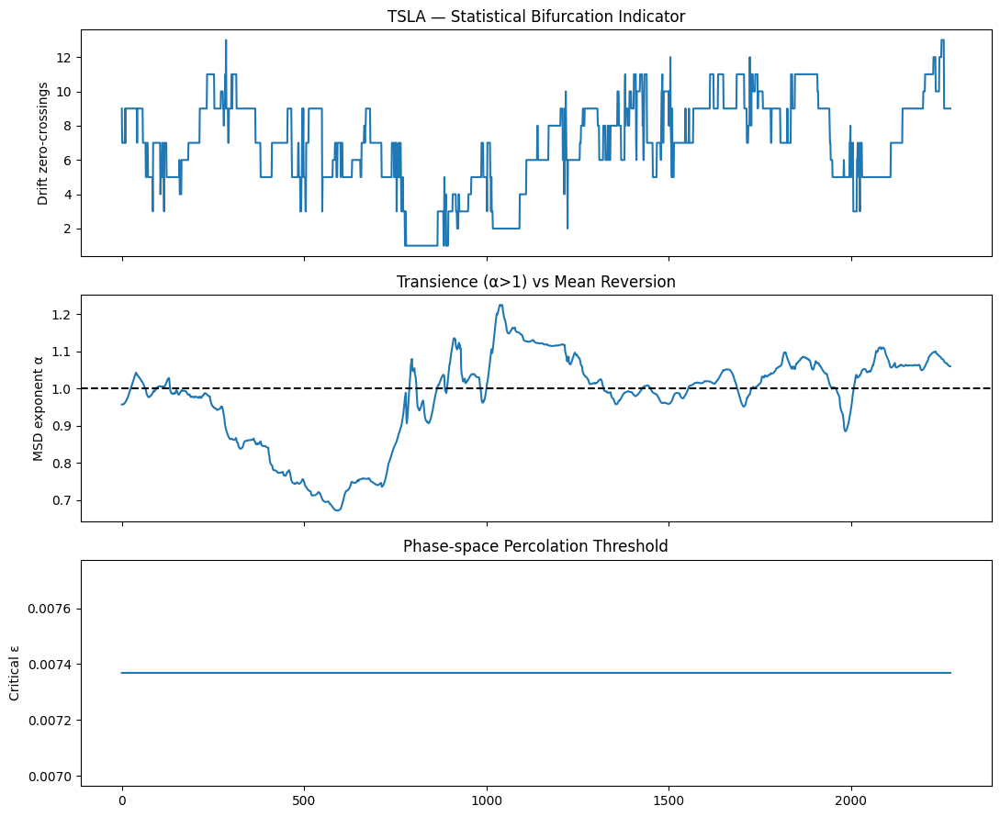

In [19]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.stats import linregress

# =============================
# PARAMETERS
# =============================
tickers = ["AAPL", "MSFT", "TSLA"]
start = "2015-01-01"

window = 500
nbins = 25
tau = 5

max_lag = 50
eps_fracs = np.linspace(0.005, 0.05, 20)  # relative phase-space scales

# =============================
# LOAD DATA
# =============================
prices = yf.download(tickers, start=start, auto_adjust=True)["Close"].dropna()

# =====================================================
# 1️⃣ BIFURCATION: drift topology changes
# =====================================================
def rolling_drift_zeros(x, dx):
    bins = np.linspace(x.min(), x.max(), nbins + 1)
    drift = np.full(nbins, np.nan)

    for i in range(nbins):
        mask = (x >= bins[i]) & (x < bins[i+1])
        if np.sum(mask) > 10:
            drift[i] = np.mean(dx[mask])

    drift = drift[~np.isnan(drift)]
    return np.sum(np.diff(np.sign(drift)) != 0)

# =====================================================
# 2️⃣ TRANSIENCE: MSD scaling exponent
# =====================================================
def msd_exponent(x):
    lags = np.arange(1, max_lag)
    msd = [(x[lag:] - x[:-lag])**2 for lag in lags]
    msd = np.array([m.mean() for m in msd])

    slope, _, _, _, _ = linregress(np.log(lags), np.log(msd))
    return slope  # α

# =====================================================
# 3️⃣ PERCOLATION: ε–connectivity transition
# =====================================================
def percolation_curve(x):
    # Delay embedding
    X = np.column_stack([x[:-tau], x[tau:]])
    scale = np.std(X)

    fractions = []

    for ef in eps_fracs:
        eps = ef * scale
        nbrs = NearestNeighbors(radius=eps)
        nbrs.fit(X)
        G = nbrs.radius_neighbors_graph(X)

        # fraction of nodes with at least one neighbor
        fractions.append(np.mean(G.sum(axis=1).A1 > 0))

    return np.array(fractions)

def critical_epsilon(fractions):
    # Percolation threshold ≈ max slope point
    grad = np.gradient(fractions, eps_fracs)
    return eps_fracs[np.argmax(grad)]

# =====================================================
# RUN ANALYSIS
# =====================================================
for ticker in tickers:
    p = prices[ticker].values
    dx = np.diff(p)

    bif_vals = []
    msd_vals = []
    eps_c_vals = []

    for i in range(window, len(p) - 1):
        xw = p[i - window : i]
        dxw = dx[i - window : i - 1]

        bif_vals.append(rolling_drift_zeros(xw[1:], dxw))
        msd_vals.append(msd_exponent(xw))

        perc = percolation_curve(xw)
        eps_c_vals.append(critical_epsilon(perc))

    # =============================
    # PLOTS
    # =============================
    fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

    ax[0].plot(bif_vals, lw=1.5)
    ax[0].set_ylabel("Drift zero-crossings")
    ax[0].set_title(f"{ticker} — Statistical Bifurcation Indicator")

    ax[1].plot(msd_vals, lw=1.5)
    ax[1].axhline(1, ls="--", color="k")
    ax[1].set_ylabel("MSD exponent α")
    ax[1].set_title("Transience (α>1) vs Mean Reversion")

    ax[2].plot(eps_c_vals, lw=1.5)
    ax[2].set_ylabel("Critical ε")
    ax[2].set_title("Phase-space Percolation Threshold")

    plt.tight_layout()
    plt.show()


# MF-DFA

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25620\3175828798.py:22: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed

AAPL


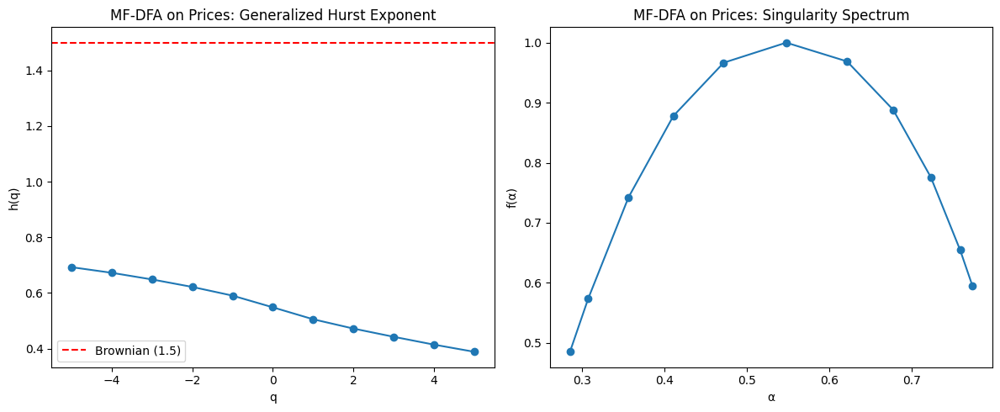

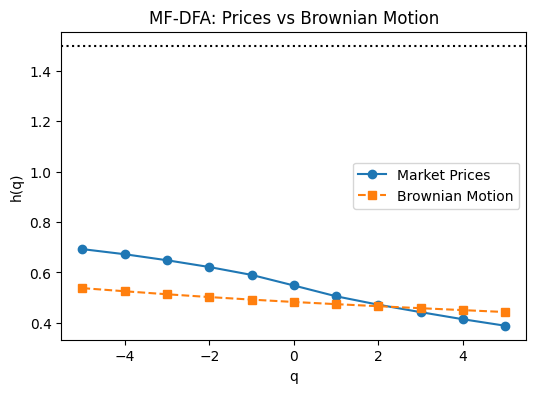

GOOG


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25620\3175828798.py:22: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed


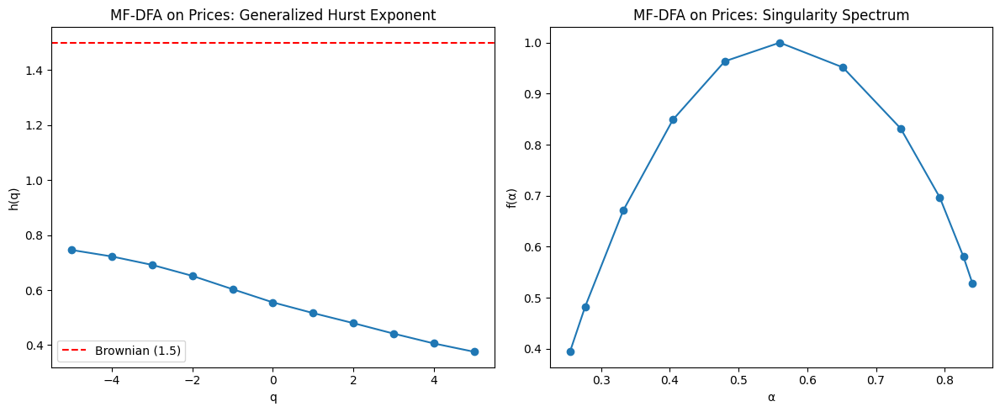

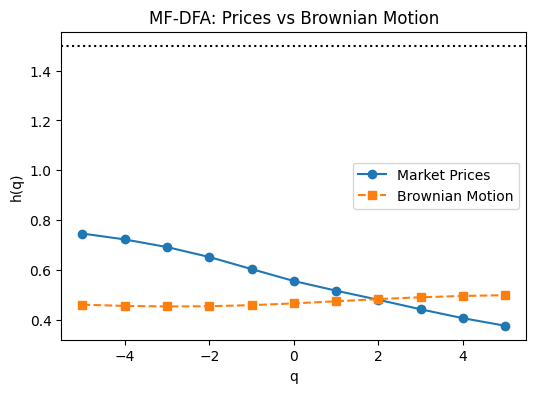

AMZN


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25620\3175828798.py:22: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed


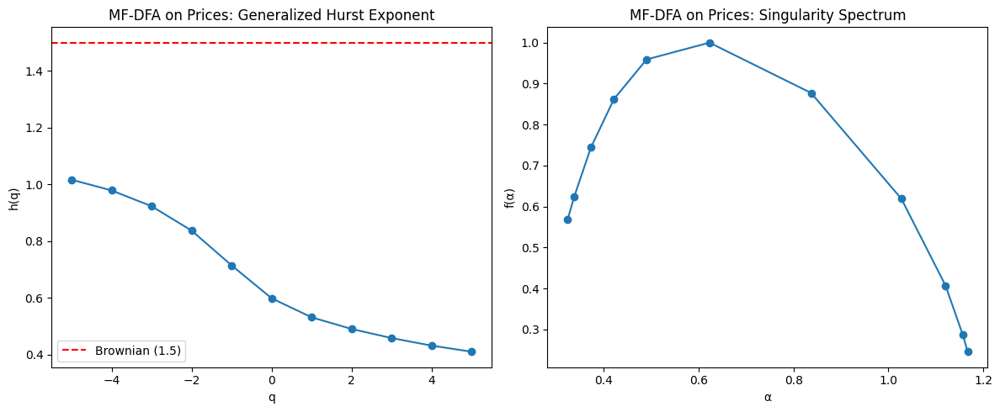

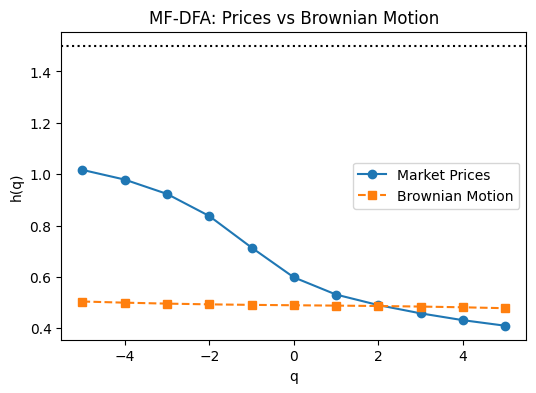

MSFT


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25620\3175828798.py:22: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed


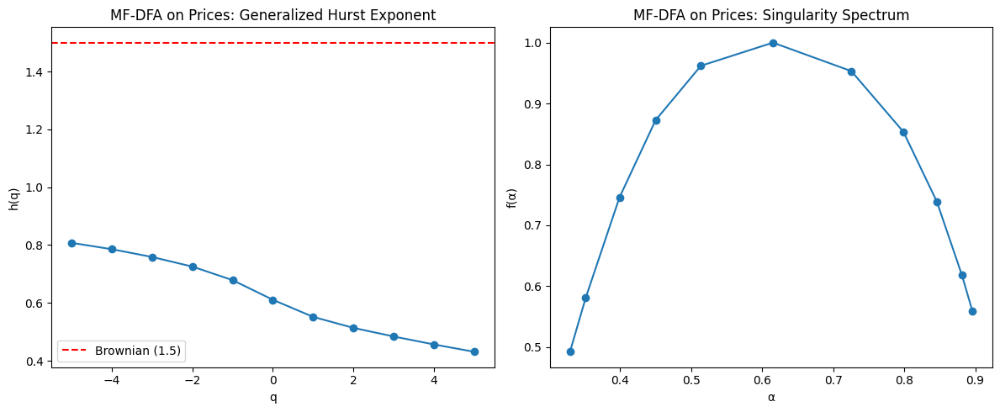

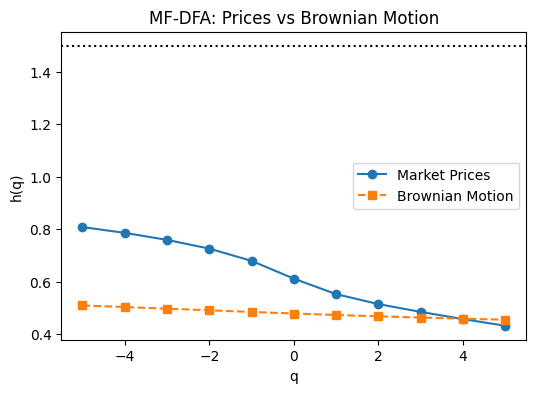

TSLA


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25620\3175828798.py:22: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed


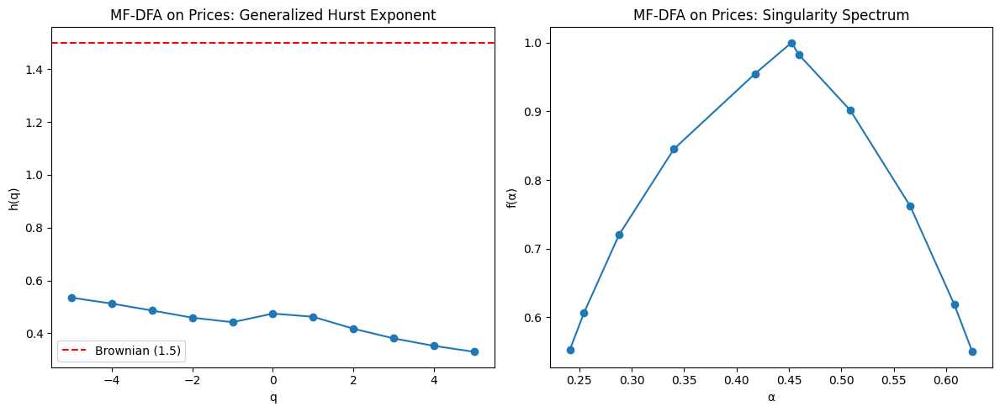

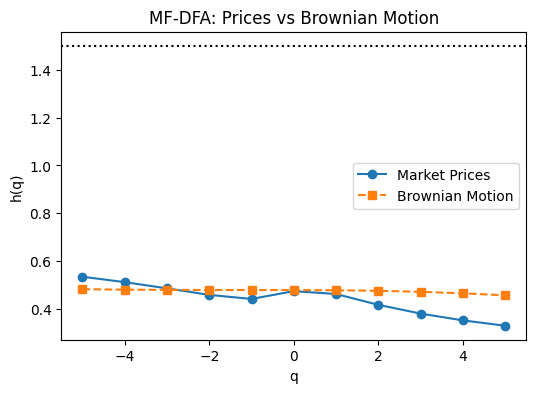

In [4]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# --------------------------------
# PARAMETERS
# --------------------------------
tickers = ["AAPL", "GOOG", "AMZN", "MSFT", "TSLA"]
start = "2015-01-01"
end = "2026-01-01"
for ticker in tickers:
    print(ticker)
    q_list = np.arange(-5, 6)
    scale_min = 10
    scale_max = 500
    num_scales = 25

    # --------------------------------
    # LOAD PRICE DATA
    # --------------------------------
    data = yf.download(ticker, start=start, end=end)
    price = data["Close"].dropna().values
    N = len(price)

    # --------------------------------
    # MF-DFA FOR PRICES (NO INTEGRATION)
    # --------------------------------
    def mfdfa_prices(x, q_list, scale_min, scale_max, num_scales):
        scales = np.unique(
            np.logspace(np.log10(scale_min), np.log10(scale_max), num_scales).astype(int)
        )

        Fq = np.zeros((len(q_list), len(scales)))

        for i, s in enumerate(scales):
            Ns = len(x) // s
            rms = []

            for v in range(Ns):
                seg = x[v*s:(v+1)*s]
                t = np.arange(s)
                coeffs = np.polyfit(t, seg, 1)   # linear detrending
                trend = np.polyval(coeffs, t)
                rms.append(np.sqrt(np.mean((seg - trend)**2)))

            rms = np.array(rms)

            for j, q in enumerate(q_list):
                if q == 0:
                    Fq[j, i] = np.exp(0.5 * np.mean(np.log(rms**2)))
                else:
                    Fq[j, i] = (np.mean(rms**q))**(1/q)

        # Generalized Hurst exponent
        hq = np.zeros(len(q_list))
        for j in range(len(q_list)):
            coeffs = np.polyfit(np.log(scales), np.log(Fq[j]), 1)
            hq[j] = coeffs[0]

        return scales, Fq, hq

    scales, Fq, hq = mfdfa_prices(price, q_list, scale_min, scale_max, num_scales)

    # --------------------------------
    # SINGULARITY SPECTRUM
    # --------------------------------
    tau_q = hq * q_list - 1
    alpha = np.gradient(tau_q, q_list)
    f_alpha = q_list * alpha - tau_q

    # --------------------------------
    # PLOTS
    # --------------------------------
    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    plt.plot(q_list, hq, 'o-')
    plt.axhline(1.5, color='r', linestyle='--', label='Brownian (1.5)')
    plt.xlabel("q")
    plt.ylabel("h(q)")
    plt.title("MF-DFA on Prices: Generalized Hurst Exponent")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(alpha, f_alpha, 'o-')
    plt.xlabel("α")
    plt.ylabel("f(α)")
    plt.title("MF-DFA on Prices: Singularity Spectrum")

    plt.tight_layout()
    plt.show()
    # --------------------------------
    # BROWNIAN MOTION BENCHMARK
    # --------------------------------
    bm = np.cumsum(np.random.normal(0, 1, N))

    _, _, hq_bm = mfdfa_prices(bm, q_list, scale_min, scale_max, num_scales)

    plt.figure(figsize=(6,4))
    plt.plot(q_list, hq, 'o-', label='Market Prices')
    plt.plot(q_list, hq_bm, 's--', label='Brownian Motion')
    plt.axhline(1.5, color='k', linestyle=':')
    plt.xlabel("q")
    plt.ylabel("h(q)")
    plt.title("MF-DFA: Prices vs Brownian Motion")
    plt.legend()
    plt.show()



Processing AAPL...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\2337839134.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


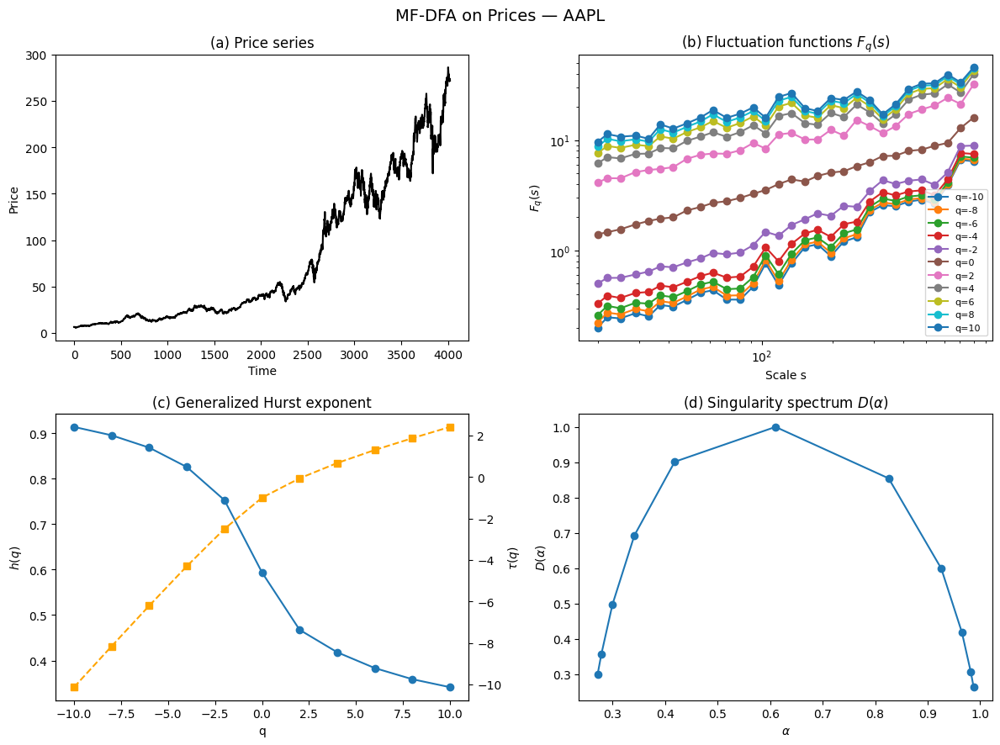

Processing MSFT...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\2337839134.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


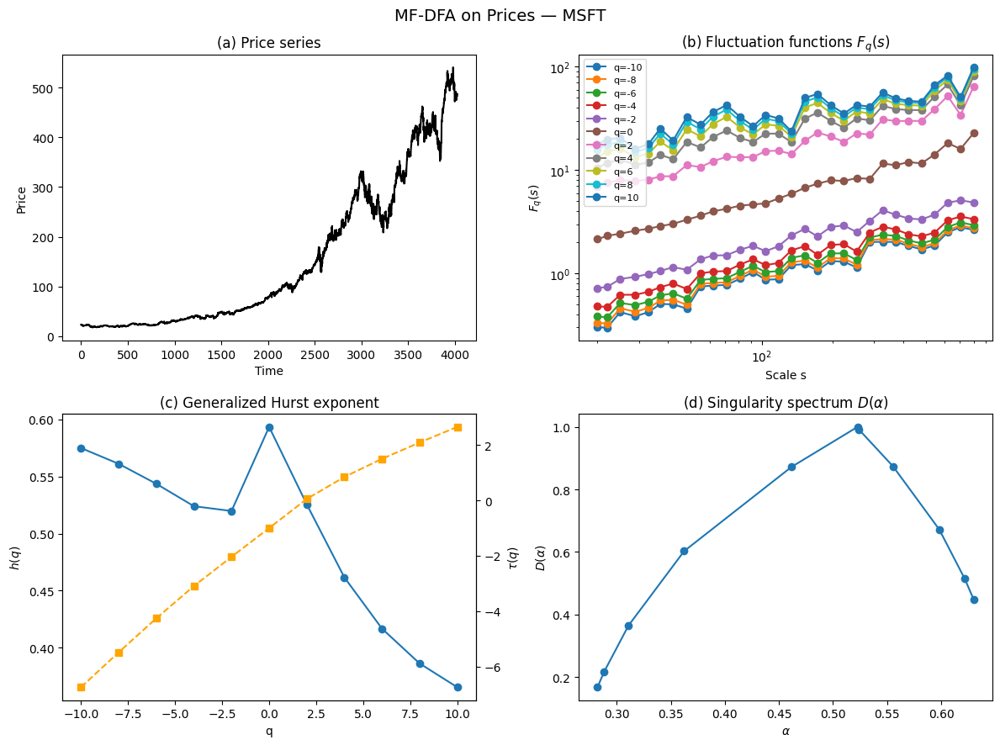

Processing GOOG...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\2337839134.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


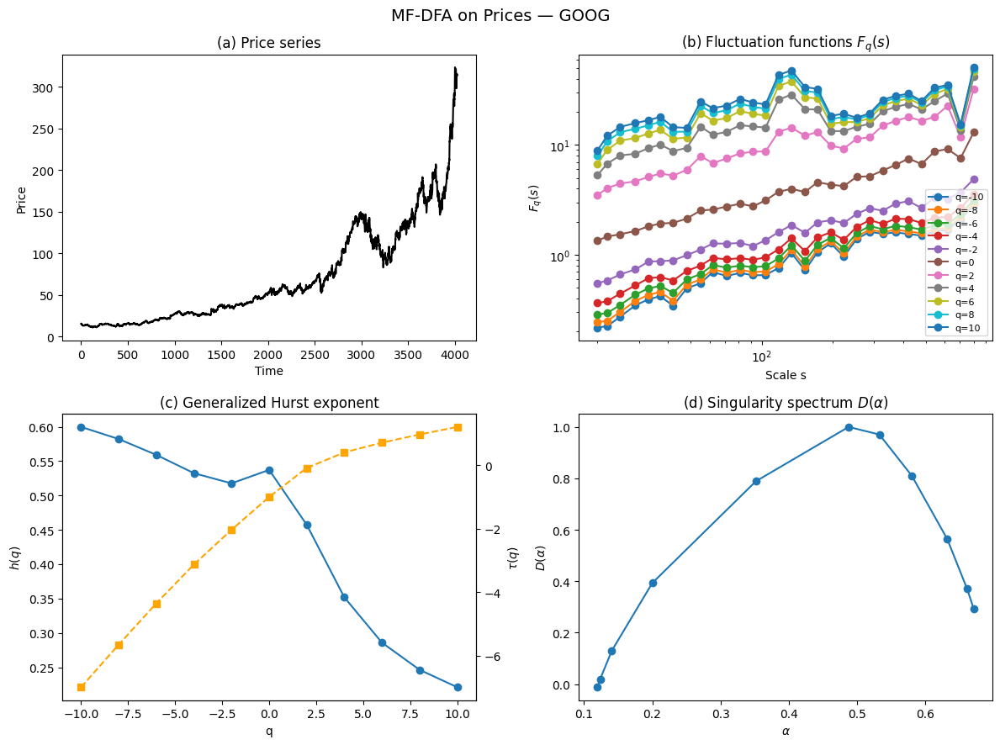

Processing TSLA...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\2337839134.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


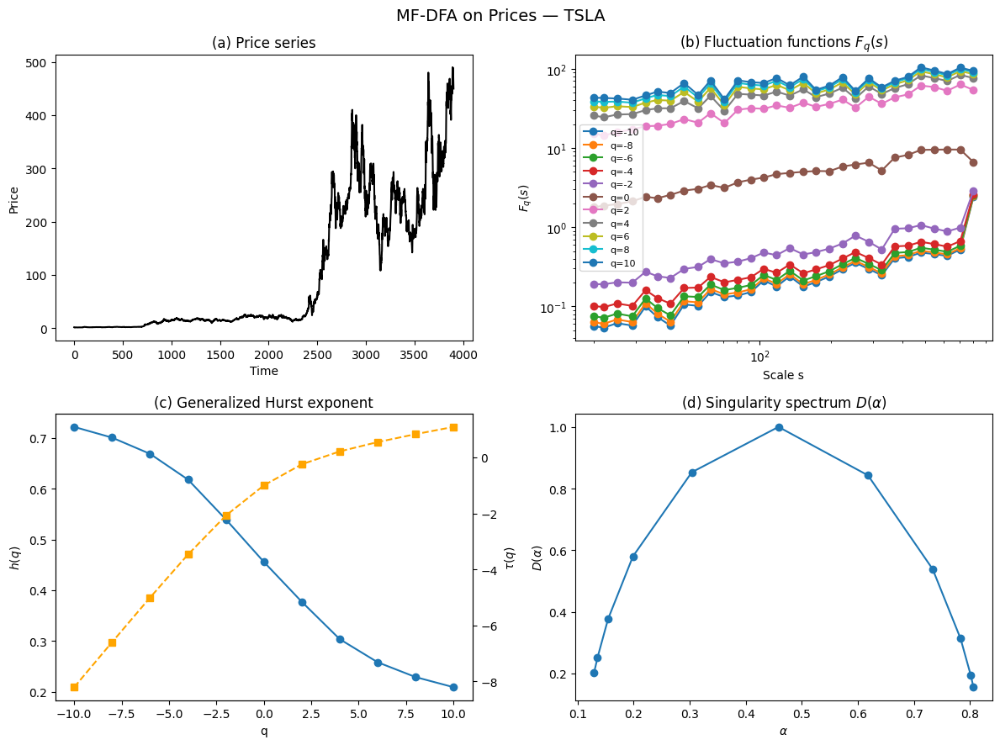

Processing AMZN...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\2337839134.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


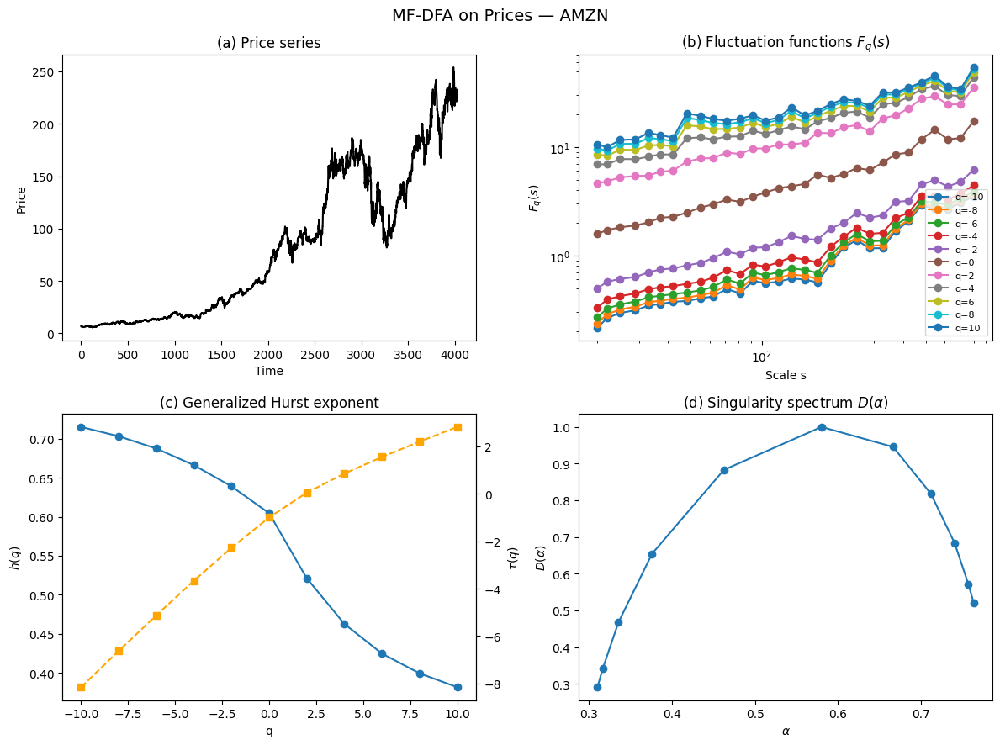

Processing GC=F...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\2337839134.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


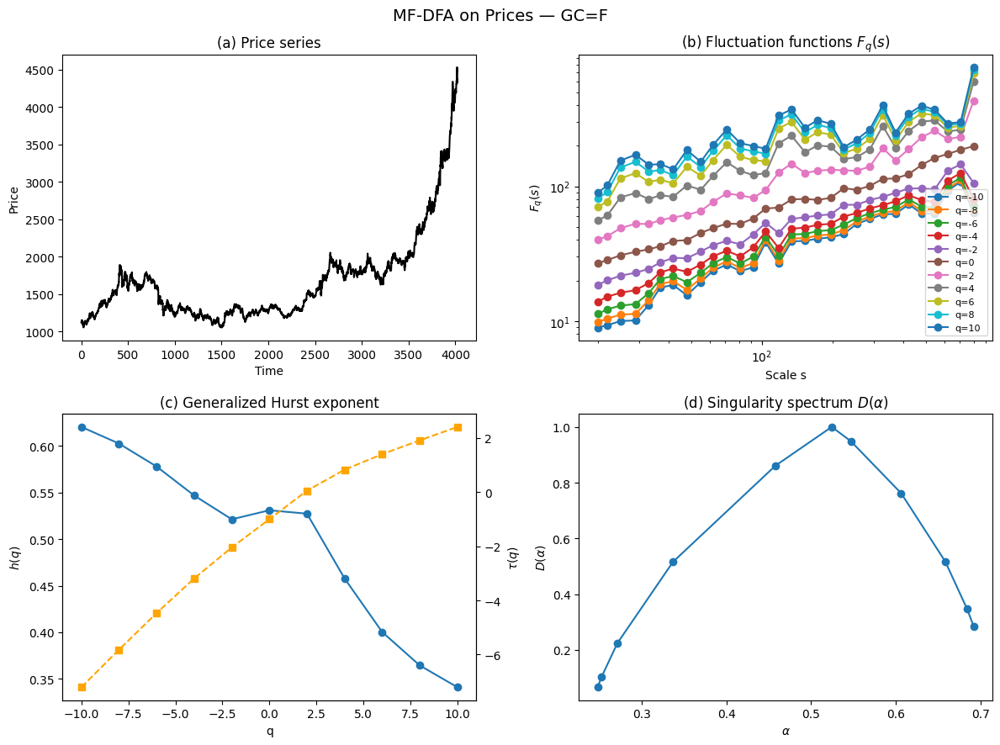

Processing BTC-USD...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\2337839134.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


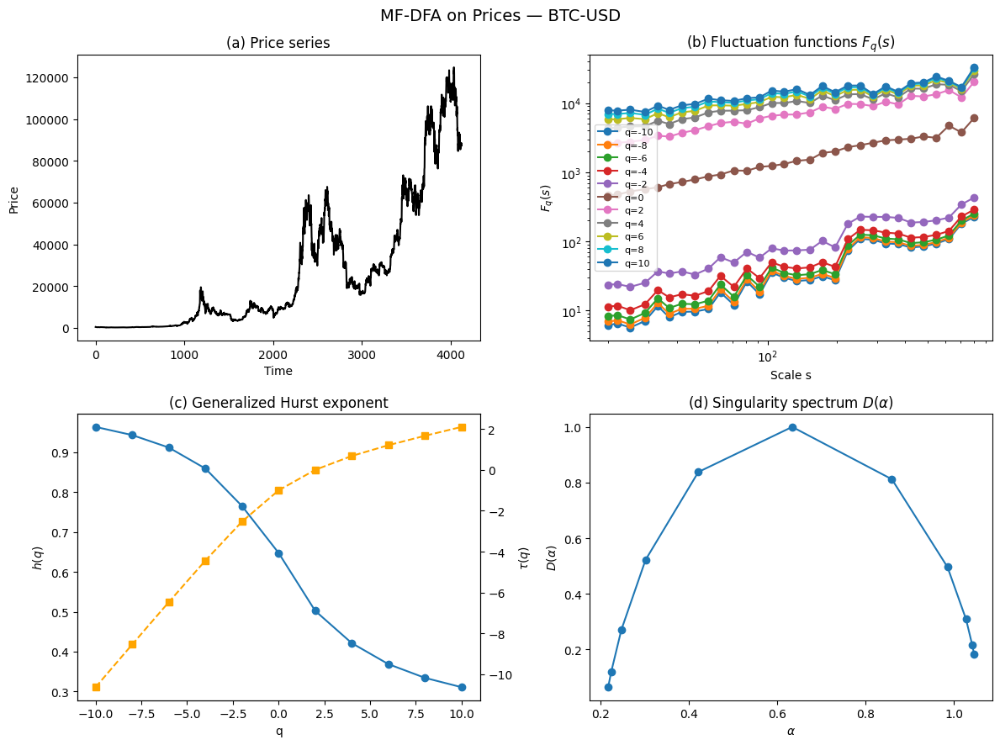

In [22]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# =====================================
# PARAMETERS
# =====================================
tickers = ["AAPL", "MSFT", "GOOG", "TSLA", "AMZN","GC=F","BTC-USD"]
start = "2010-01-01"
end = "2026-01-01"

q_vals = np.arange(-10, 12, 2)
scale_min = 20
scale_max = 800
n_scales = 30

# =====================================
# MF-DFA FOR PRICES (NO INTEGRATION)
# =====================================
def mfdfa_prices(x, q_vals, scale_min, scale_max, n_scales):
    scales = np.unique(
        np.logspace(np.log10(scale_min), np.log10(scale_max), n_scales).astype(int)
    )

    Fqs = np.zeros((len(q_vals), len(scales)))

    for i, s in enumerate(scales):
        Ns = len(x) // s
        rms = []

        for v in range(Ns):
            seg = x[v*s:(v+1)*s]
            t = np.arange(s)
            p = np.polyfit(t, seg, 1)
            trend = np.polyval(p, t)
            rms.append(np.sqrt(np.mean((seg - trend)**2)))

        rms = np.array(rms)
        rms = rms[rms > 0]

        for j, q in enumerate(q_vals):
            if q == 0:
                Fqs[j, i] = np.exp(0.5 * np.mean(np.log(rms**2)))
            else:
                Fqs[j, i] = (np.mean(rms**q))**(1/q)

    hq = np.array([
        np.polyfit(np.log(scales), np.log(Fqs[j]), 1)[0]
        for j in range(len(q_vals))
    ])

    return scales, Fqs, hq

# =====================================
# LOOP OVER STOCKS
# =====================================
for ticker in tickers:
    print(f"Processing {ticker}...")

    data = yf.download(ticker, start=start, end=end, progress=False)
    price = data["Close"].dropna().values

    scales, Fqs, hq = mfdfa_prices(
        price, q_vals, scale_min, scale_max, n_scales
    )

    # Multifractal exponents
    tau_q = hq * q_vals - 1
    alpha = np.gradient(tau_q, q_vals)
    D_alpha = q_vals * alpha - tau_q

    # =====================================
    # PLOTS (4-panel like the paper)
    # =====================================
    fig, axs = plt.subplots(2, 2, figsize=(12, 9))
    fig.suptitle(f"MF-DFA on Prices — {ticker}", fontsize=14)

    # (a) Price series
    axs[0, 0].plot(price, color="black")
    axs[0, 0].set_title("(a) Price series")
    axs[0, 0].set_xlabel("Time")
    axs[0, 0].set_ylabel("Price")

    # (b) F_q(s) vs s
    for q in np.arange(-10, 12, 2):
        idx = np.where(q_vals == q)[0][0]
        axs[0, 1].loglog(scales, Fqs[idx], 'o-', label=f"q={q}")

    axs[0, 1].set_title("(b) Fluctuation functions $F_q(s)$")
    axs[0, 1].set_xlabel("Scale s")
    axs[0, 1].set_ylabel("$F_q(s)$")
    axs[0, 1].legend(fontsize=8)

    # (c) h(q) and tau(q)
    axs[1, 0].plot(q_vals, hq, 'o-', label="$h(q)$")
    axs[1, 0].set_title("(c) Generalized Hurst exponent")
    axs[1, 0].set_xlabel("q")
    axs[1, 0].set_ylabel("$h(q)$")

    ax2 = axs[1, 0].twinx()
    ax2.plot(q_vals, tau_q, 's--', color="orange", label=r"$\tau(q)$")
    ax2.set_ylabel(r"$\tau(q)$")

    # (d) Singularity spectrum
    axs[1, 1].plot(alpha, D_alpha, 'o-')
    axs[1, 1].set_title("(d) Singularity spectrum $D(\\alpha)$")
    axs[1, 1].set_xlabel(r"$\alpha$")
    axs[1, 1].set_ylabel(r"$D(\alpha)$")

    plt.tight_layout()
    plt.show()


Processing AAPL...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\94916369.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


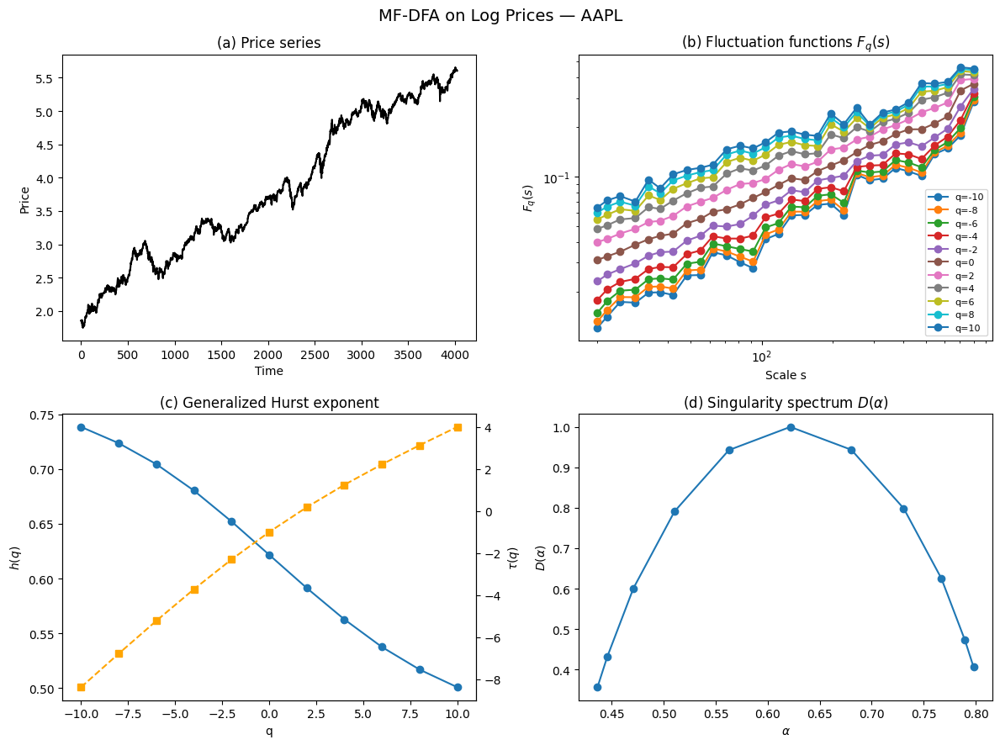

Processing MSFT...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\94916369.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


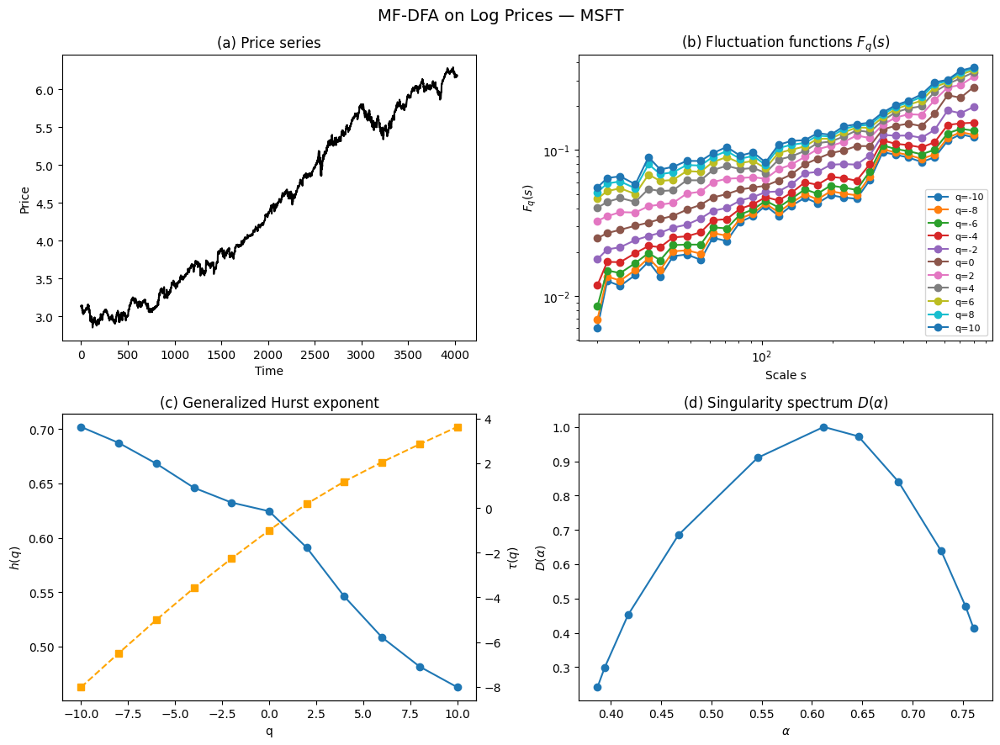

Processing GOOG...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\94916369.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


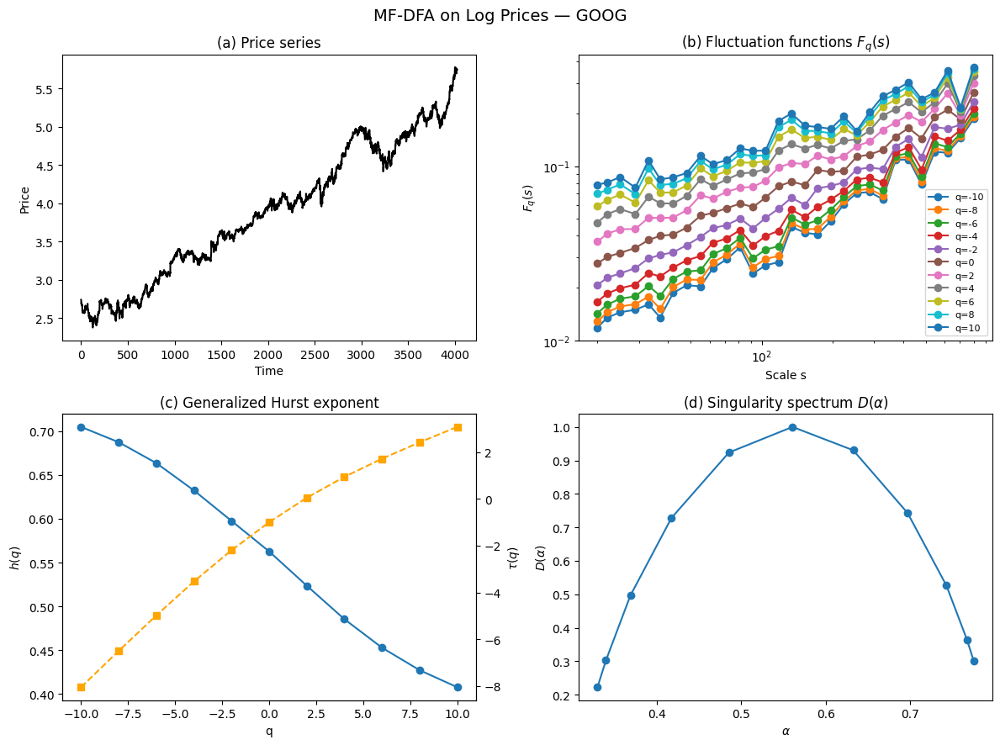

Processing TSLA...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\94916369.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


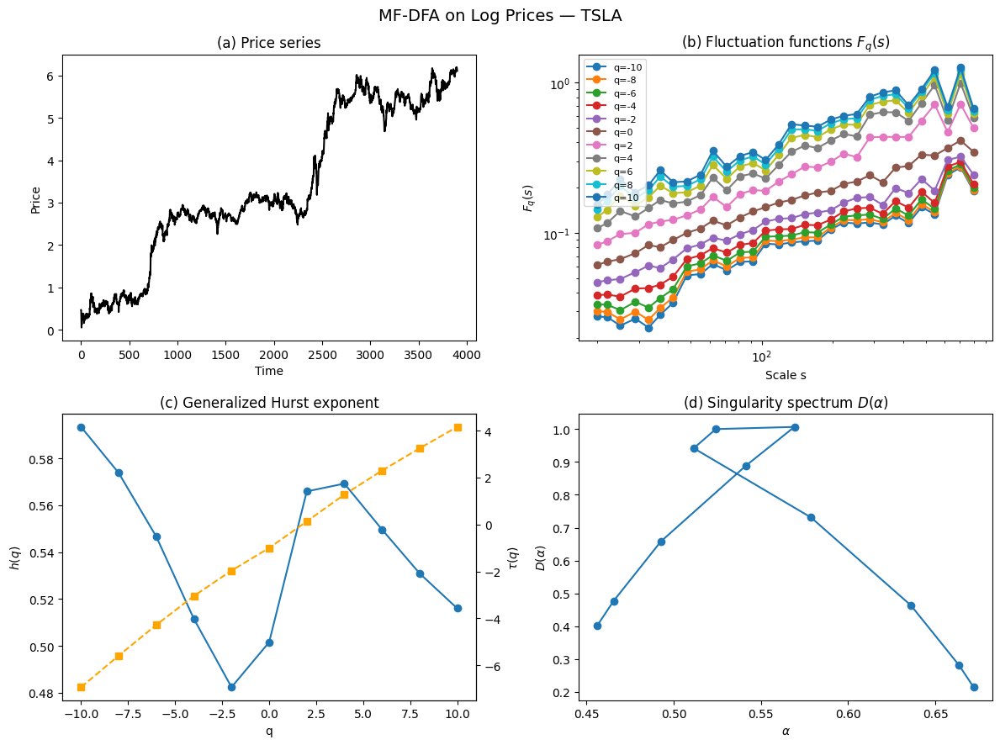

Processing AMZN...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\94916369.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


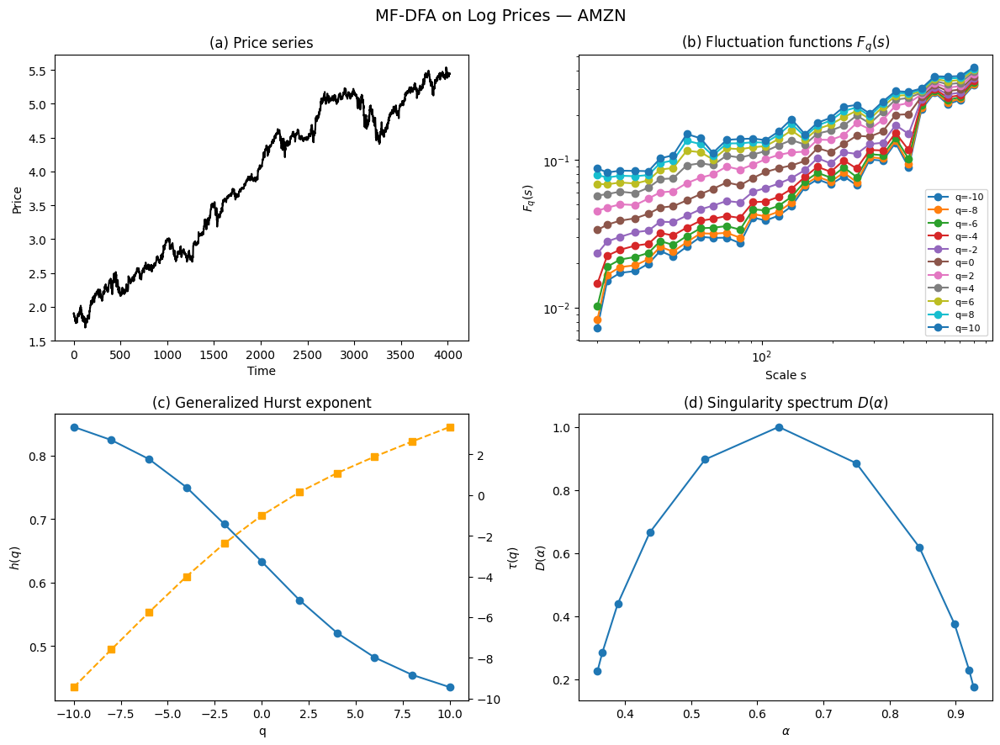

Processing GC=F...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\94916369.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


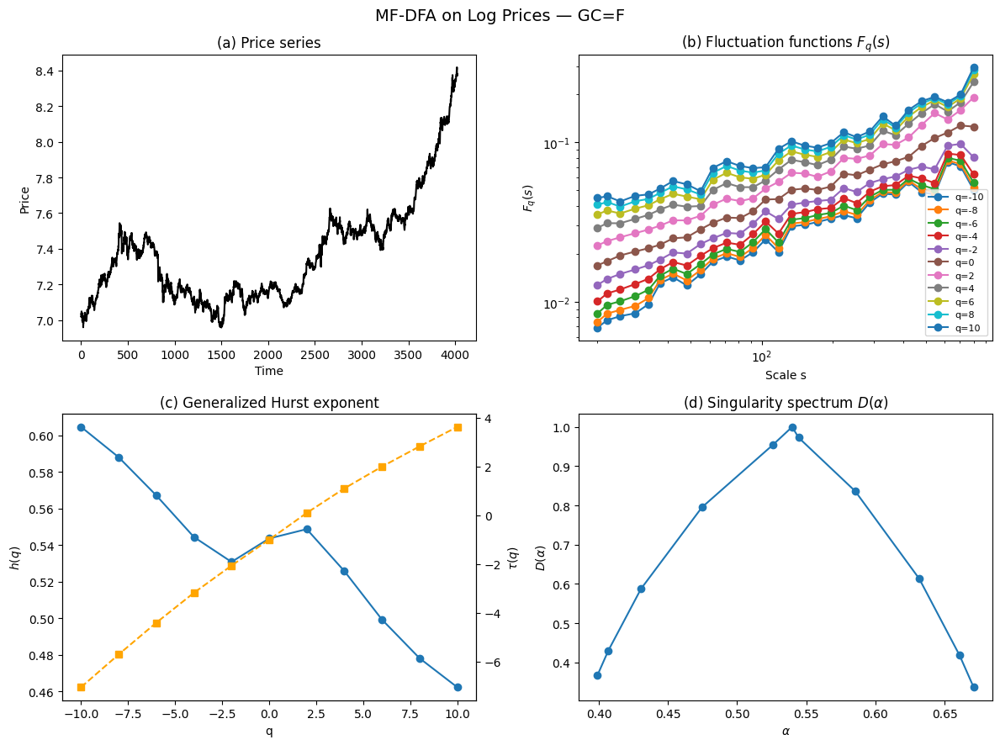

Processing BTC-USD...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\94916369.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


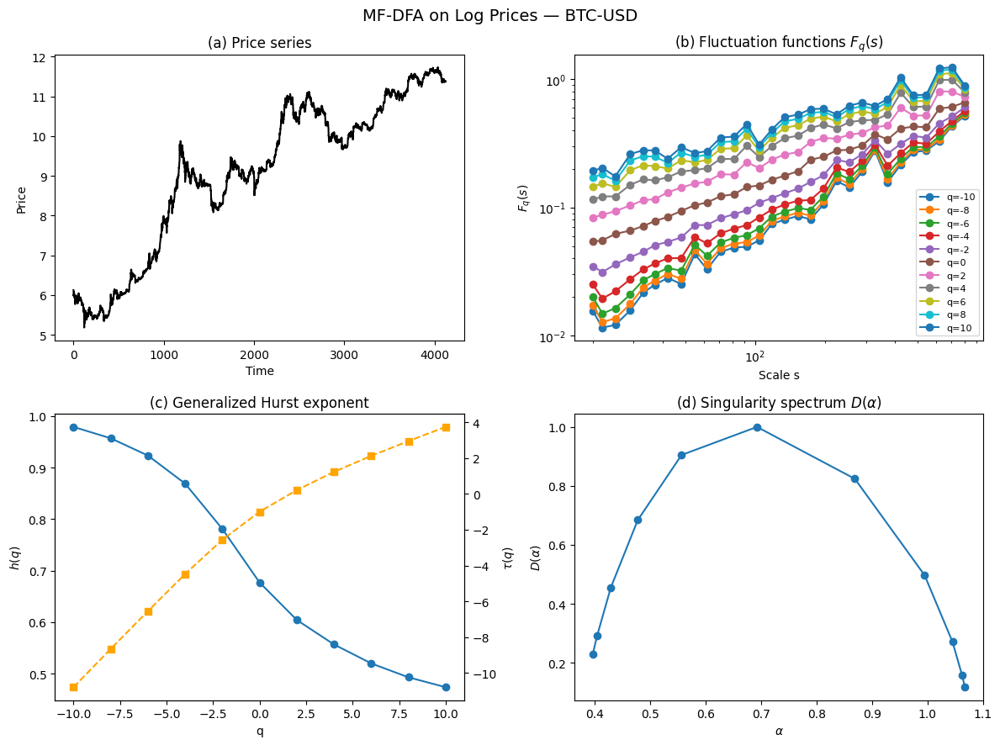

In [23]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# =====================================
# PARAMETERS
# =====================================
tickers = ["AAPL", "MSFT", "GOOG", "TSLA", "AMZN","GC=F","BTC-USD"]
start = "2010-01-01"
end = "2026-01-01"

q_vals = np.arange(-10, 12, 2)
scale_min = 20
scale_max = 800
n_scales = 30

# =====================================
# MF-DFA FOR PRICES (NO INTEGRATION)
# =====================================
def mfdfa_prices(x, q_vals, scale_min, scale_max, n_scales):
    scales = np.unique(
        np.logspace(np.log10(scale_min), np.log10(scale_max), n_scales).astype(int)
    )

    Fqs = np.zeros((len(q_vals), len(scales)))

    for i, s in enumerate(scales):
        Ns = len(x) // s
        rms = []

        for v in range(Ns):
            seg = x[v*s:(v+1)*s]
            t = np.arange(s)
            p = np.polyfit(t, seg, 1)
            trend = np.polyval(p, t)
            rms.append(np.sqrt(np.mean((seg - trend)**2)))

        rms = np.array(rms)
        rms = rms[rms > 0]

        for j, q in enumerate(q_vals):
            if q == 0:
                Fqs[j, i] = np.exp(0.5 * np.mean(np.log(rms**2)))
            else:
                Fqs[j, i] = (np.mean(rms**q))**(1/q)

    hq = np.array([
        np.polyfit(np.log(scales), np.log(Fqs[j]), 1)[0]
        for j in range(len(q_vals))
    ])

    return scales, Fqs, hq

# =====================================
# LOOP OVER STOCKS
# =====================================
for ticker in tickers:
    print(f"Processing {ticker}...")

    data = yf.download(ticker, start=start, end=end, progress=False)
    price = np.log(data["Close"].dropna().values)

    scales, Fqs, hq = mfdfa_prices(
        price, q_vals, scale_min, scale_max, n_scales
    )

    # Multifractal exponents
    tau_q = hq * q_vals - 1
    alpha = np.gradient(tau_q, q_vals)
    D_alpha = q_vals * alpha - tau_q

    # =====================================
    # PLOTS (4-panel like the paper)
    # =====================================
    fig, axs = plt.subplots(2, 2, figsize=(12, 9))
    fig.suptitle(f"MF-DFA on Log Prices — {ticker}", fontsize=14)

    # (a) Price series
    axs[0, 0].plot(price, color="black")
    axs[0, 0].set_title("(a) Price series")
    axs[0, 0].set_xlabel("Time")
    axs[0, 0].set_ylabel("Price")

    # (b) F_q(s) vs s
    for q in np.arange(-10, 12, 2):
        idx = np.where(q_vals == q)[0][0]
        axs[0, 1].loglog(scales, Fqs[idx], 'o-', label=f"q={q}")

    axs[0, 1].set_title("(b) Fluctuation functions $F_q(s)$")
    axs[0, 1].set_xlabel("Scale s")
    axs[0, 1].set_ylabel("$F_q(s)$")
    axs[0, 1].legend(fontsize=8)

    # (c) h(q) and tau(q)
    axs[1, 0].plot(q_vals, hq, 'o-', label="$h(q)$")
    axs[1, 0].set_title("(c) Generalized Hurst exponent")
    axs[1, 0].set_xlabel("q")
    axs[1, 0].set_ylabel("$h(q)$")

    ax2 = axs[1, 0].twinx()
    ax2.plot(q_vals, tau_q, 's--', color="orange", label=r"$\tau(q)$")
    ax2.set_ylabel(r"$\tau(q)$")

    # (d) Singularity spectrum
    axs[1, 1].plot(alpha, D_alpha, 'o-')
    axs[1, 1].set_title("(d) Singularity spectrum $D(\\alpha)$")
    axs[1, 1].set_xlabel(r"$\alpha$")
    axs[1, 1].set_ylabel(r"$D(\alpha)$")

    plt.tight_layout()
    plt.show()



Processing AAPL...
  → MF-DFA


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\4082000857.py:118: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


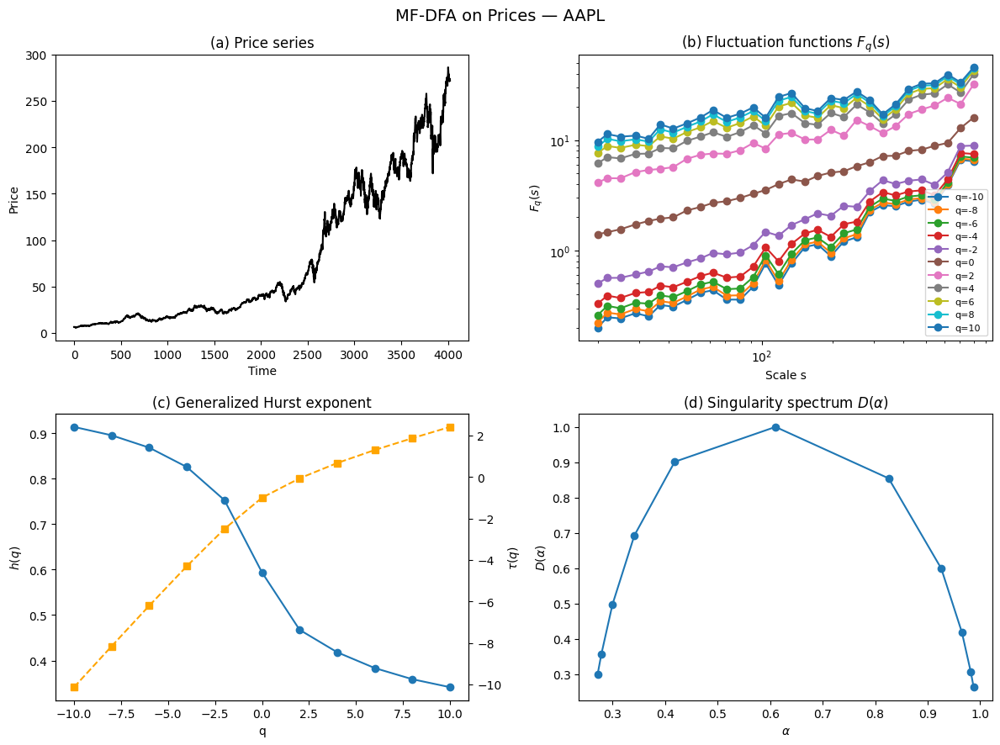

  → MF-BDMA


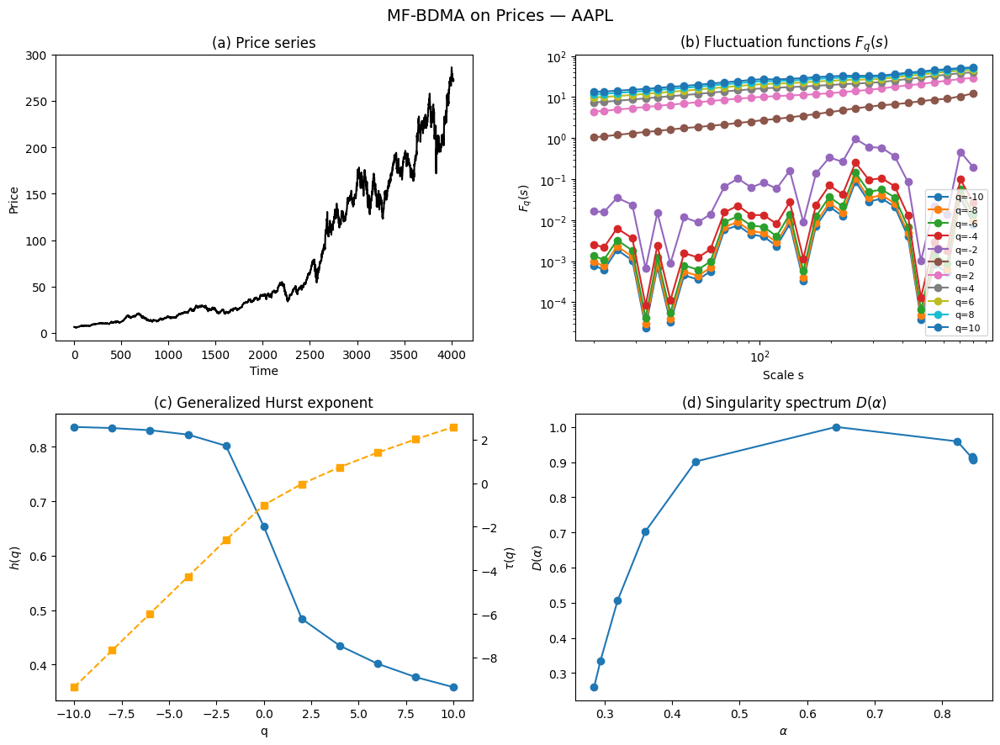

  → MF-CDMA


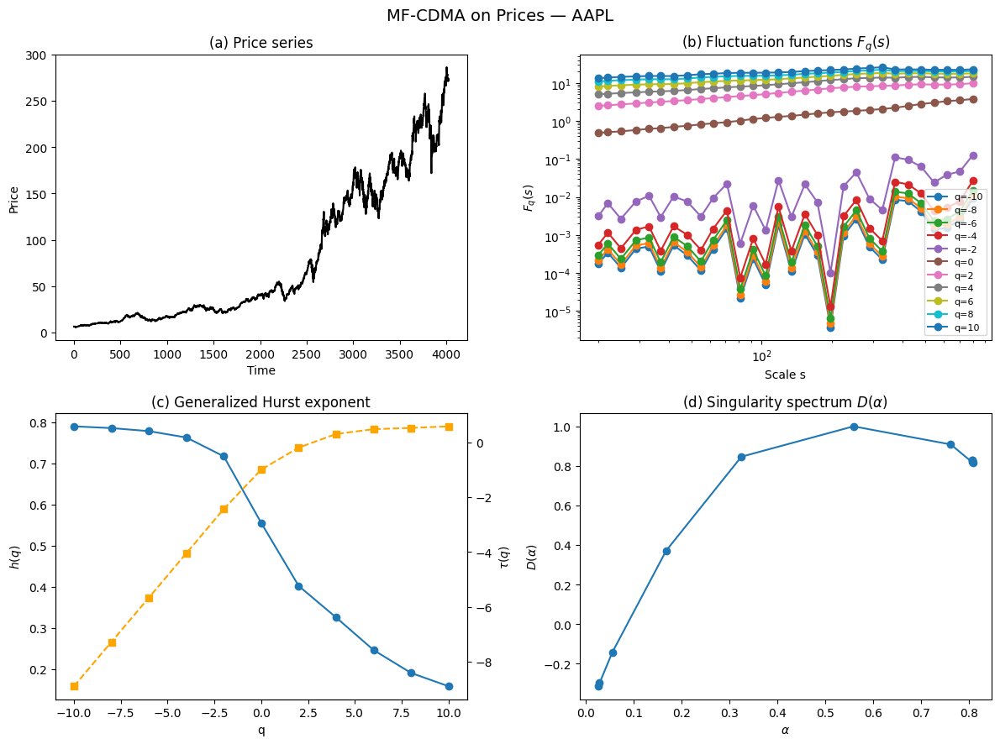

  → MF-FDMA


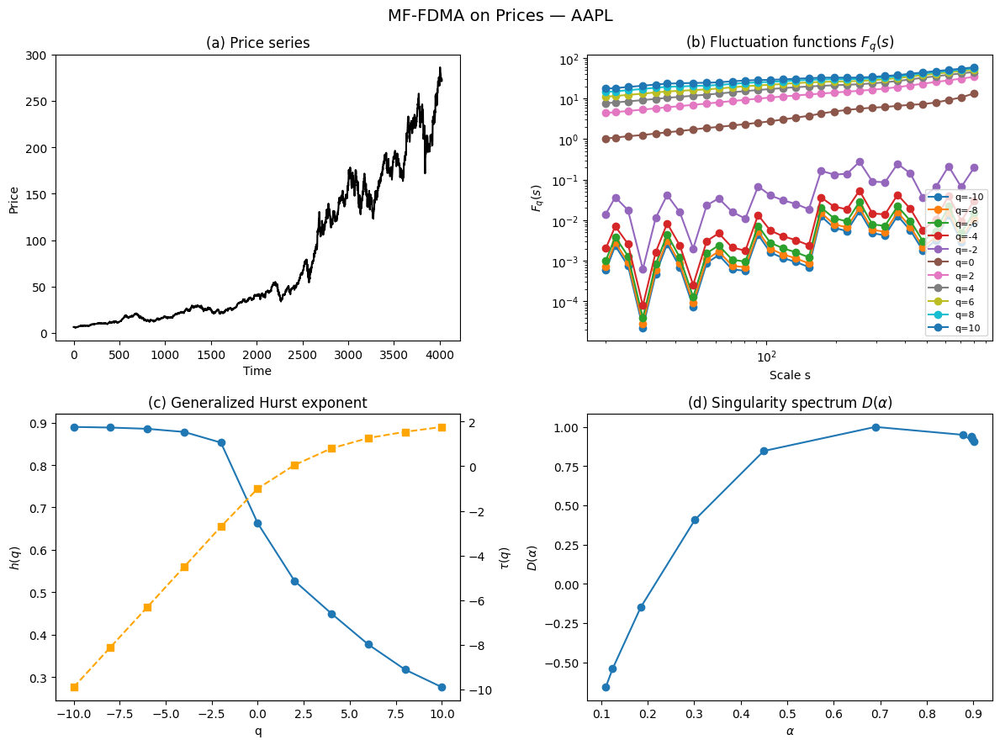


Processing MSFT...
  → MF-DFA


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\4082000857.py:118: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


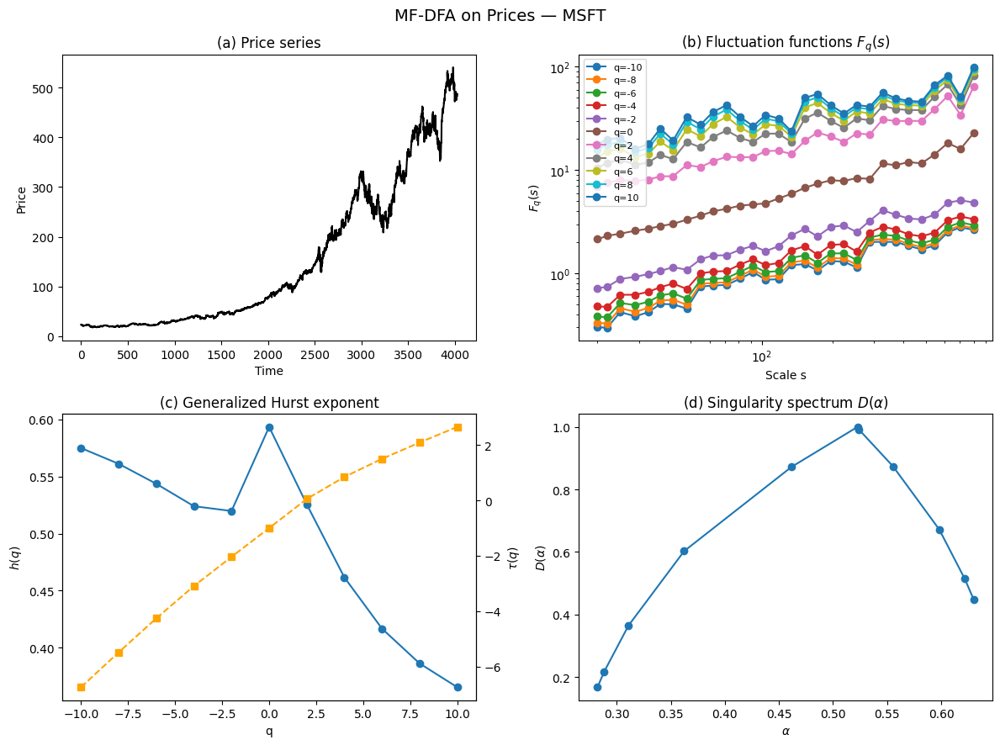

  → MF-BDMA


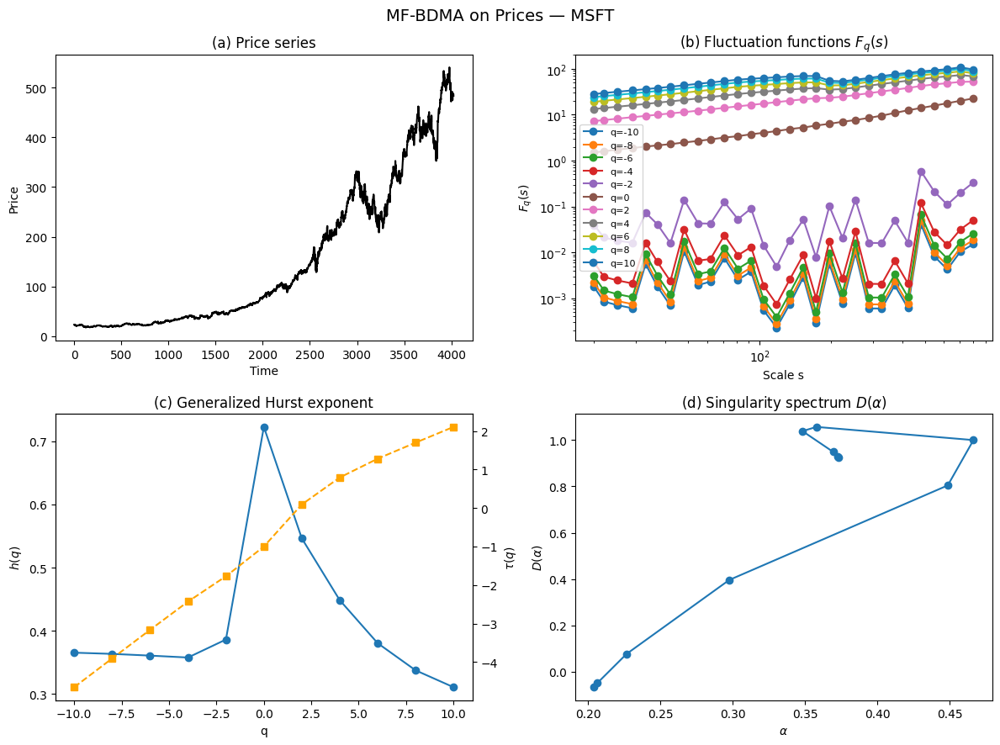

  → MF-CDMA


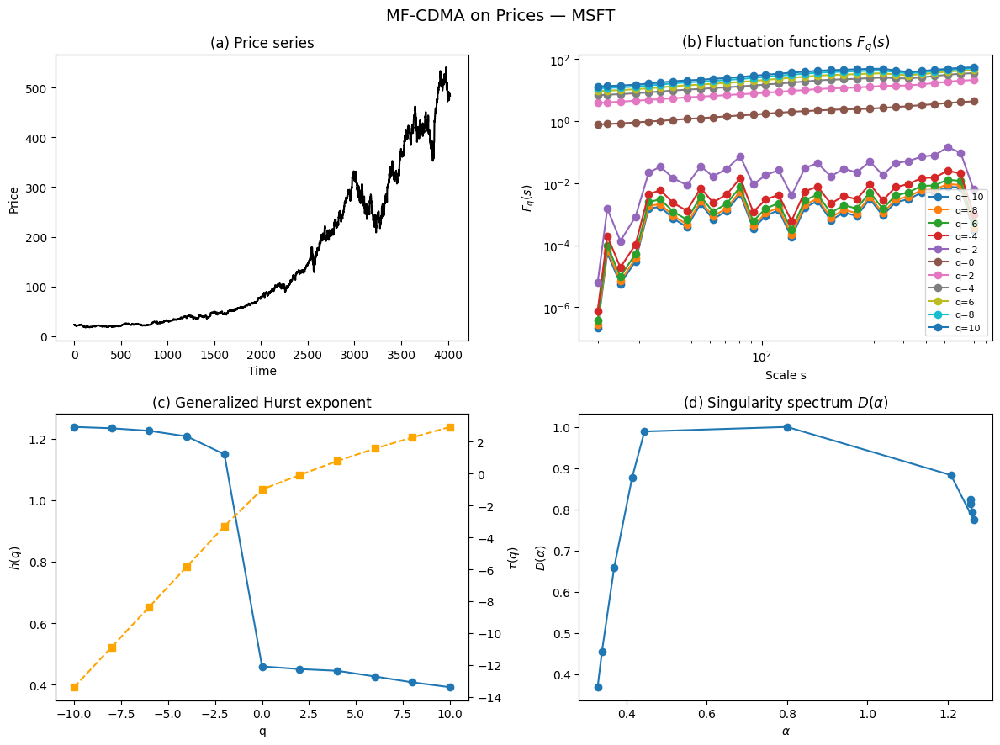

  → MF-FDMA


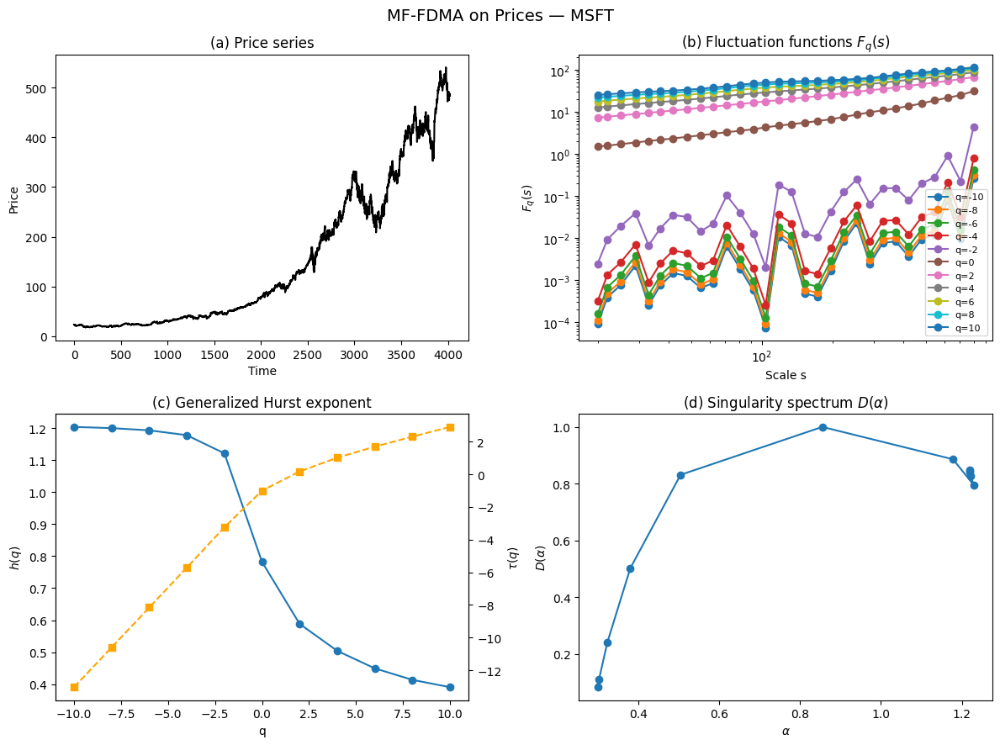


Processing GOOG...
  → MF-DFA


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\4082000857.py:118: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


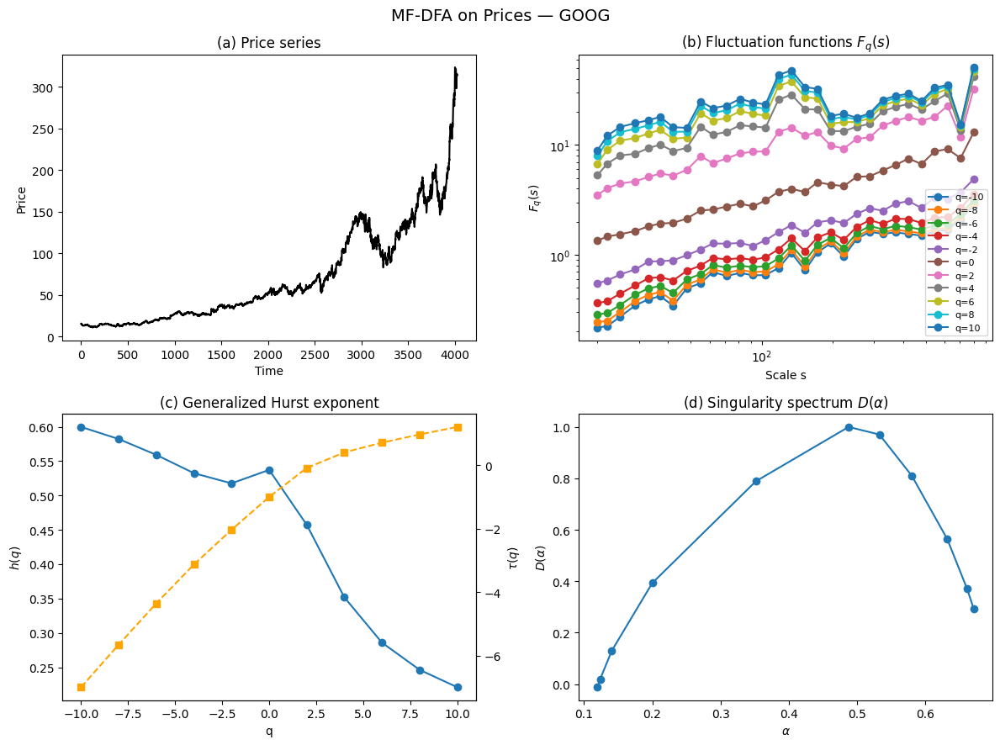

  → MF-BDMA


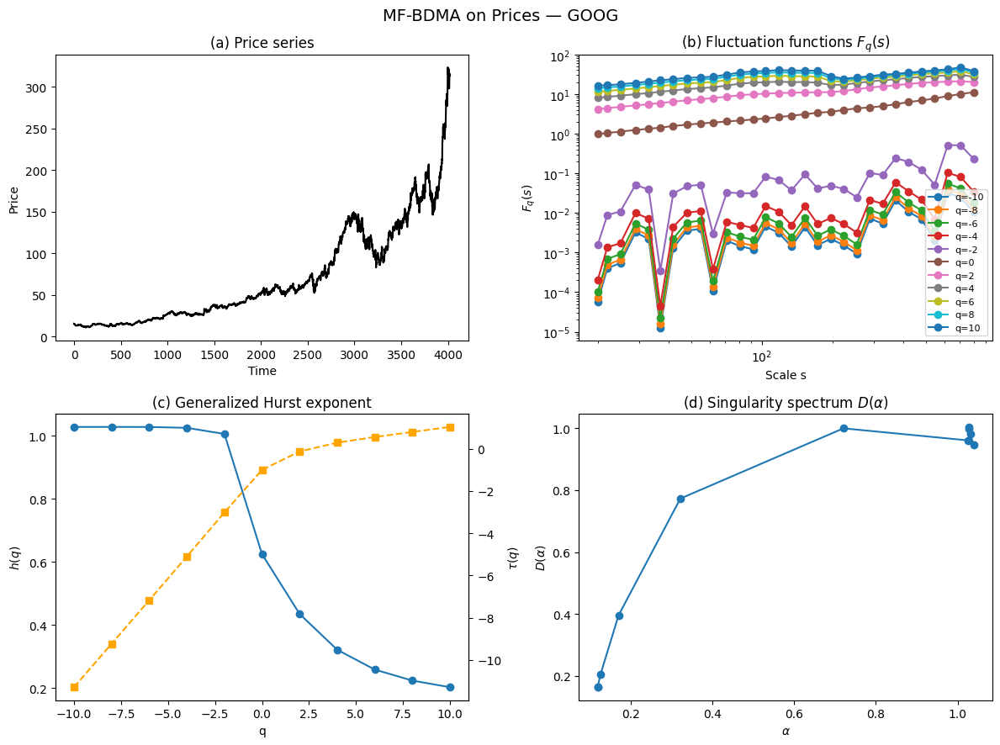

  → MF-CDMA


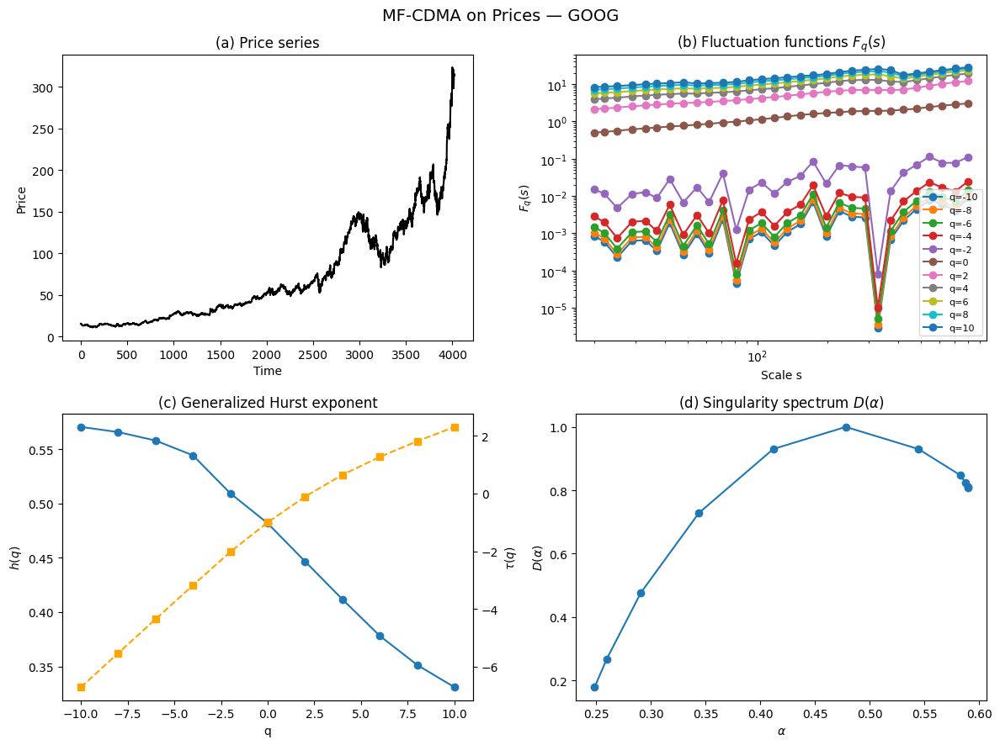

  → MF-FDMA


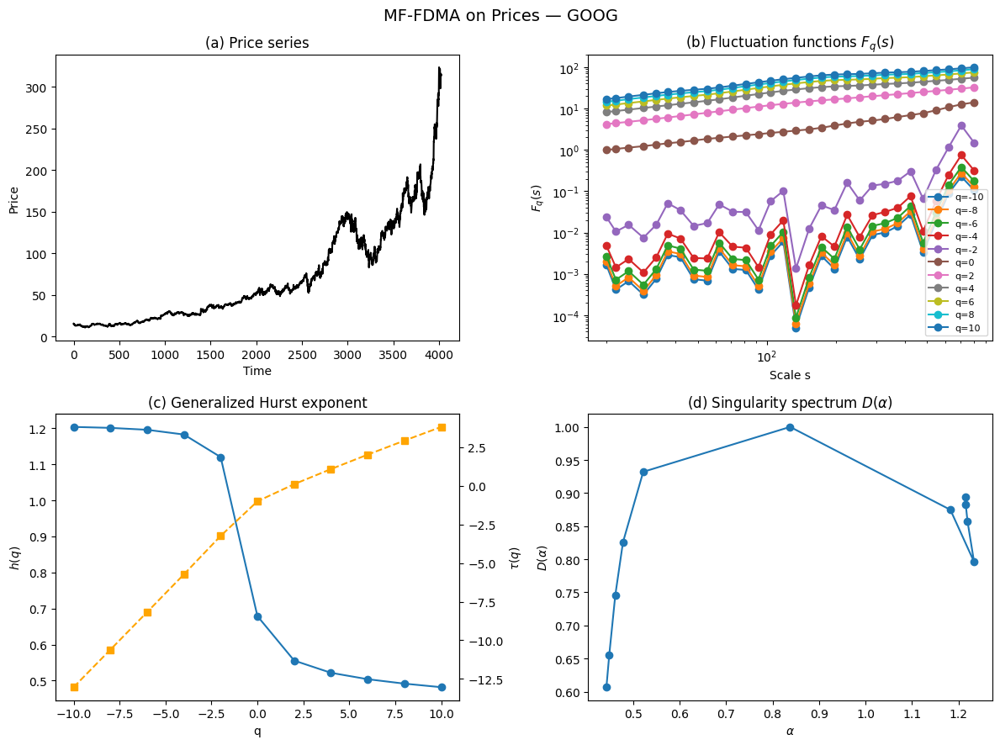


Processing TSLA...
  → MF-DFA


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\4082000857.py:118: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


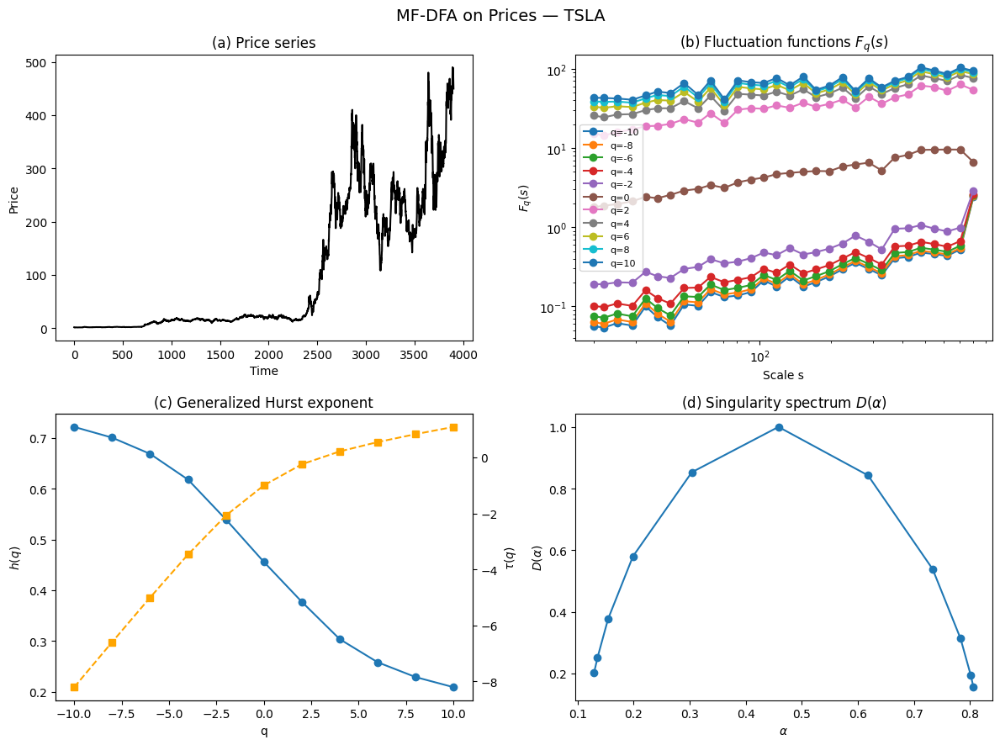

  → MF-BDMA


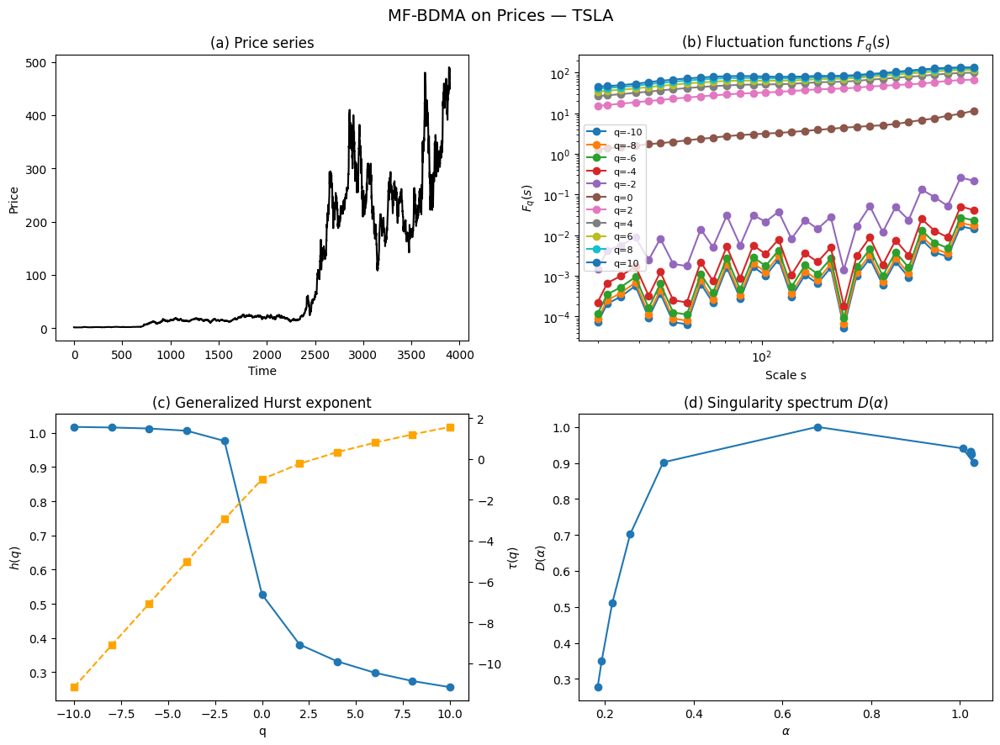

  → MF-CDMA


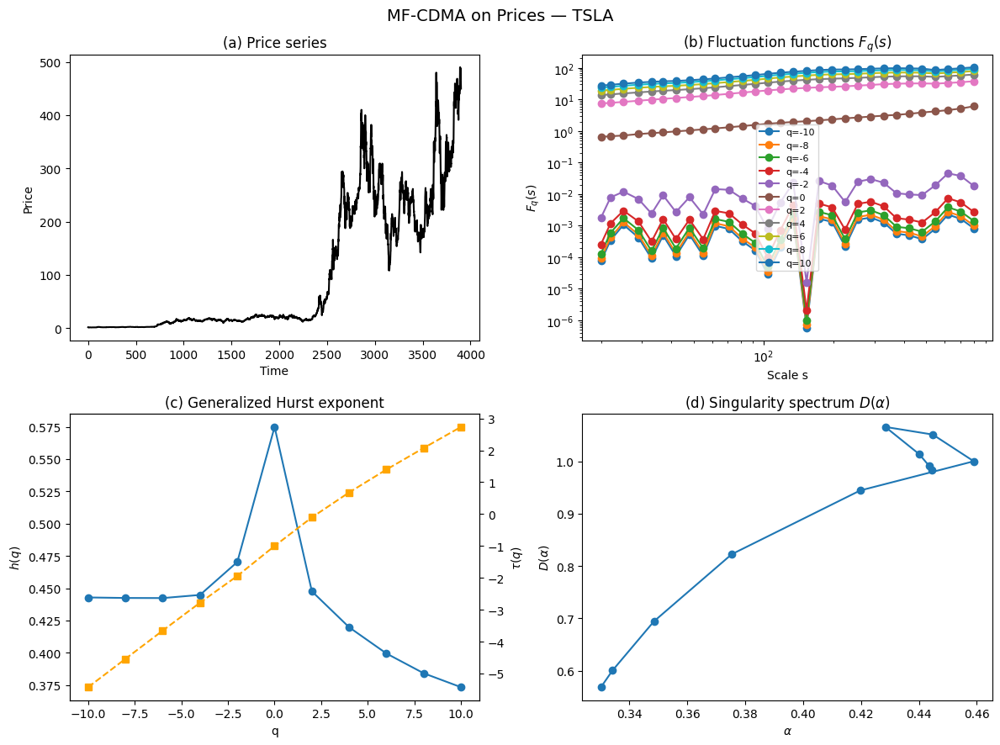

  → MF-FDMA


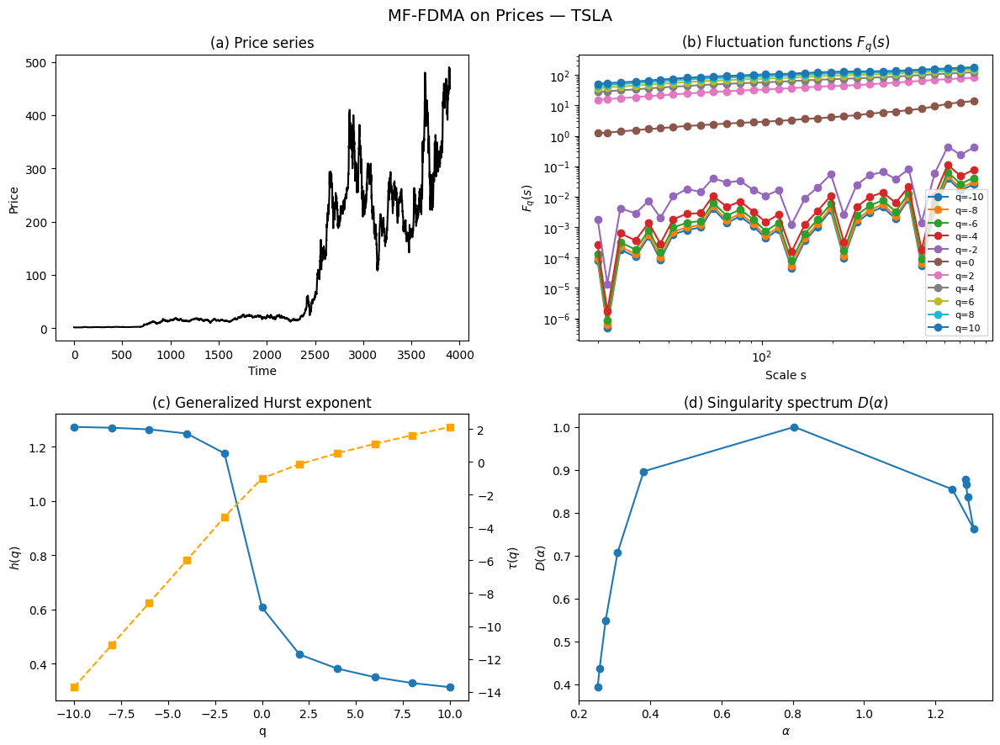


Processing AMZN...
  → MF-DFA


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\4082000857.py:118: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


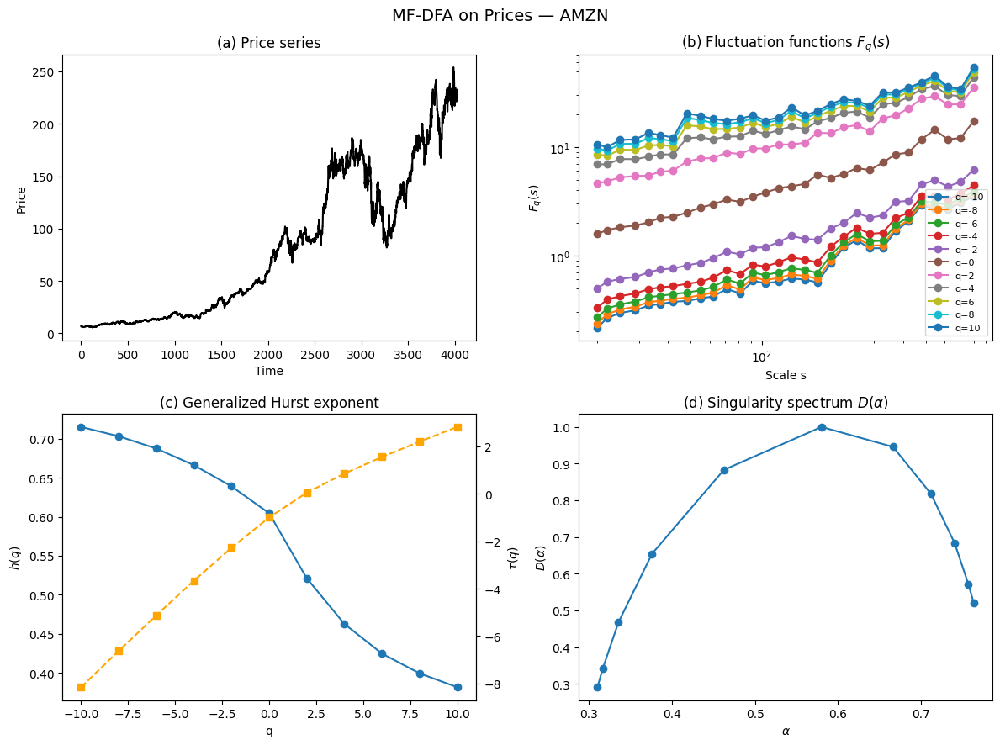

  → MF-BDMA


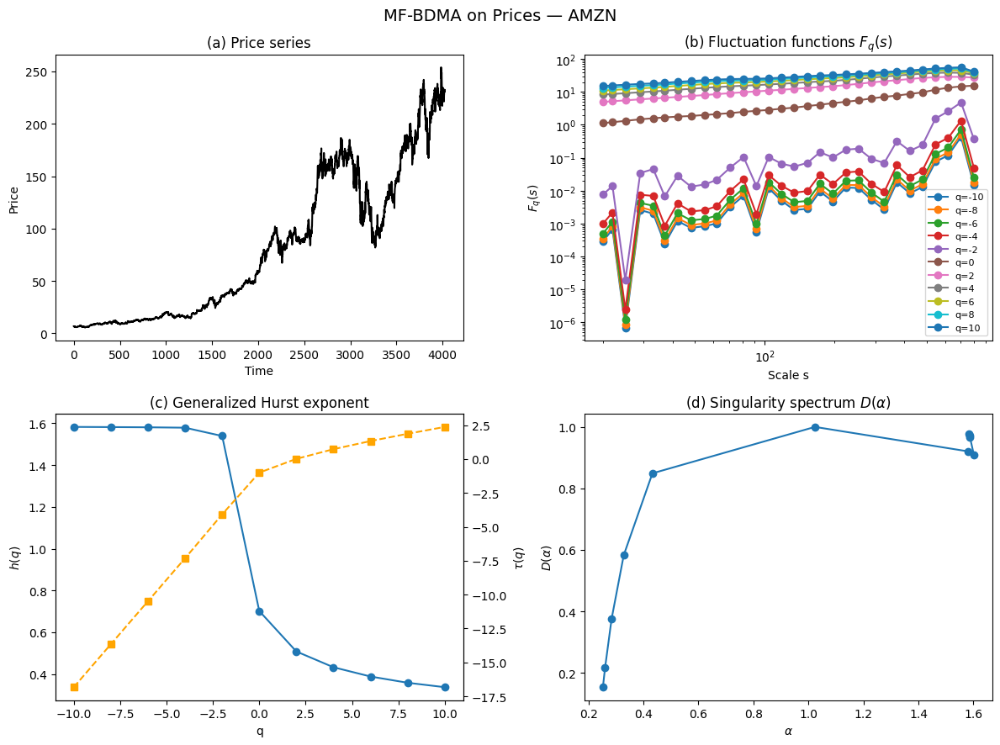

  → MF-CDMA


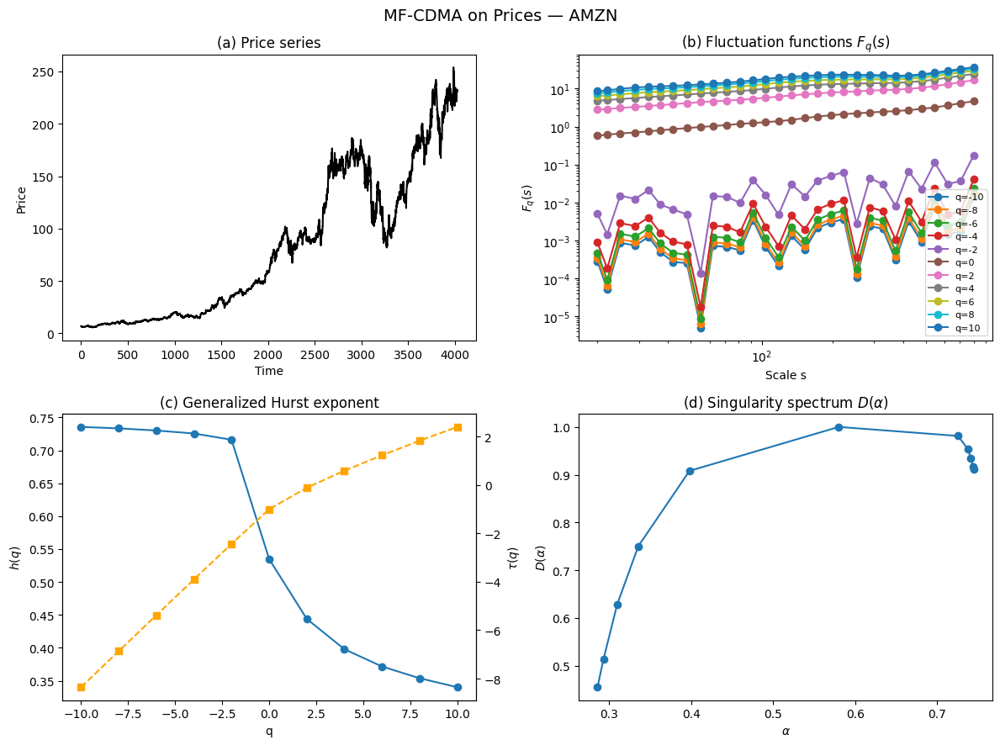

  → MF-FDMA


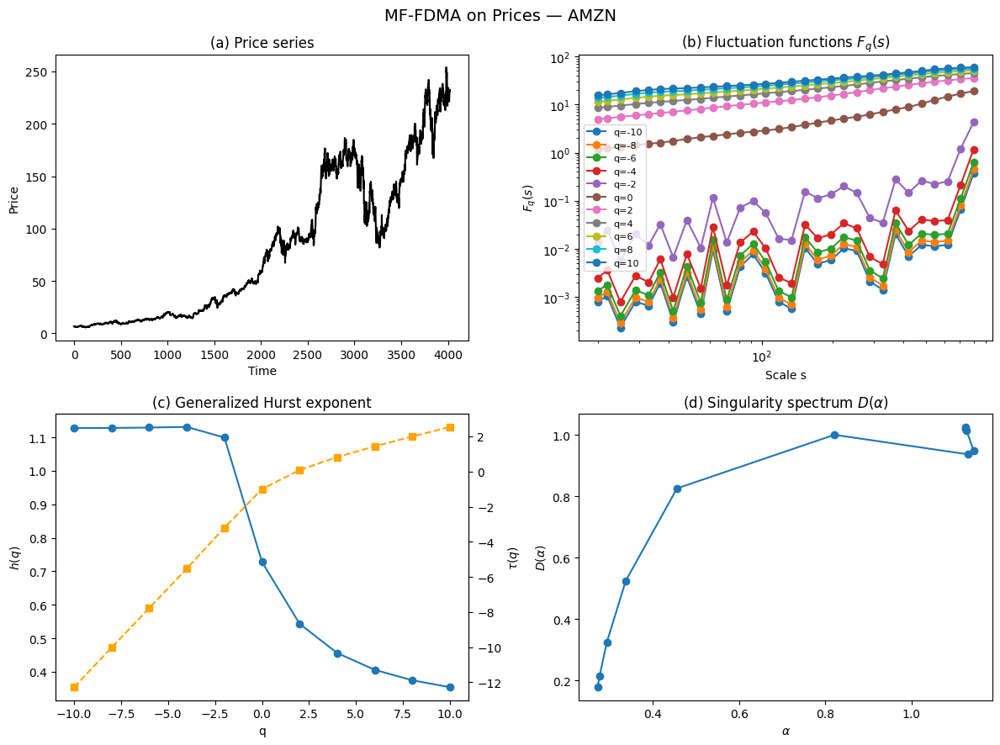


Processing GC=F...
  → MF-DFA


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\4082000857.py:118: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


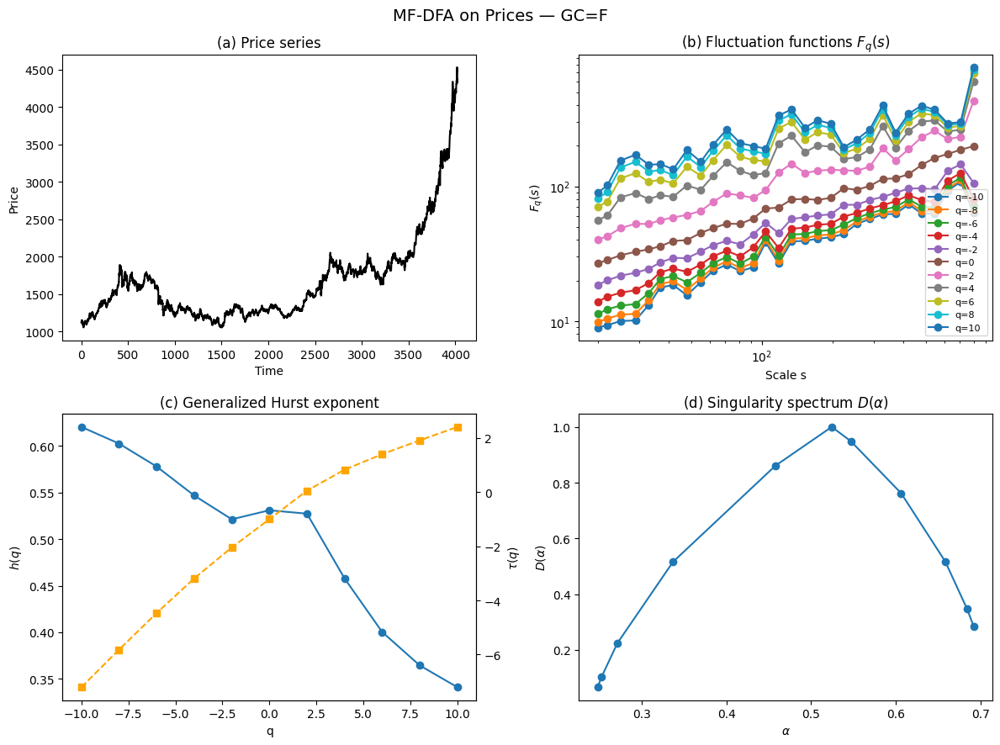

  → MF-BDMA


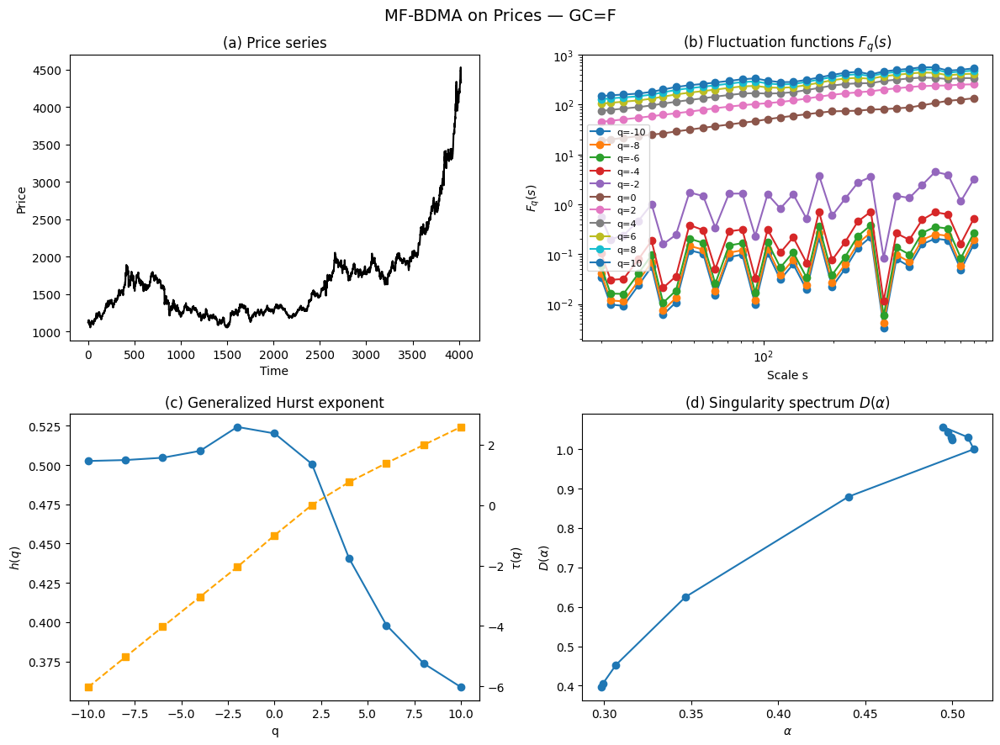

  → MF-CDMA


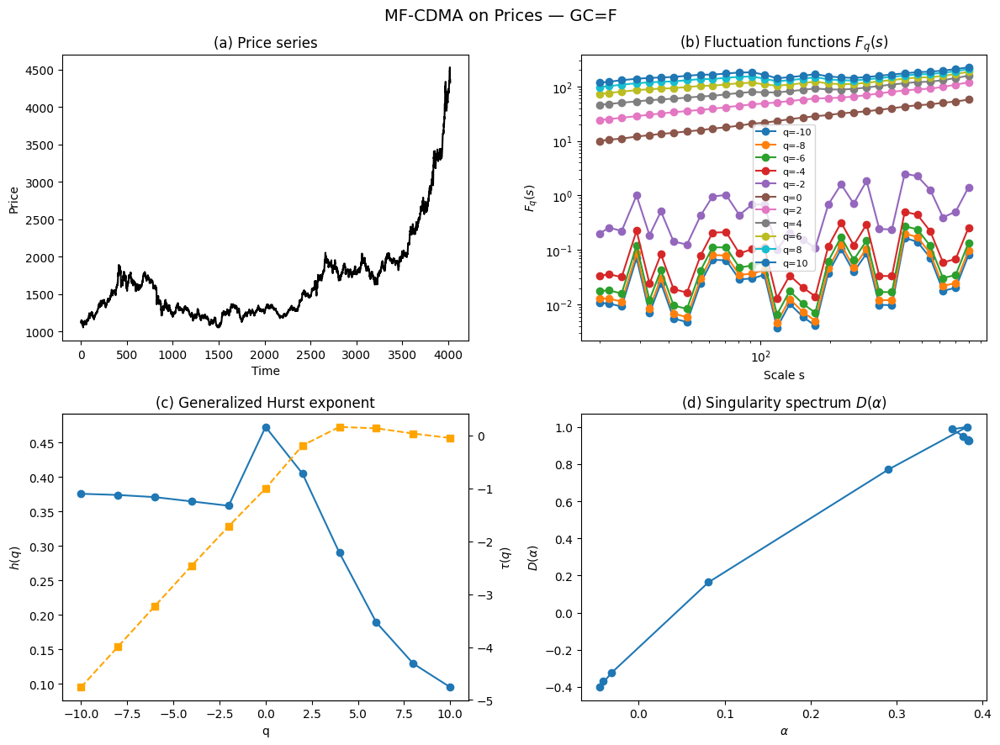

  → MF-FDMA


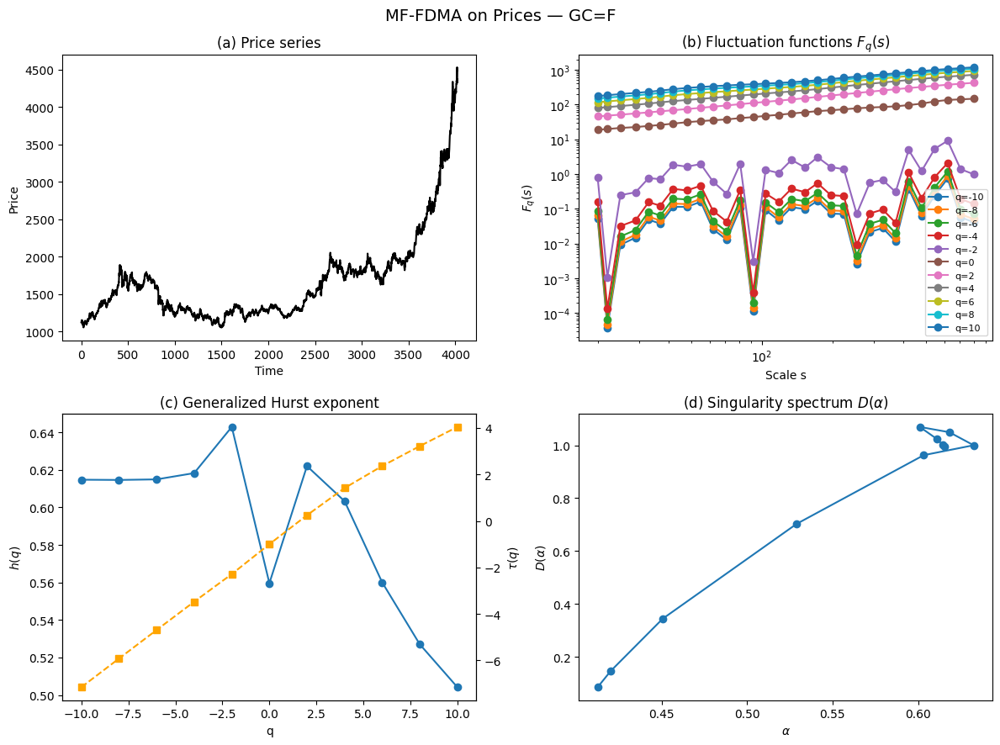


Processing BTC-USD...
  → MF-DFA


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\4082000857.py:118: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


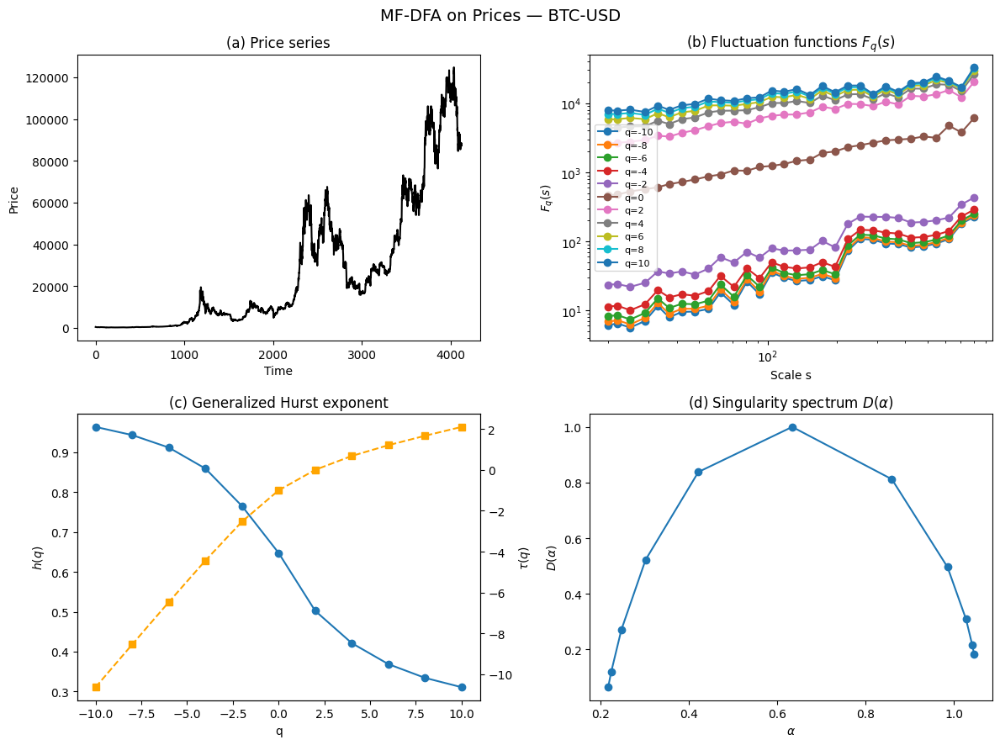

  → MF-BDMA


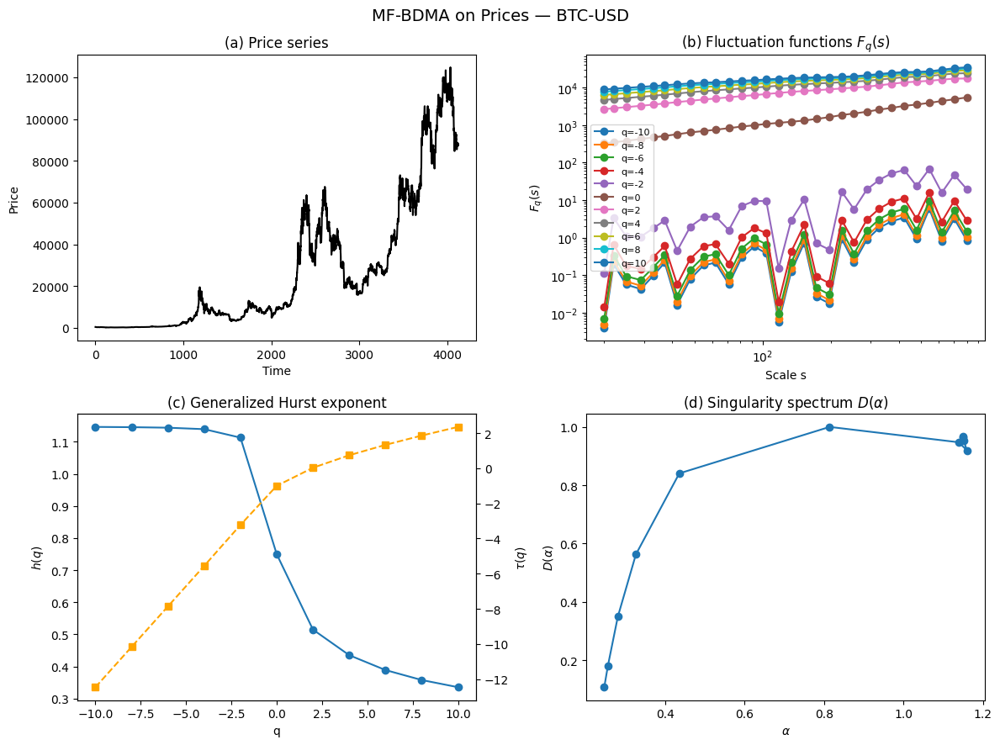

  → MF-CDMA


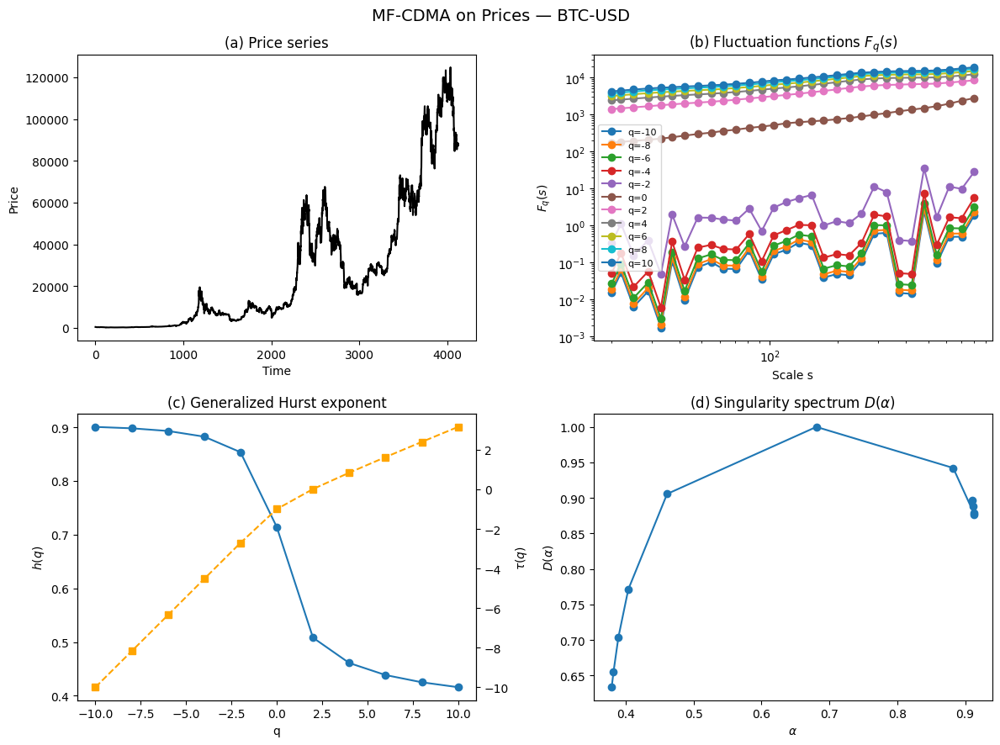

  → MF-FDMA


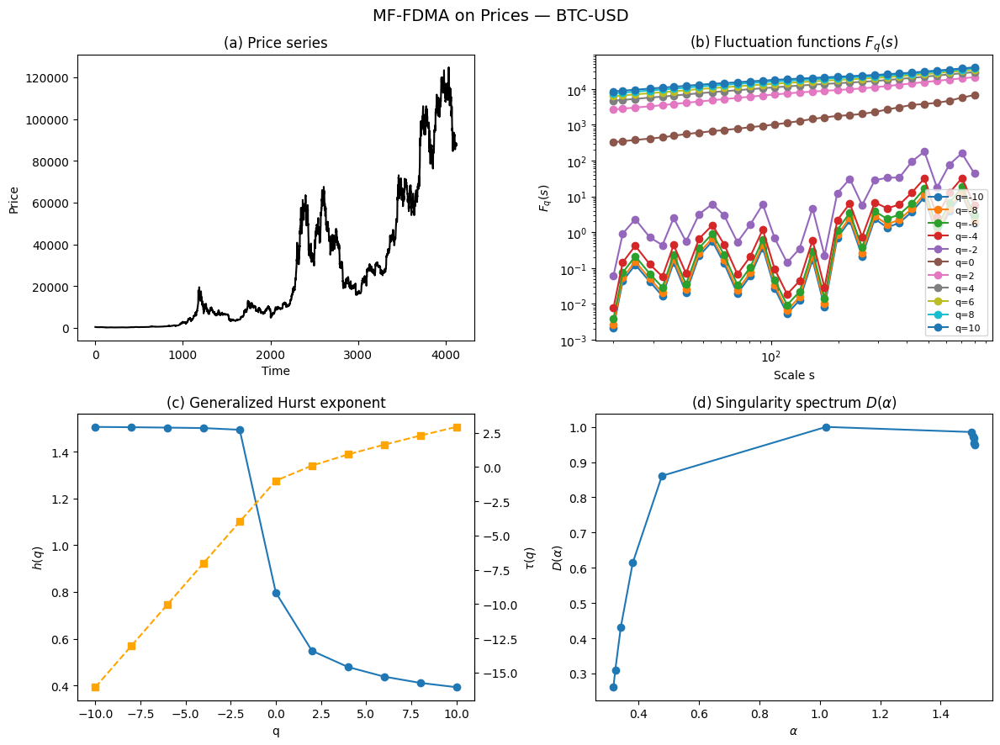

In [24]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

# =====================================
# PARAMETERS
# =====================================
tickers = ["AAPL", "MSFT", "GOOG", "TSLA", "AMZN", "GC=F", "BTC-USD"]
start = "2010-01-01"
end = "2026-01-01"

q_vals = np.arange(-10, 12, 2)
scale_min = 20
scale_max = 800
n_scales = 30


# =====================================
# MF-DFA (prices, no integration)
# =====================================
def mfdfa_prices(x, q_vals, scale_min, scale_max, n_scales):
    scales = np.unique(
        np.logspace(np.log10(scale_min), np.log10(scale_max), n_scales).astype(int)
    )

    Fqs = np.zeros((len(q_vals), len(scales)))

    for i, s in enumerate(scales):
        Ns = len(x) // s
        rms = []

        for v in range(Ns):
            seg = x[v * s:(v + 1) * s]
            t = np.arange(s)

            p = np.polyfit(t, seg, 1)
            trend = np.polyval(p, t)

            rms.append(np.sqrt(np.mean((seg - trend) ** 2)))

        rms = np.array(rms)
        rms = rms[rms > 0]

        for j, q in enumerate(q_vals):
            if q == 0:
                Fqs[j, i] = np.exp(0.5 * np.mean(np.log(rms ** 2)))
            else:
                Fqs[j, i] = (np.mean(rms ** q)) ** (1 / q)

    hq = np.array([
        np.polyfit(np.log(scales), np.log(Fqs[j]), 1)[0]
        for j in range(len(q_vals))
    ])

    return scales, Fqs, hq


# =====================================
# MF-DMA (prices, no integration)
# =====================================
def mfdma_prices(x, q_vals, scale_min, scale_max, n_scales, theta=0.5):
    """
    theta = 0   -> MF-BDMA
    theta = 0.5 -> MF-CDMA
    theta = 1   -> MF-FDMA
    """
    scales = np.unique(
        np.logspace(np.log10(scale_min), np.log10(scale_max), n_scales).astype(int)
    )

    Fqs = np.zeros((len(q_vals), len(scales)))
    N = len(x)

    for i, s in enumerate(scales):
        rms_sq = []

        k_back = int(np.floor((s - 1) * theta))
        k_fwd = int(np.ceil((s - 1) * (1 - theta)))

        for idx in range(k_back, N - k_fwd):
            window = x[idx - k_back: idx + k_fwd + 1]
            if len(window) < s:
                continue

            trend = np.mean(window)
            rms_sq.append((x[idx] - trend) ** 2)

        rms_sq = np.array(rms_sq)
        rms_sq = rms_sq[rms_sq > 0]

        for j, q in enumerate(q_vals):
            if q == 0:
                Fqs[j, i] = np.exp(0.5 * np.mean(np.log(rms_sq)))
            else:
                Fqs[j, i] = (np.mean(rms_sq ** (q / 2))) ** (1 / q)

    hq = np.array([
        np.polyfit(np.log(scales), np.log(Fqs[j]), 1)[0]
        for j in range(len(q_vals))
    ])

    return scales, Fqs, hq


# =====================================
# MAIN LOOP
# =====================================
dma_variants = {
    "MF-DFA": None,
    "MF-BDMA": 0.0,
    "MF-CDMA": 0.5,
    "MF-FDMA": 1.0
}

for ticker in tickers:
    print(f"\nProcessing {ticker}...")

    data = yf.download(ticker, start=start, end=end, progress=False)
    price = data["Close"].dropna().values

    for method, theta in dma_variants.items():
        print(f"  → {method}")

        if method == "MF-DFA":
            scales, Fqs, hq = mfdfa_prices(
                price, q_vals, scale_min, scale_max, n_scales
            )
        else:
            scales, Fqs, hq = mfdma_prices(
                price, q_vals, scale_min, scale_max, n_scales, theta
            )

        # Multifractal exponents
        tau_q = q_vals * hq - 1
        alpha = np.gradient(tau_q, q_vals)
        D_alpha = q_vals * alpha - tau_q

        # =====================================
        # 4-PANEL PLOT
        # =====================================
        fig, axs = plt.subplots(2, 2, figsize=(12, 9))
        fig.suptitle(f"{method} on Prices — {ticker}", fontsize=14)

        # (a) Price series
        axs[0, 0].plot(price, color="black")
        axs[0, 0].set_title("(a) Price series")
        axs[0, 0].set_xlabel("Time")
        axs[0, 0].set_ylabel("Price")

        # (b) F_q(s)
        for q in q_vals:
            idx = np.where(q_vals == q)[0][0]
            axs[0, 1].loglog(scales, Fqs[idx], 'o-', label=f"q={q}")

        axs[0, 1].set_title("(b) Fluctuation functions $F_q(s)$")
        axs[0, 1].set_xlabel("Scale s")
        axs[0, 1].set_ylabel("$F_q(s)$")
        axs[0, 1].legend(fontsize=8)

        # (c) h(q) and tau(q)
        axs[1, 0].plot(q_vals, hq, 'o-', label="$h(q)$")
        axs[1, 0].set_title("(c) Generalized Hurst exponent")
        axs[1, 0].set_xlabel("q")
        axs[1, 0].set_ylabel("$h(q)$")

        ax2 = axs[1, 0].twinx()
        ax2.plot(q_vals, tau_q, 's--', color="orange", label=r"$\tau(q)$")
        ax2.set_ylabel(r"$\tau(q)$")

        # (d) Singularity spectrum
        axs[1, 1].plot(alpha, D_alpha, 'o-')
        axs[1, 1].set_title("(d) Singularity spectrum $D(\\alpha)$")
        axs[1, 1].set_xlabel(r"$\alpha$")
        axs[1, 1].set_ylabel(r"$D(\alpha)$")

        plt.tight_layout()
        plt.show()



Processing AAPL...
  → MF-DFA


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\3562484883.py:118: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


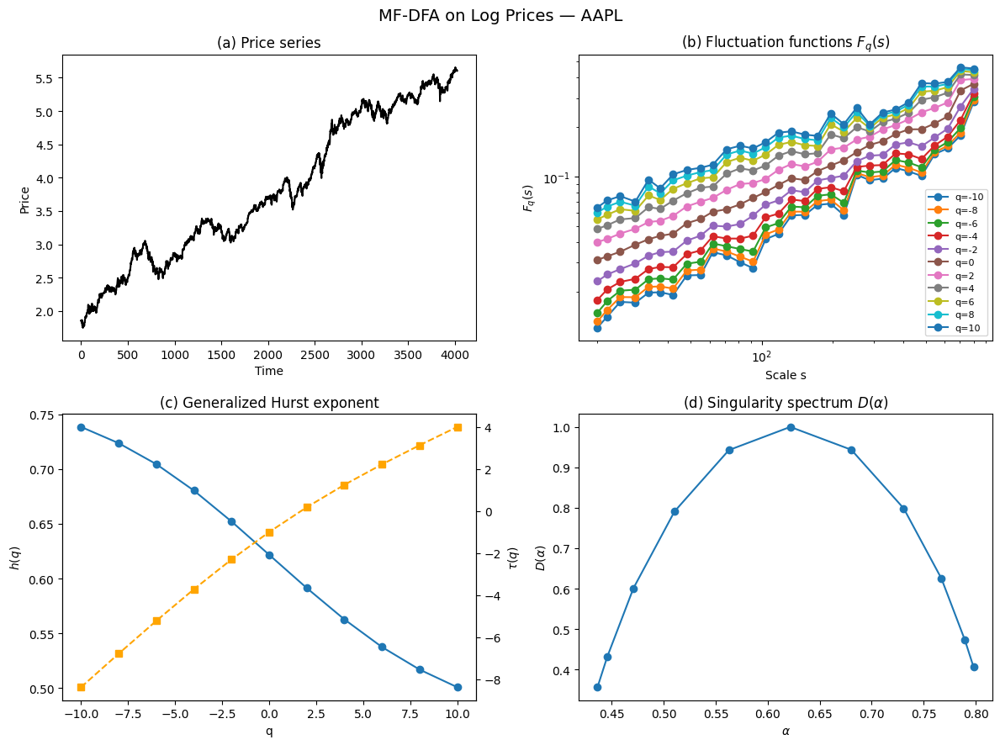

  → MF-BDMA


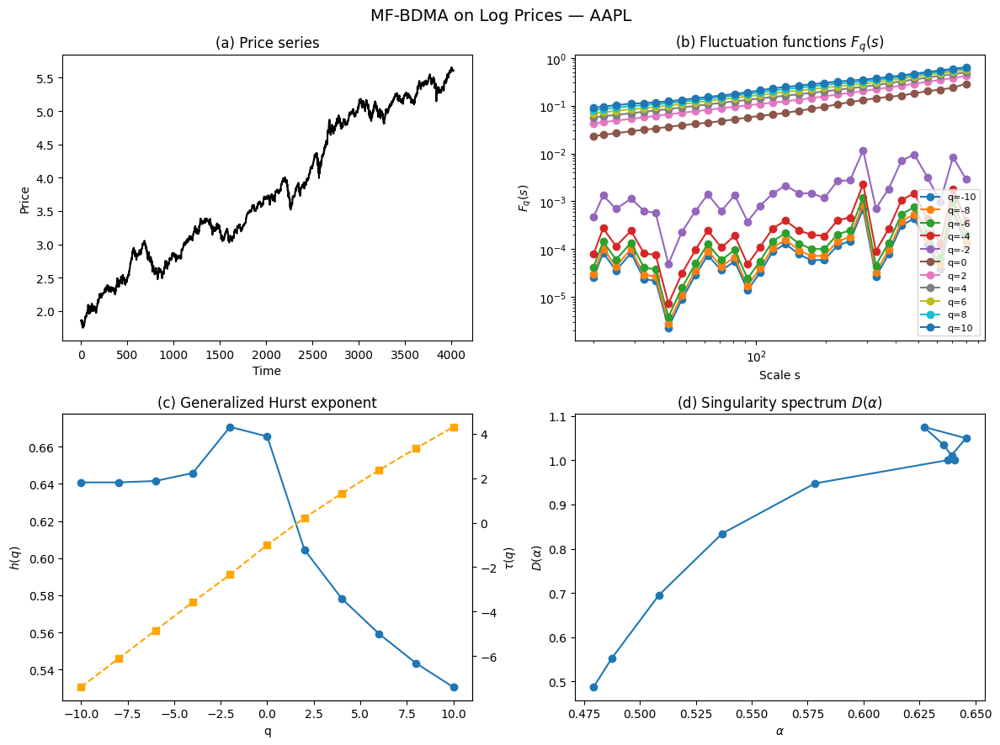

  → MF-CDMA


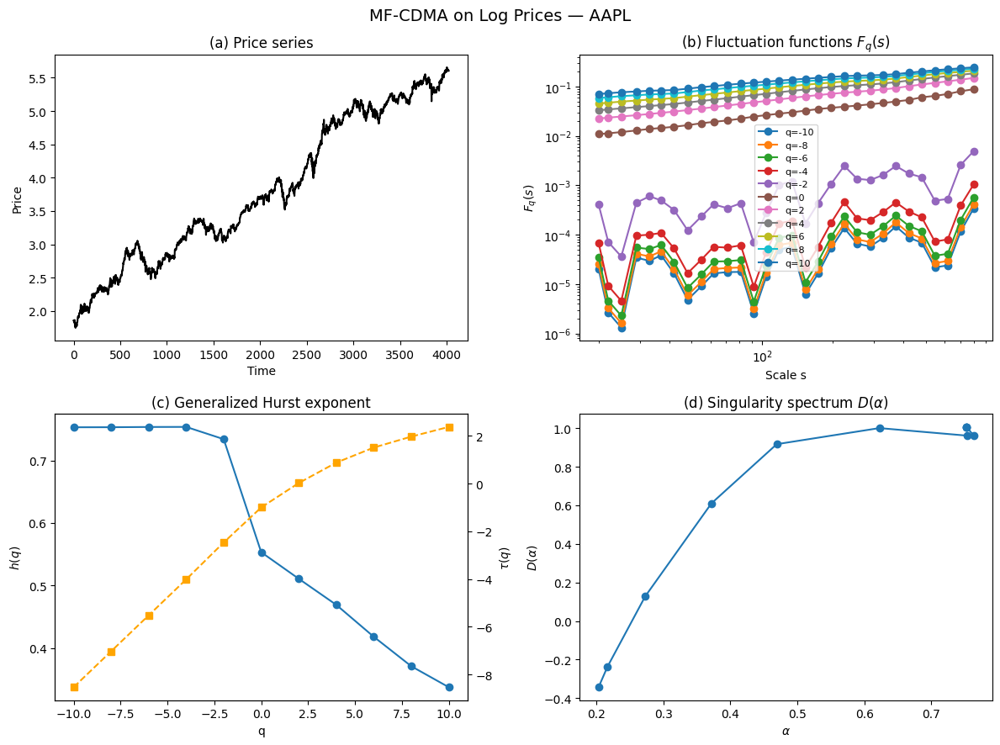

  → MF-FDMA


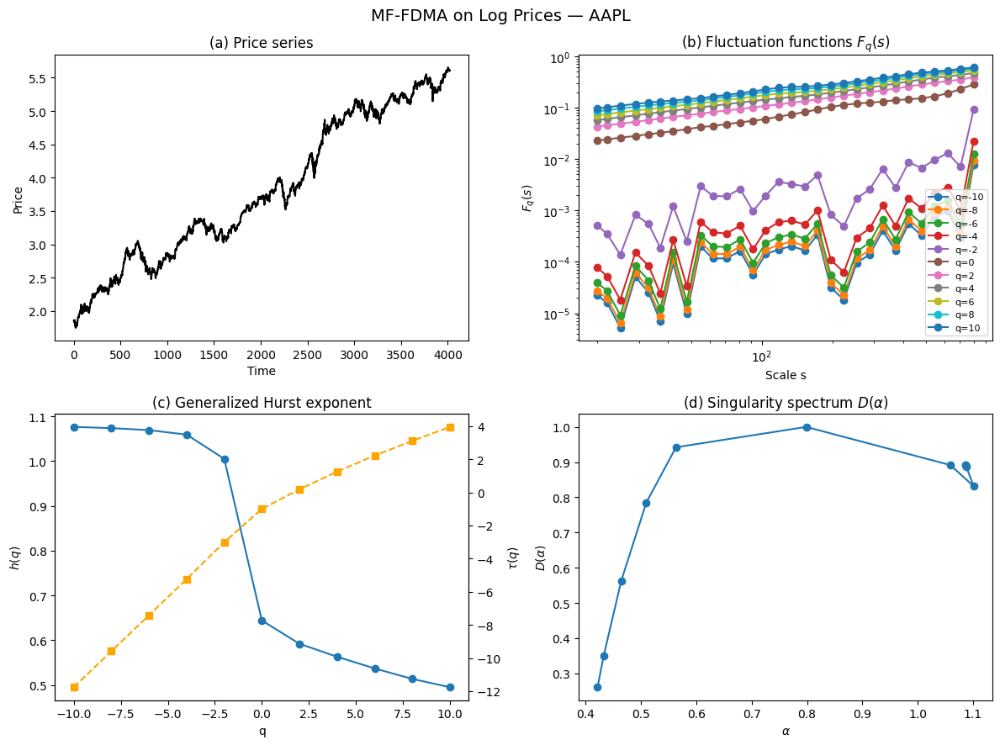


Processing MSFT...
  → MF-DFA


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\3562484883.py:118: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


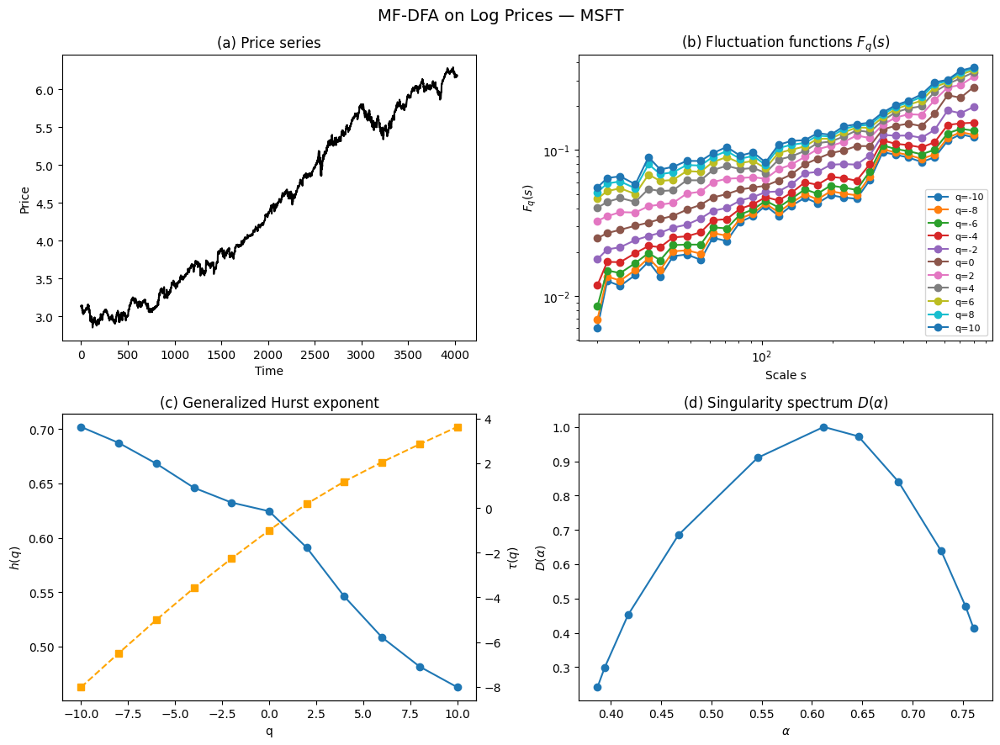

  → MF-BDMA


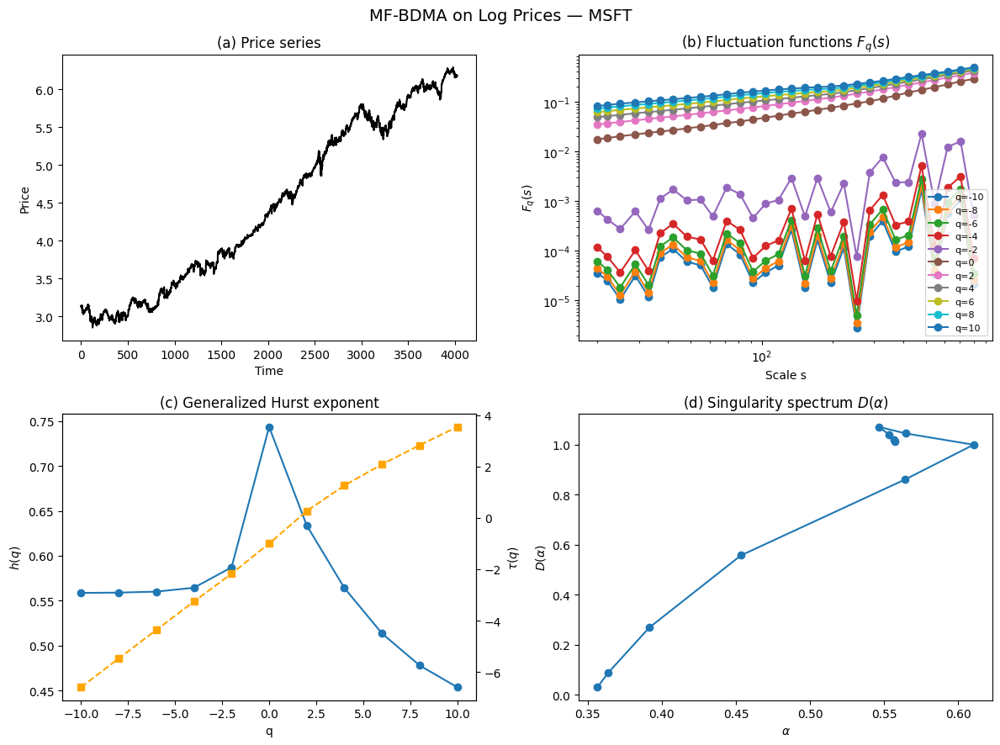

  → MF-CDMA


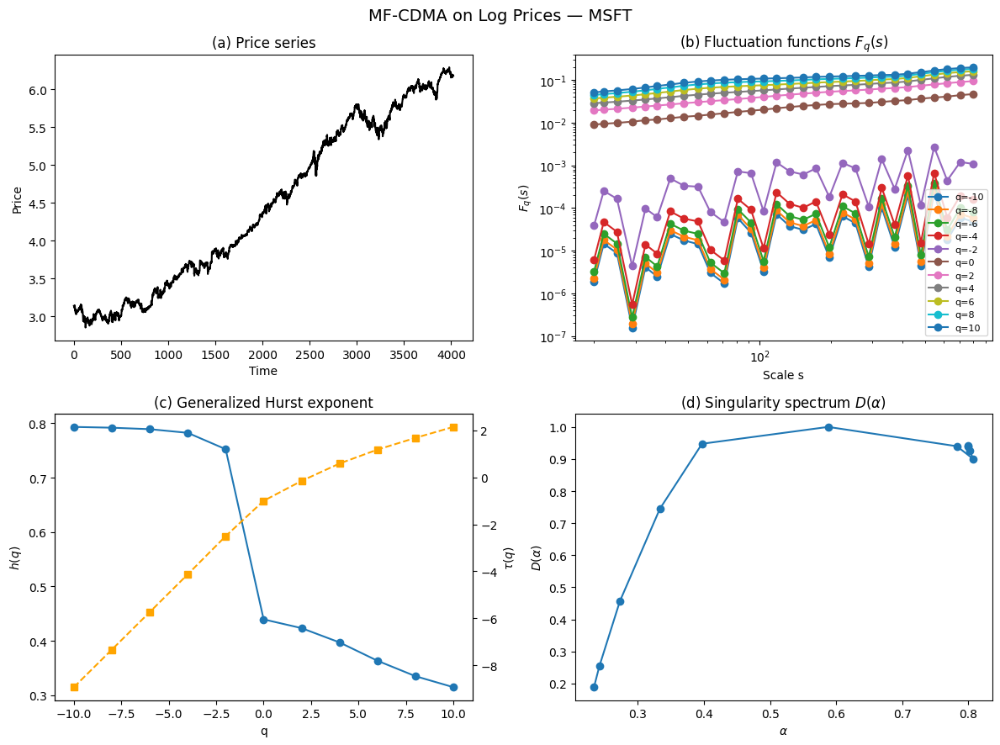

  → MF-FDMA


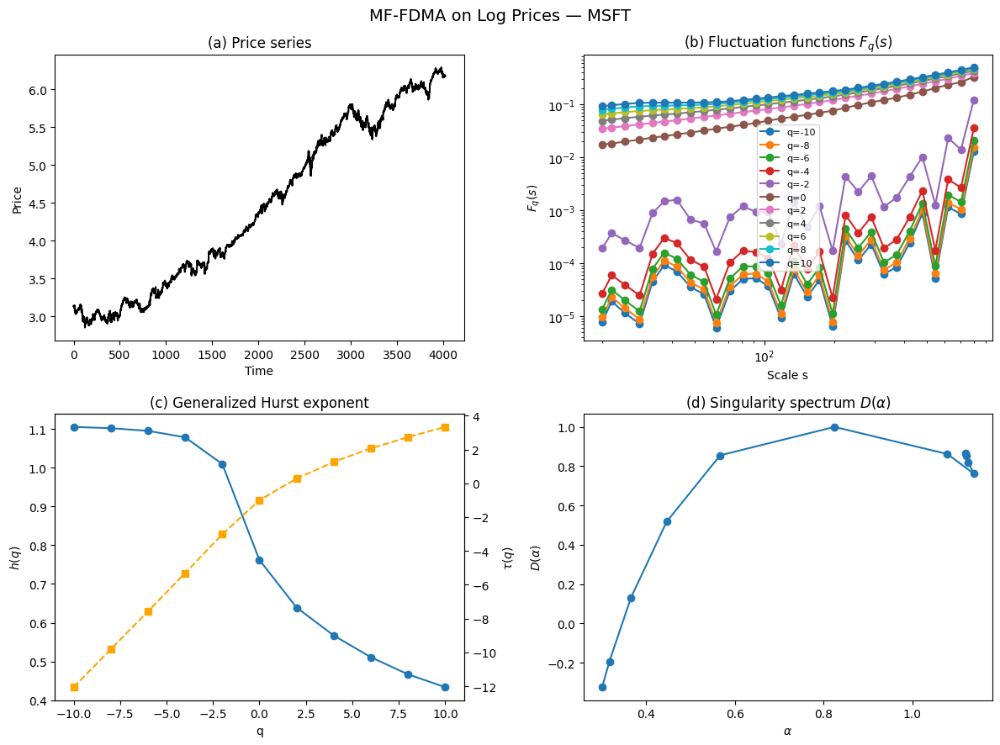


Processing GOOG...
  → MF-DFA


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\3562484883.py:118: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


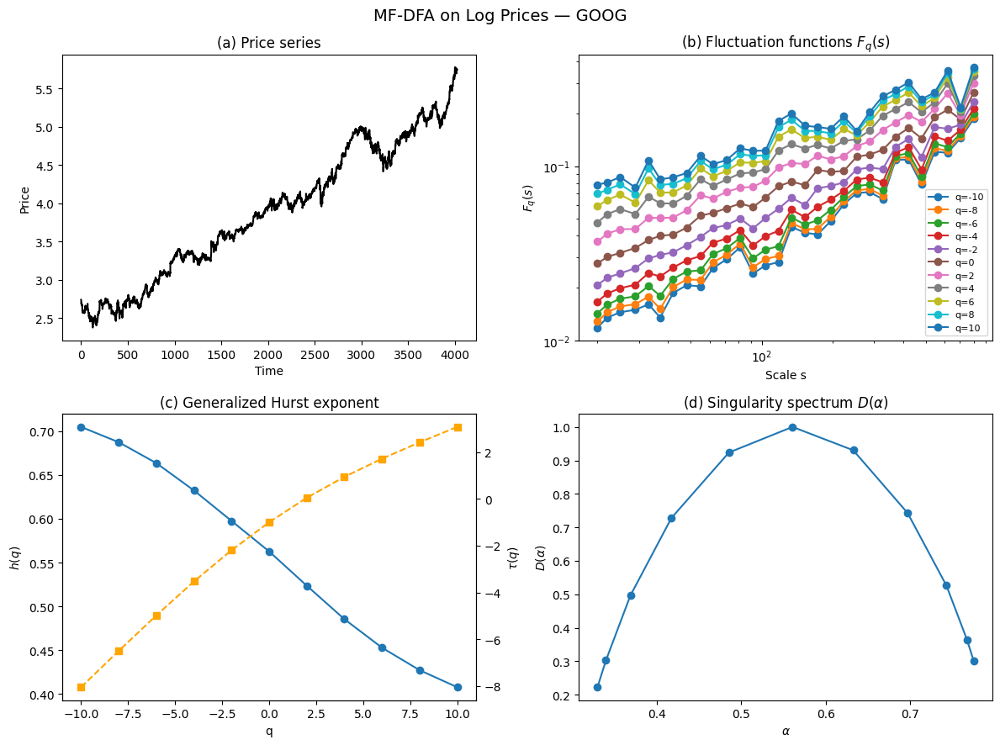

  → MF-BDMA


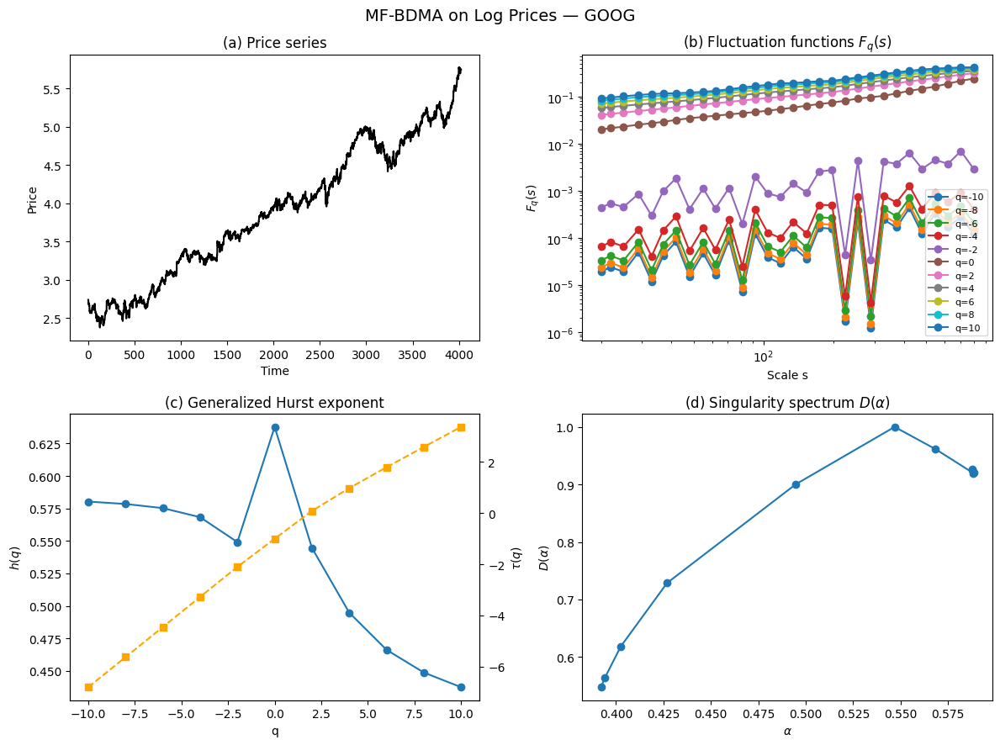

  → MF-CDMA


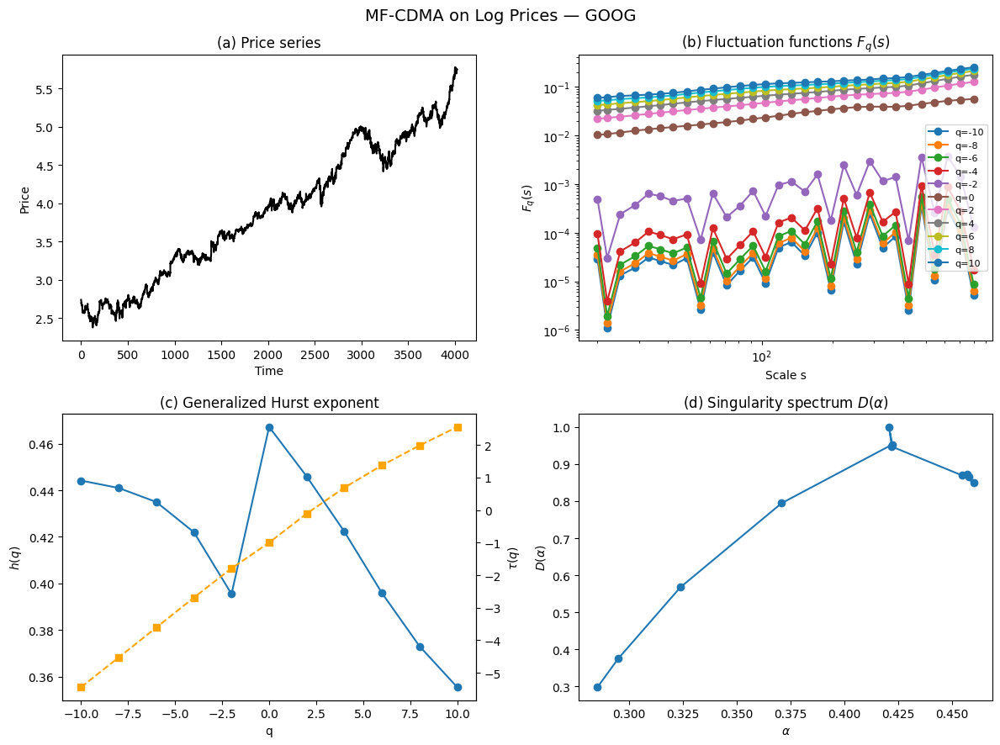

  → MF-FDMA


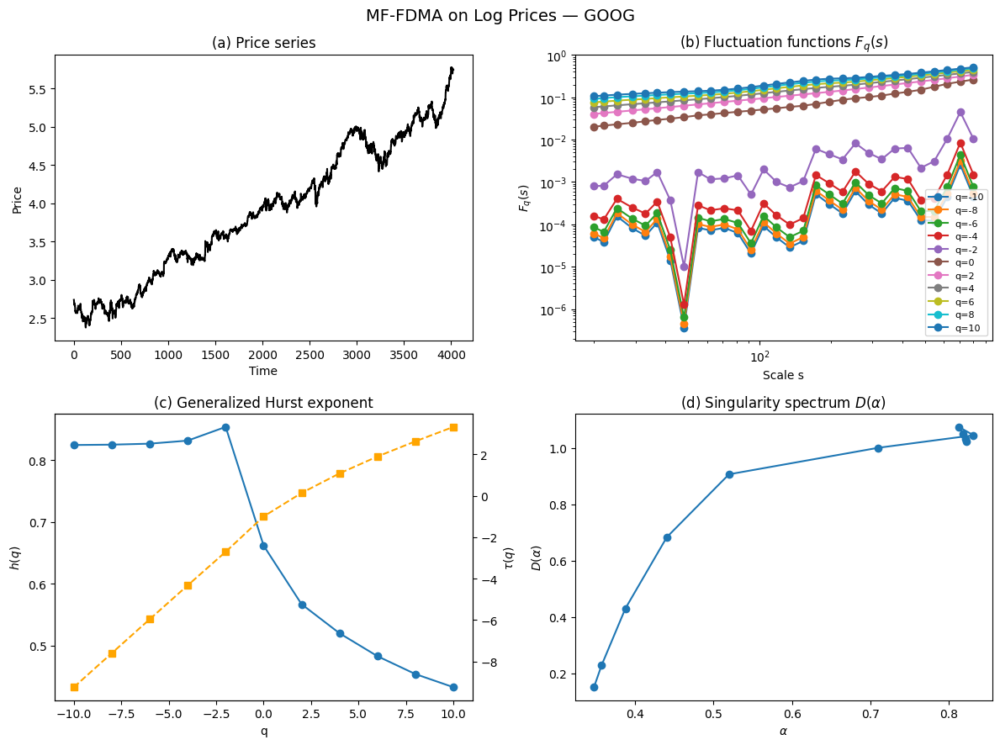


Processing TSLA...
  → MF-DFA


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\3562484883.py:118: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


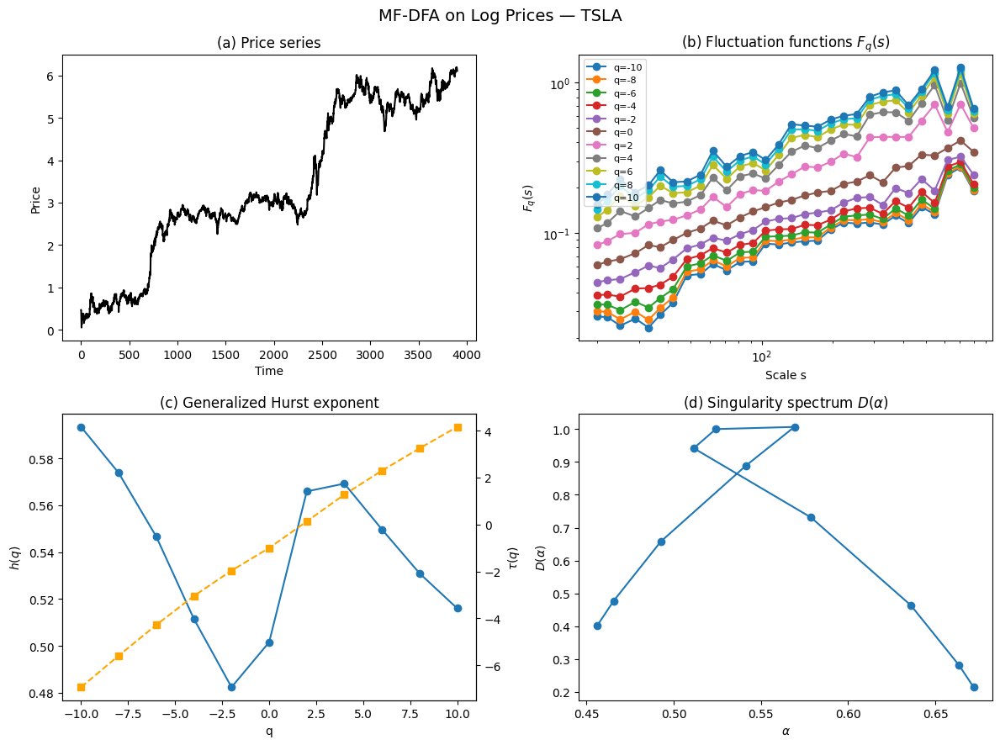

  → MF-BDMA


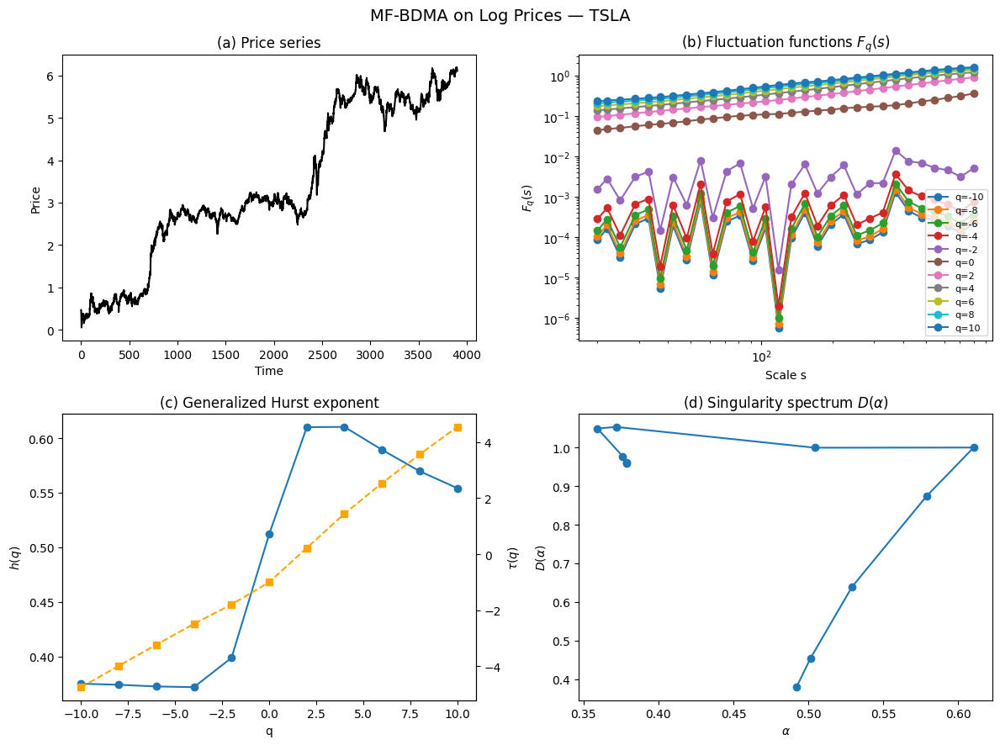

  → MF-CDMA


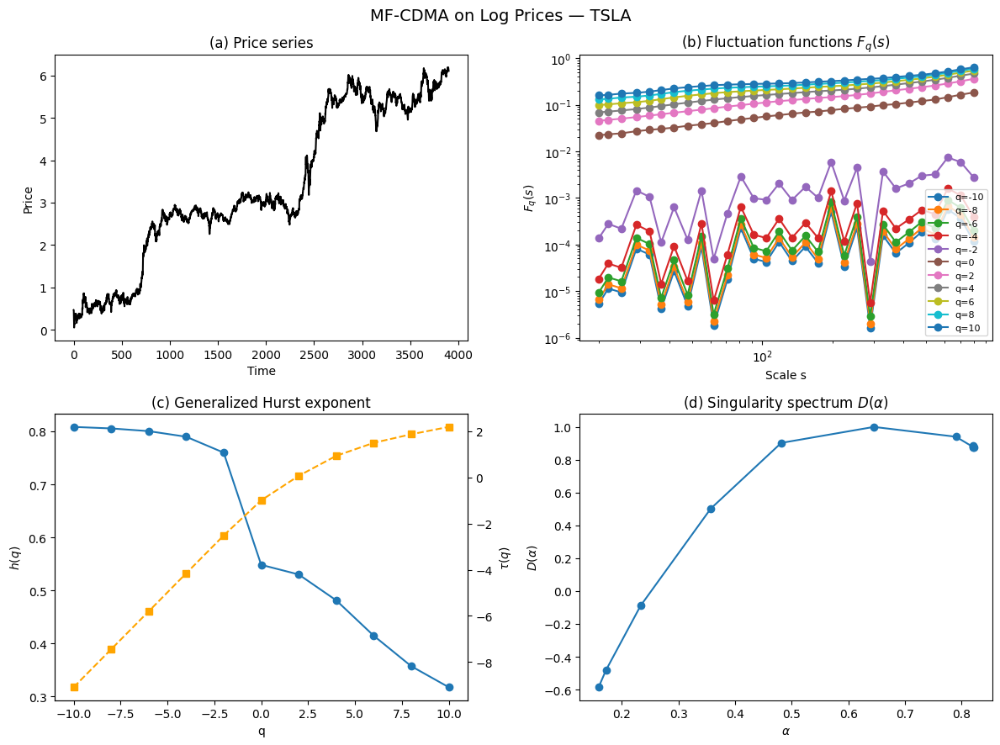

  → MF-FDMA


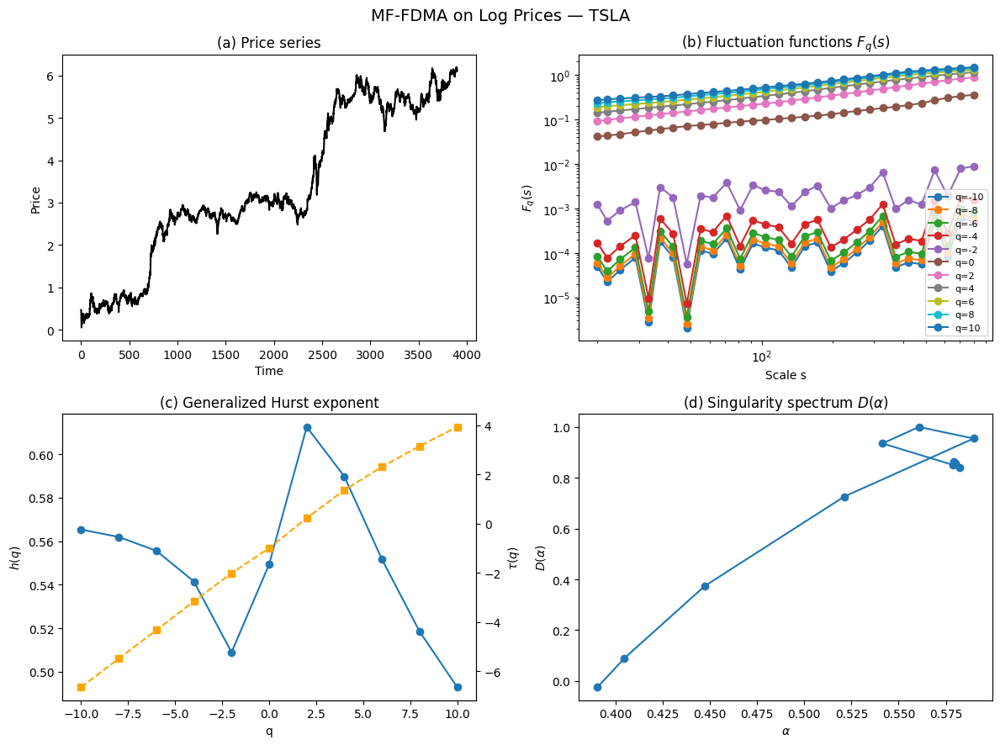


Processing AMZN...
  → MF-DFA


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\3562484883.py:118: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


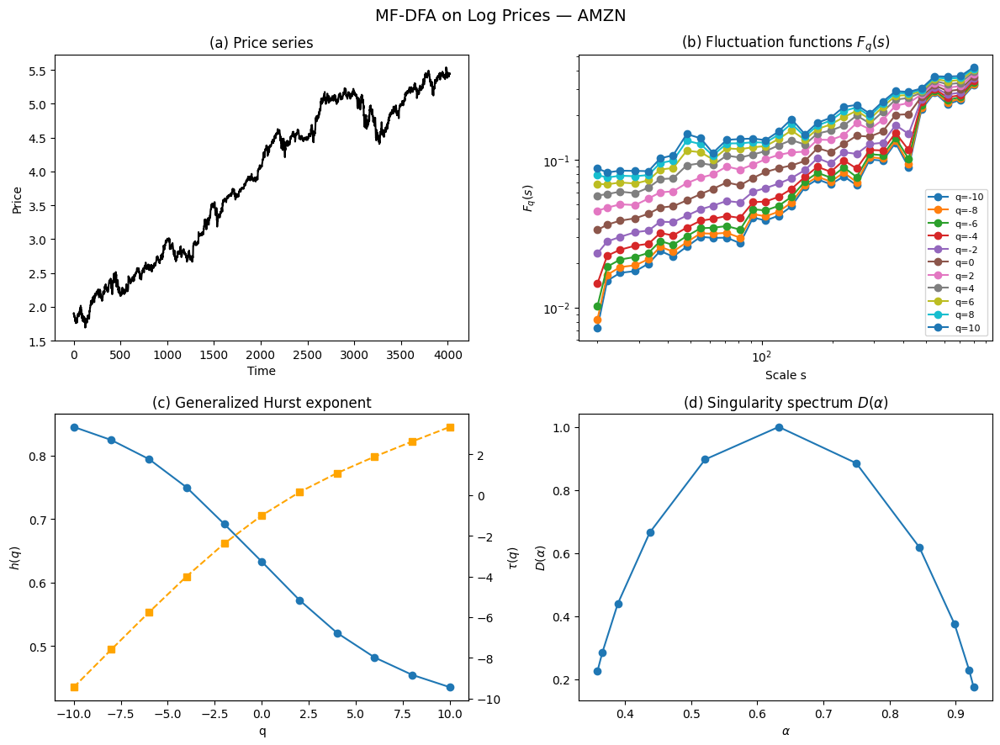

  → MF-BDMA


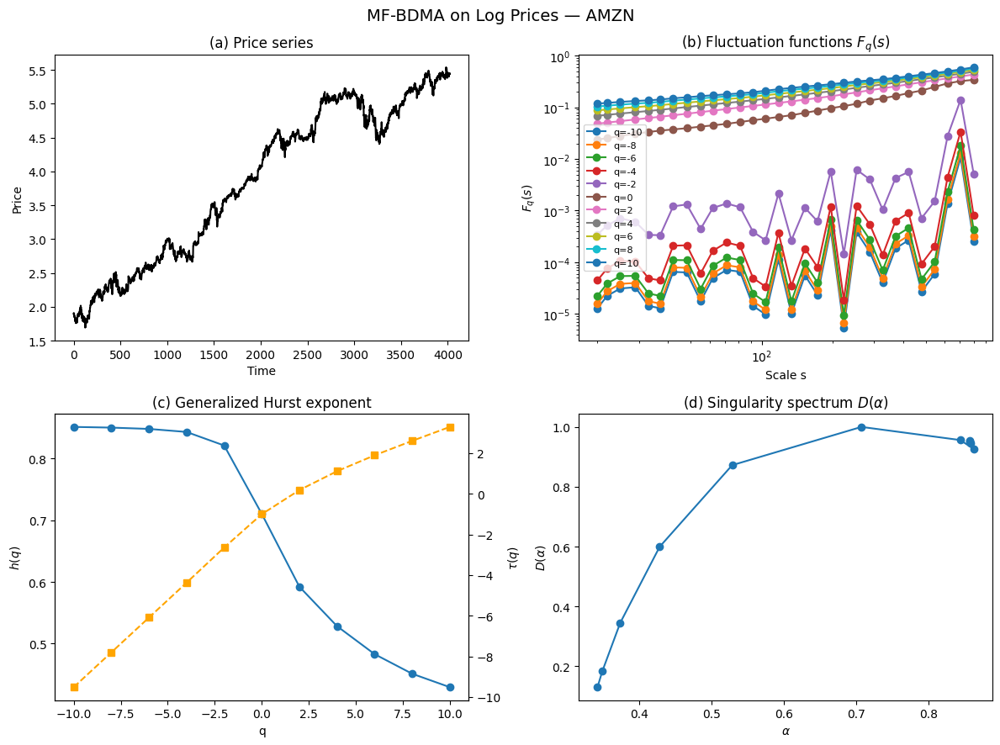

  → MF-CDMA


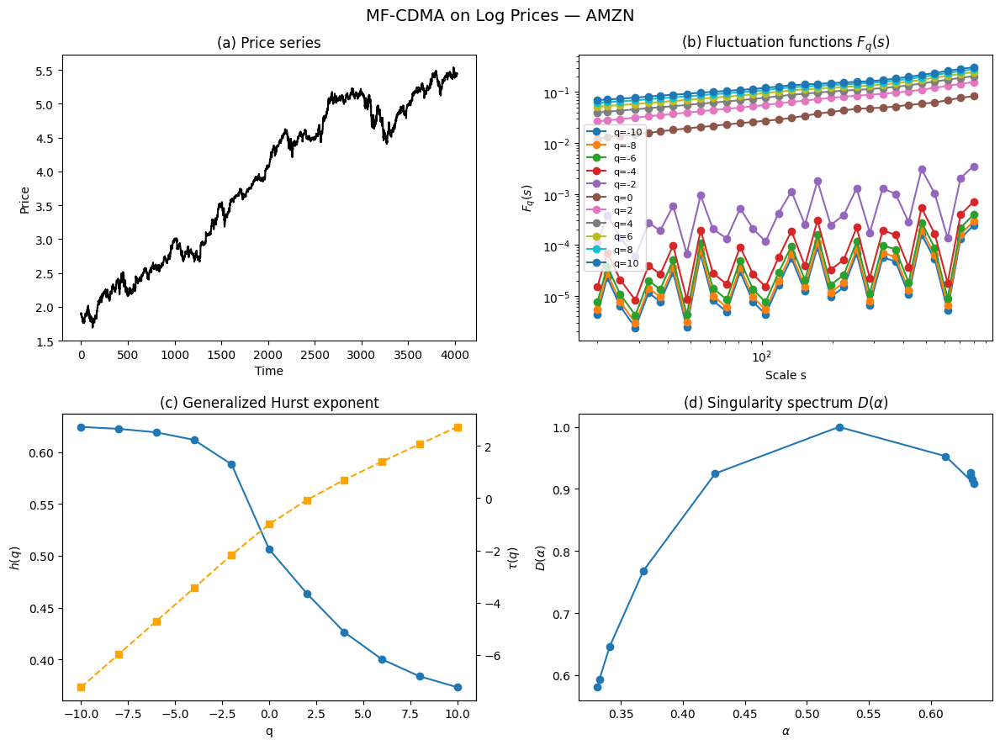

  → MF-FDMA


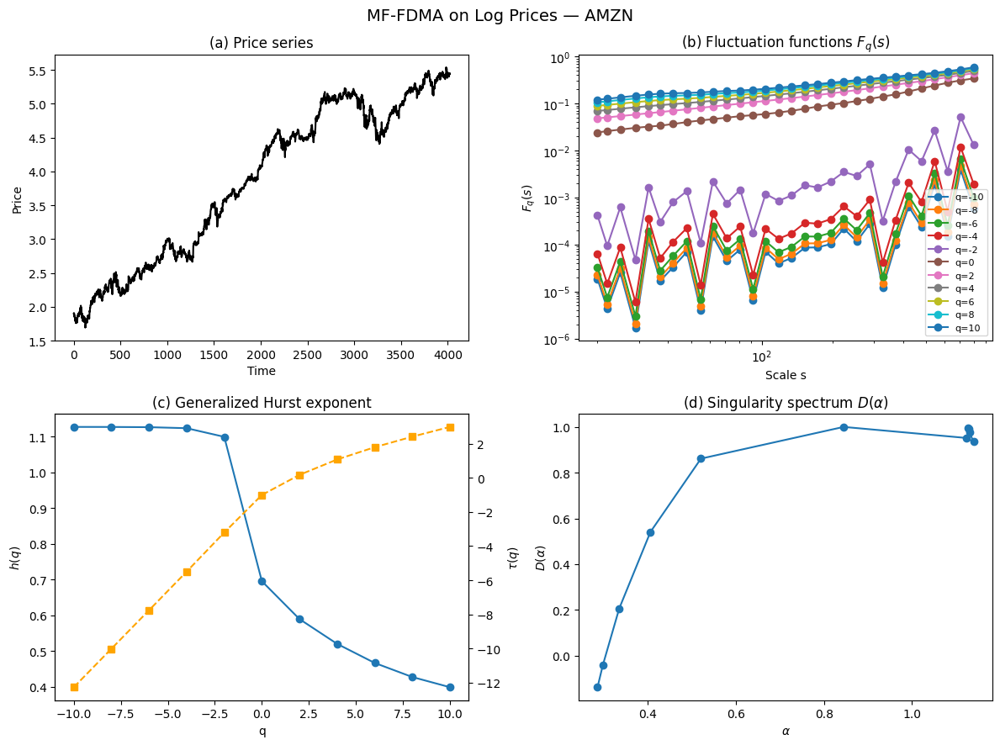


Processing GC=F...
  → MF-DFA


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\3562484883.py:118: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


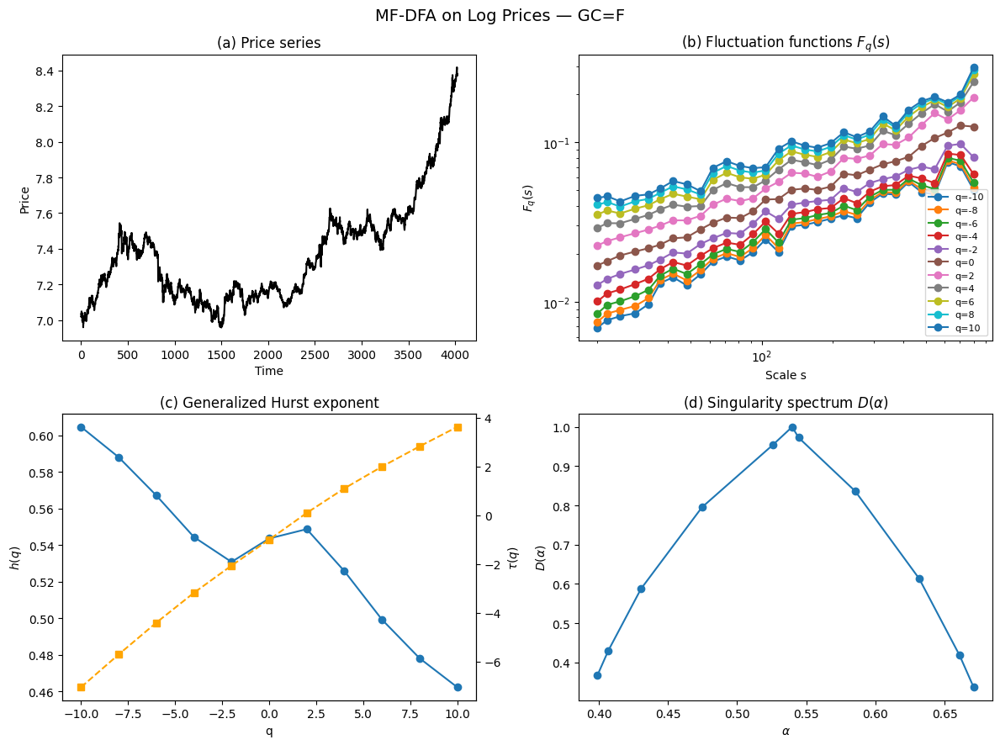

  → MF-BDMA


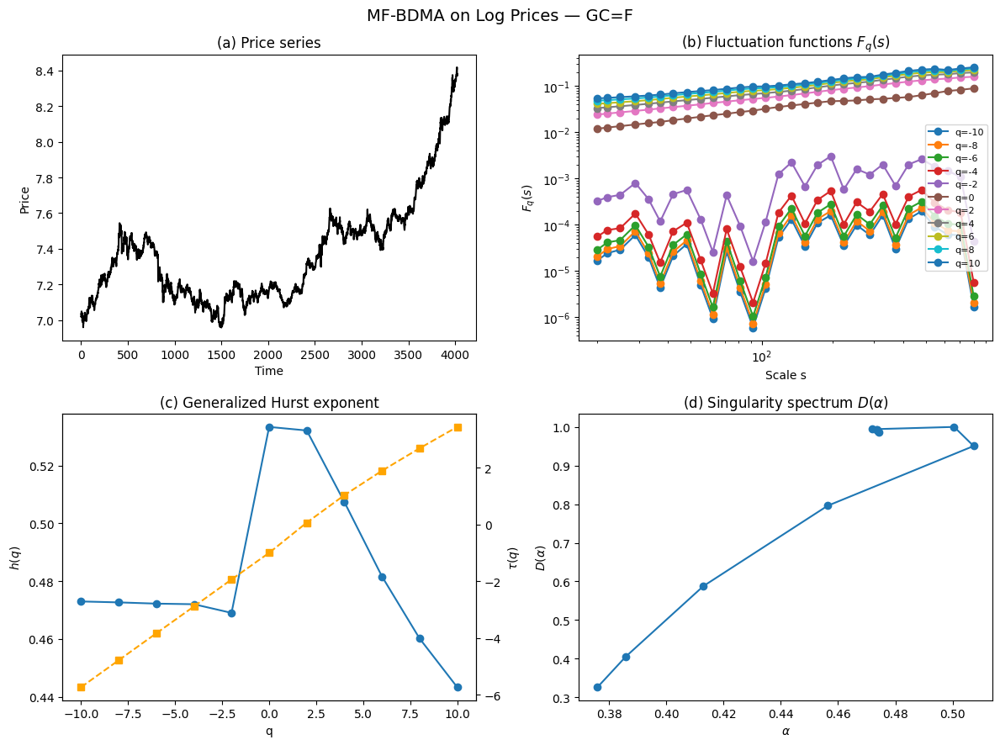

  → MF-CDMA


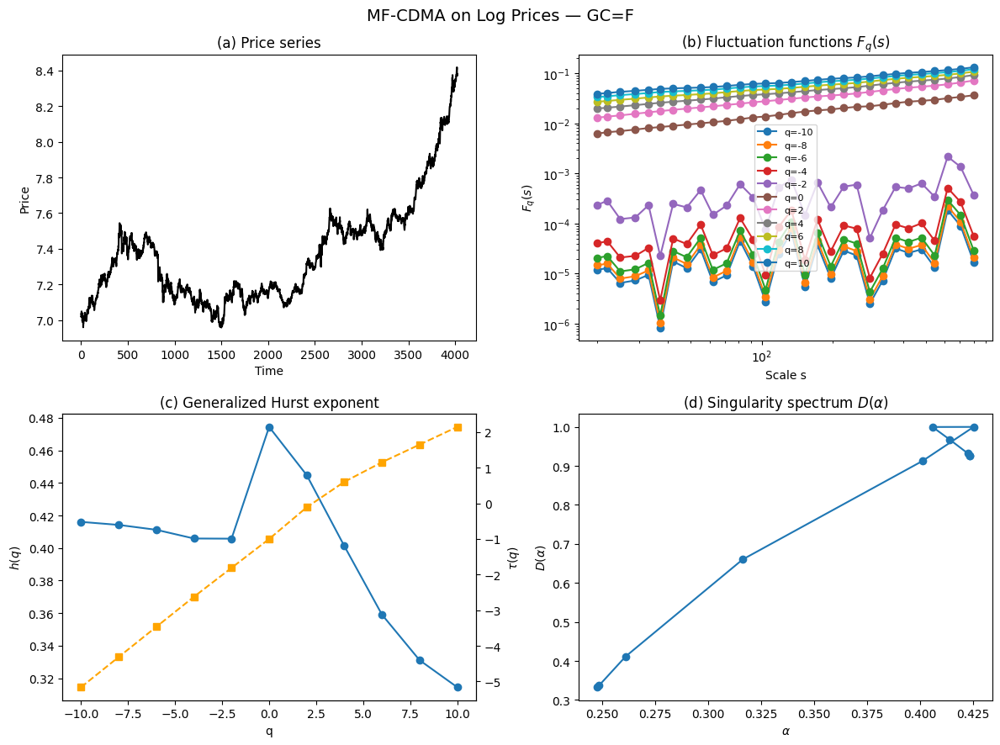

  → MF-FDMA


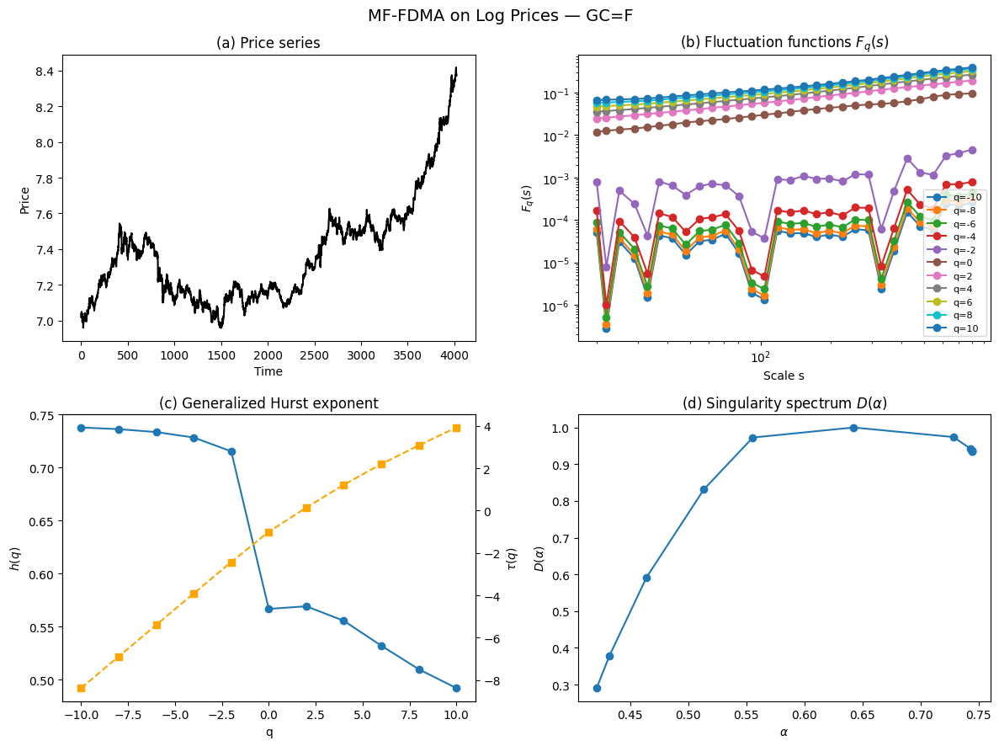


Processing BTC-USD...
  → MF-DFA


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\3562484883.py:118: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


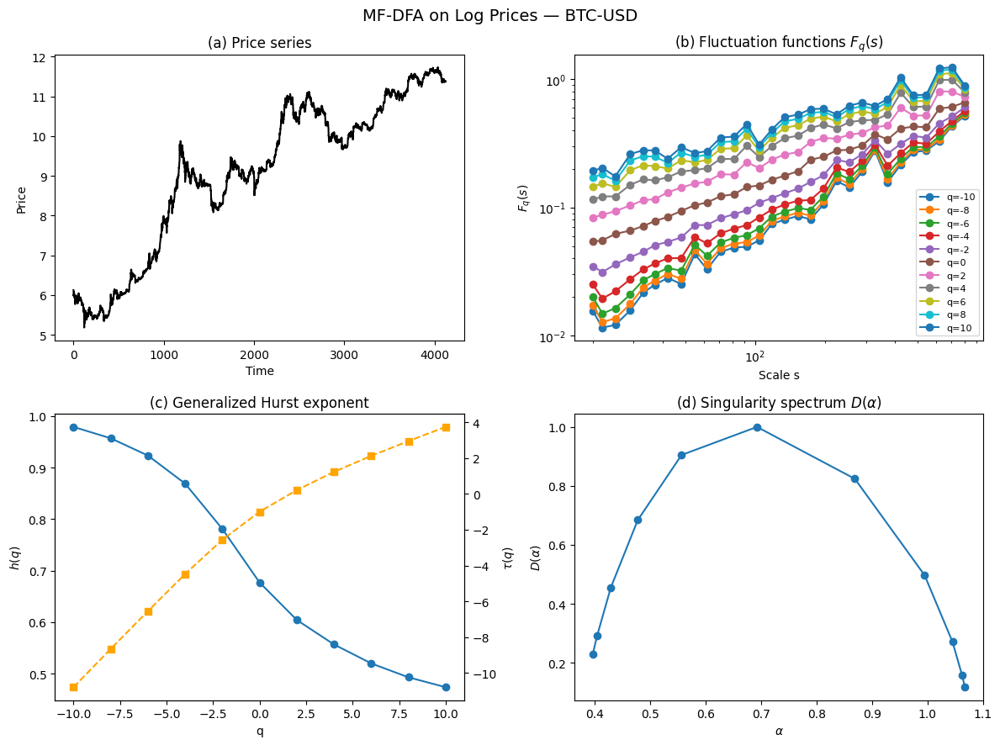

  → MF-BDMA


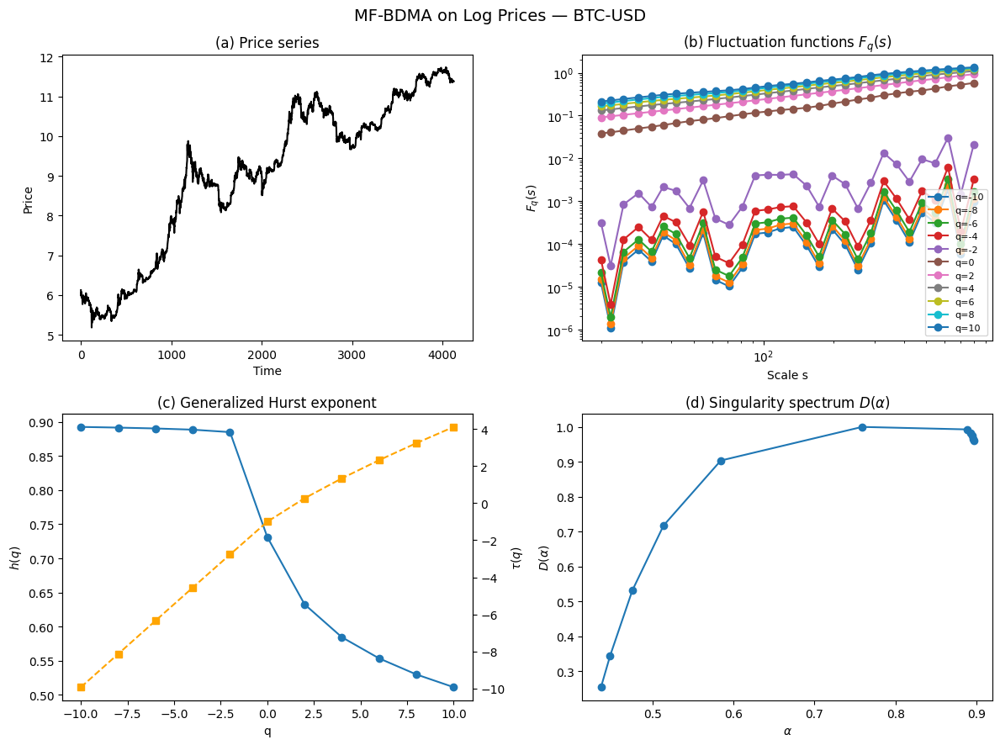

  → MF-CDMA


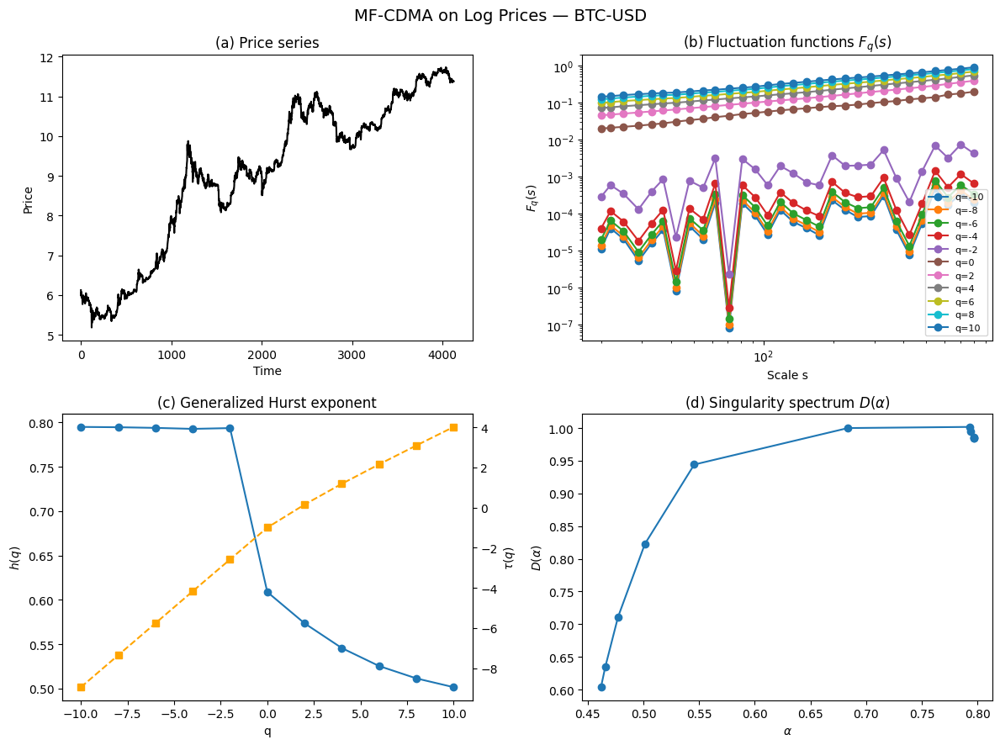

  → MF-FDMA


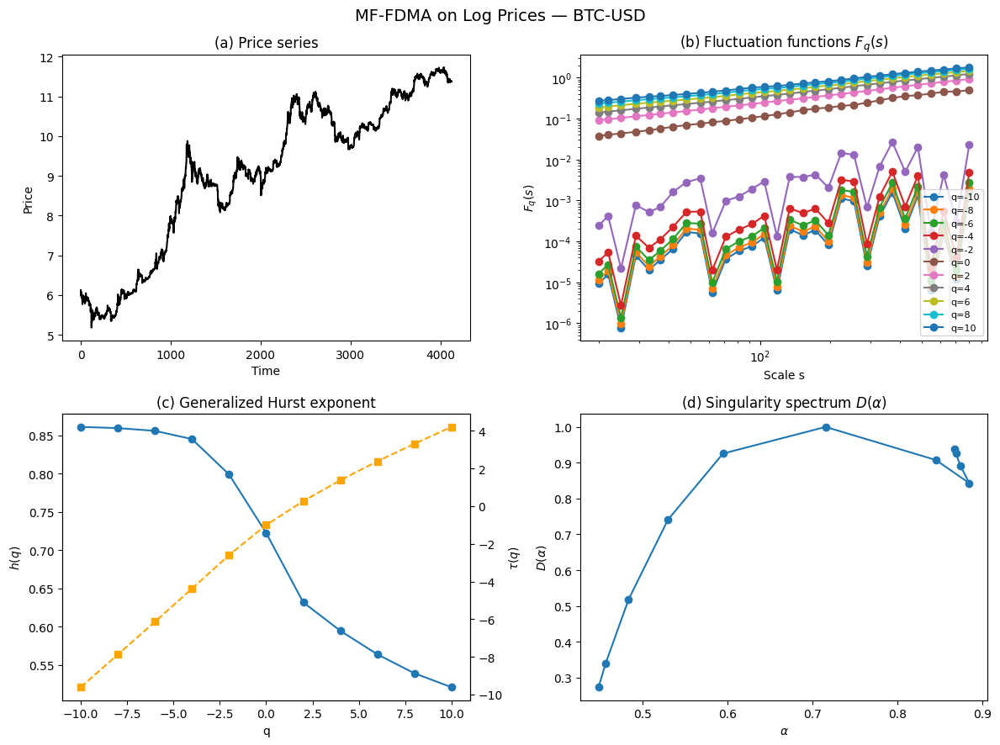

In [25]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

# =====================================
# PARAMETERS
# =====================================
tickers = ["AAPL", "MSFT", "GOOG", "TSLA", "AMZN", "GC=F", "BTC-USD"]
start = "2010-01-01"
end = "2026-01-01"

q_vals = np.arange(-10, 12, 2)
scale_min = 20
scale_max = 800
n_scales = 30


# =====================================
# MF-DFA (prices, no integration)
# =====================================
def mfdfa_prices(x, q_vals, scale_min, scale_max, n_scales):
    scales = np.unique(
        np.logspace(np.log10(scale_min), np.log10(scale_max), n_scales).astype(int)
    )

    Fqs = np.zeros((len(q_vals), len(scales)))

    for i, s in enumerate(scales):
        Ns = len(x) // s
        rms = []

        for v in range(Ns):
            seg = x[v * s:(v + 1) * s]
            t = np.arange(s)

            p = np.polyfit(t, seg, 1)
            trend = np.polyval(p, t)

            rms.append(np.sqrt(np.mean((seg - trend) ** 2)))

        rms = np.array(rms)
        rms = rms[rms > 0]

        for j, q in enumerate(q_vals):
            if q == 0:
                Fqs[j, i] = np.exp(0.5 * np.mean(np.log(rms ** 2)))
            else:
                Fqs[j, i] = (np.mean(rms ** q)) ** (1 / q)

    hq = np.array([
        np.polyfit(np.log(scales), np.log(Fqs[j]), 1)[0]
        for j in range(len(q_vals))
    ])

    return scales, Fqs, hq


# =====================================
# MF-DMA (prices, no integration)
# =====================================
def mfdma_prices(x, q_vals, scale_min, scale_max, n_scales, theta=0.5):
    """
    theta = 0   -> MF-BDMA
    theta = 0.5 -> MF-CDMA
    theta = 1   -> MF-FDMA
    """
    scales = np.unique(
        np.logspace(np.log10(scale_min), np.log10(scale_max), n_scales).astype(int)
    )

    Fqs = np.zeros((len(q_vals), len(scales)))
    N = len(x)

    for i, s in enumerate(scales):
        rms_sq = []

        k_back = int(np.floor((s - 1) * theta))
        k_fwd = int(np.ceil((s - 1) * (1 - theta)))

        for idx in range(k_back, N - k_fwd):
            window = x[idx - k_back: idx + k_fwd + 1]
            if len(window) < s:
                continue

            trend = np.mean(window)
            rms_sq.append((x[idx] - trend) ** 2)

        rms_sq = np.array(rms_sq)
        rms_sq = rms_sq[rms_sq > 0]

        for j, q in enumerate(q_vals):
            if q == 0:
                Fqs[j, i] = np.exp(0.5 * np.mean(np.log(rms_sq)))
            else:
                Fqs[j, i] = (np.mean(rms_sq ** (q / 2))) ** (1 / q)

    hq = np.array([
        np.polyfit(np.log(scales), np.log(Fqs[j]), 1)[0]
        for j in range(len(q_vals))
    ])

    return scales, Fqs, hq


# =====================================
# MAIN LOOP
# =====================================
dma_variants = {
    "MF-DFA": None,
    "MF-BDMA": 0.0,
    "MF-CDMA": 0.5,
    "MF-FDMA": 1.0
}

for ticker in tickers:
    print(f"\nProcessing {ticker}...")

    data = yf.download(ticker, start=start, end=end, progress=False)
    price = np.log(data["Close"].dropna().values)

    for method, theta in dma_variants.items():
        print(f"  → {method}")

        if method == "MF-DFA":
            scales, Fqs, hq = mfdfa_prices(
                price, q_vals, scale_min, scale_max, n_scales
            )
        else:
            scales, Fqs, hq = mfdma_prices(
                price, q_vals, scale_min, scale_max, n_scales, theta
            )

        # Multifractal exponents
        tau_q = q_vals * hq - 1
        alpha = np.gradient(tau_q, q_vals)
        D_alpha = q_vals * alpha - tau_q

        # =====================================
        # 4-PANEL PLOT
        # =====================================
        fig, axs = plt.subplots(2, 2, figsize=(12, 9))
        fig.suptitle(f"{method} on Log Prices — {ticker}", fontsize=14)

        # (a) Price series
        axs[0, 0].plot(price, color="black")
        axs[0, 0].set_title("(a) Price series")
        axs[0, 0].set_xlabel("Time")
        axs[0, 0].set_ylabel("Price")

        # (b) F_q(s)
        for q in q_vals:
            idx = np.where(q_vals == q)[0][0]
            axs[0, 1].loglog(scales, Fqs[idx], 'o-', label=f"q={q}")

        axs[0, 1].set_title("(b) Fluctuation functions $F_q(s)$")
        axs[0, 1].set_xlabel("Scale s")
        axs[0, 1].set_ylabel("$F_q(s)$")
        axs[0, 1].legend(fontsize=8)

        # (c) h(q) and tau(q)
        axs[1, 0].plot(q_vals, hq, 'o-', label="$h(q)$")
        axs[1, 0].set_title("(c) Generalized Hurst exponent")
        axs[1, 0].set_xlabel("q")
        axs[1, 0].set_ylabel("$h(q)$")

        ax2 = axs[1, 0].twinx()
        ax2.plot(q_vals, tau_q, 's--', color="orange", label=r"$\tau(q)$")
        ax2.set_ylabel(r"$\tau(q)$")

        # (d) Singularity spectrum
        axs[1, 1].plot(alpha, D_alpha, 'o-')
        axs[1, 1].set_title("(d) Singularity spectrum $D(\\alpha)$")
        axs[1, 1].set_xlabel(r"$\alpha$")
        axs[1, 1].set_ylabel(r"$D(\alpha)$")

        plt.tight_layout()
        plt.show()


# MF-SF


Processing AAPL...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_2600\325432460.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, progress=False)


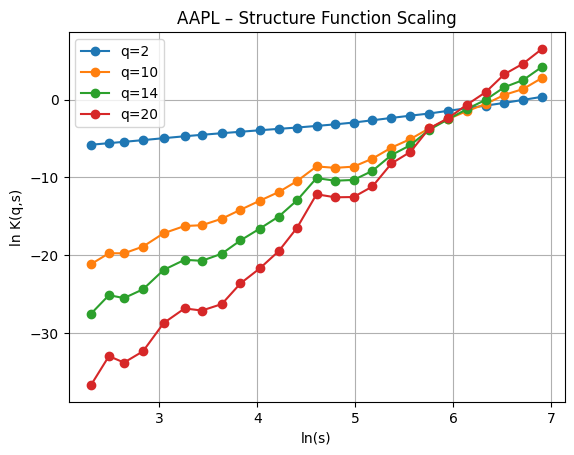

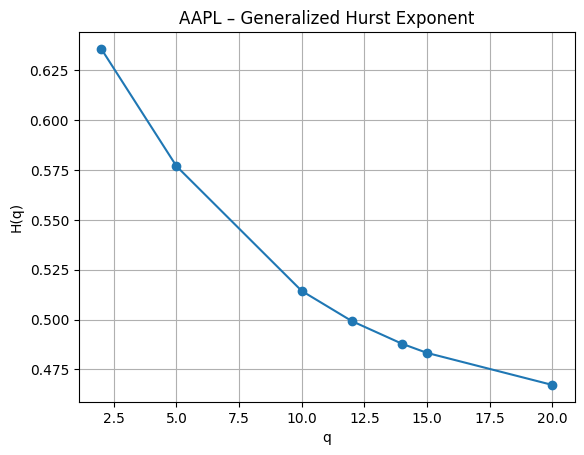

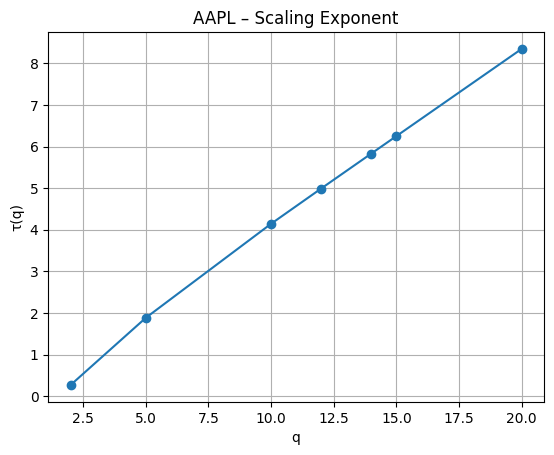

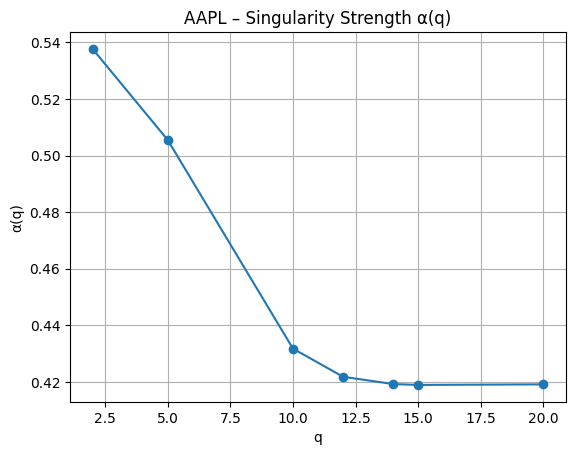

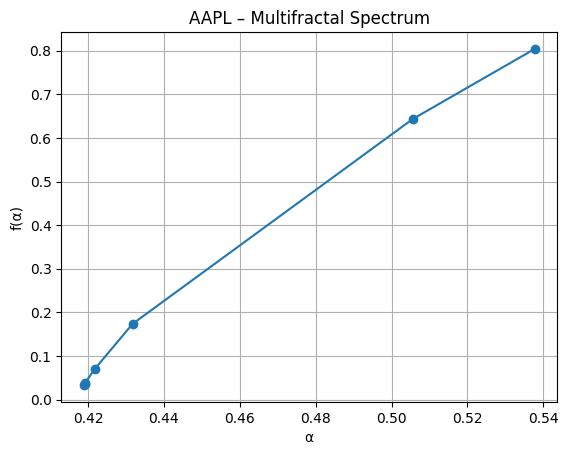


Processing MSFT...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_2600\325432460.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, progress=False)


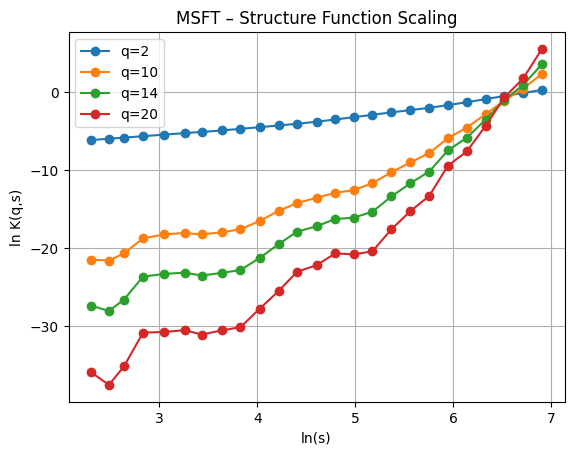

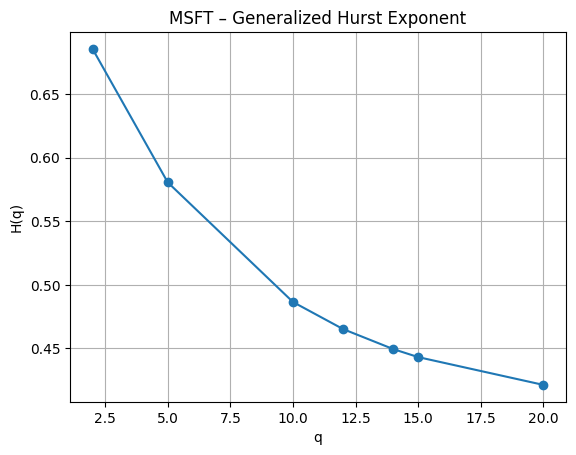

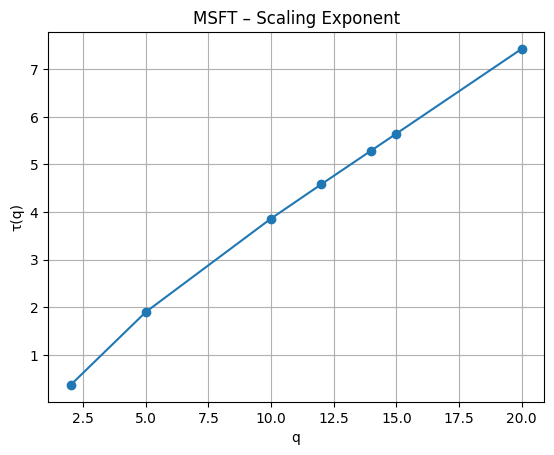

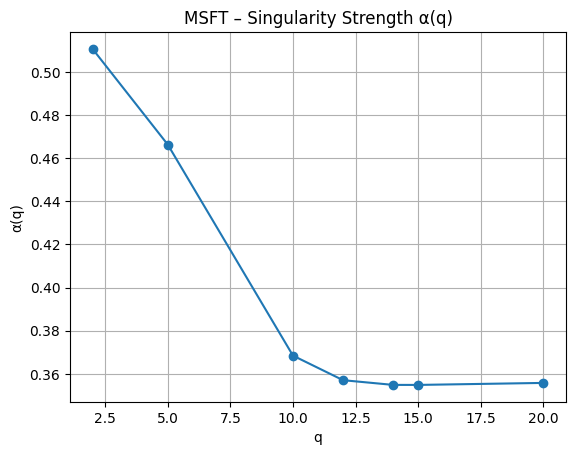

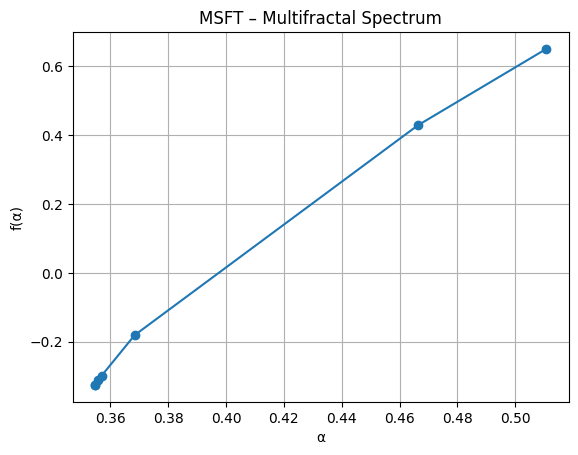


Processing GOOG...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_2600\325432460.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, progress=False)


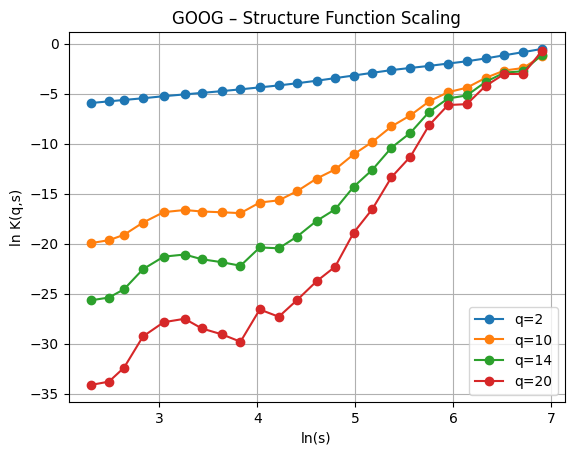

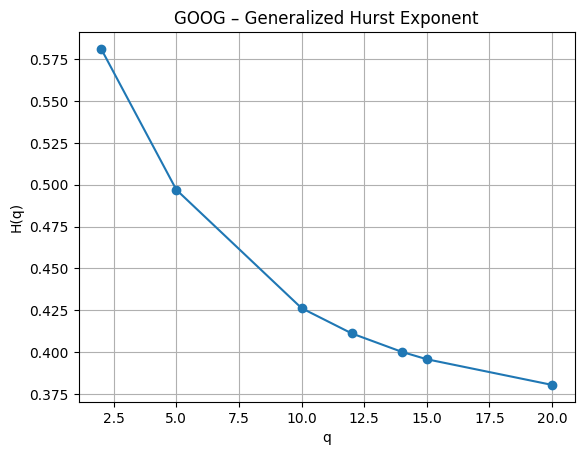

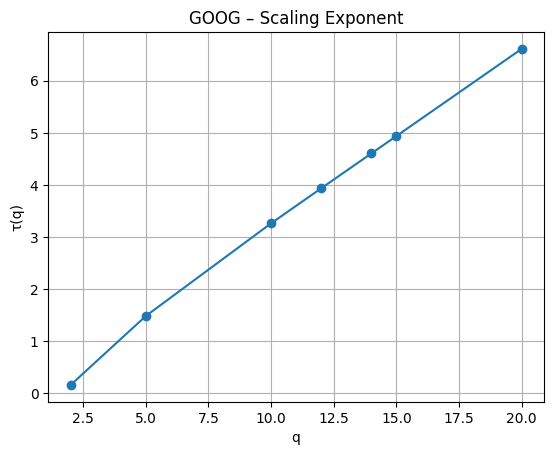

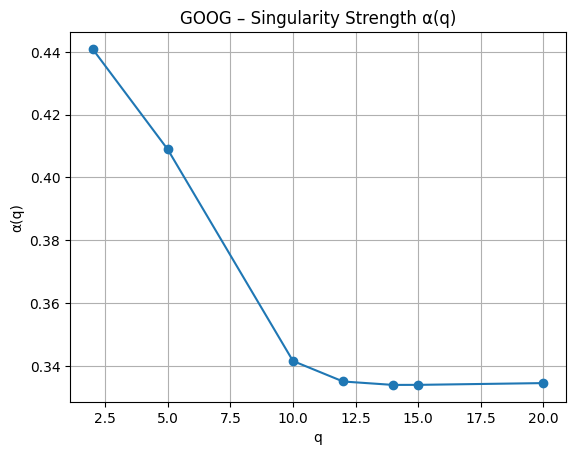

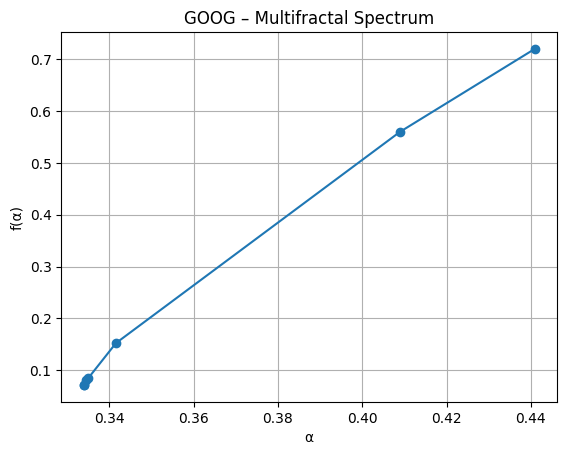


Processing TSLA...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_2600\325432460.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, progress=False)


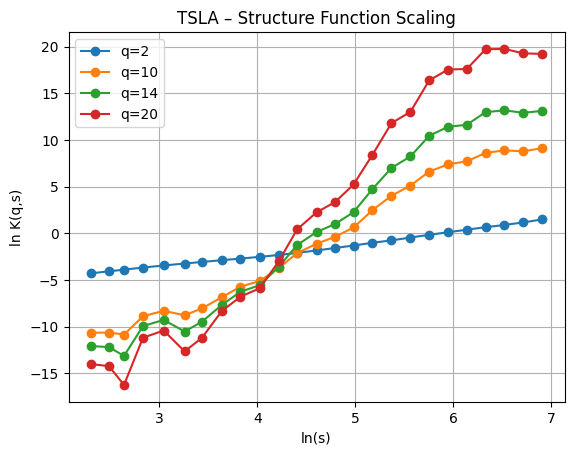

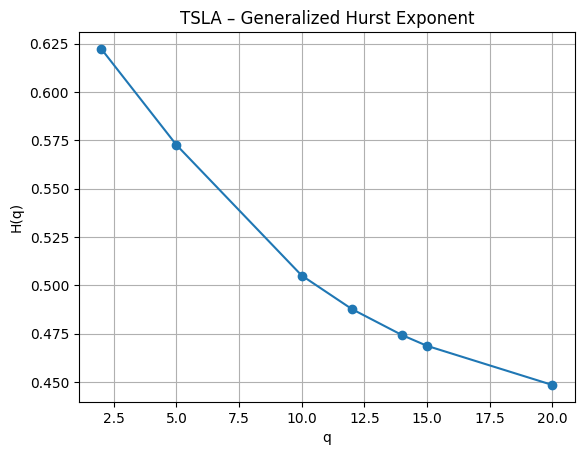

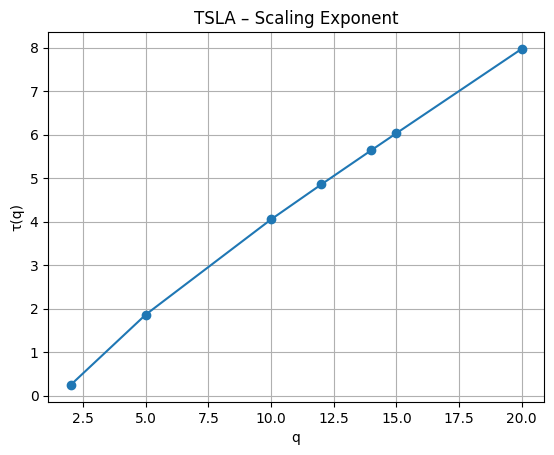

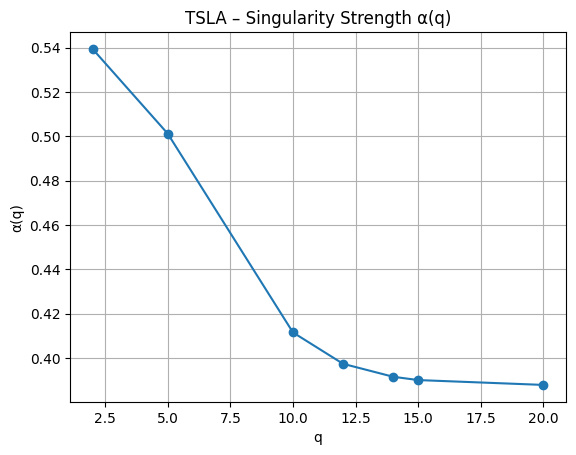

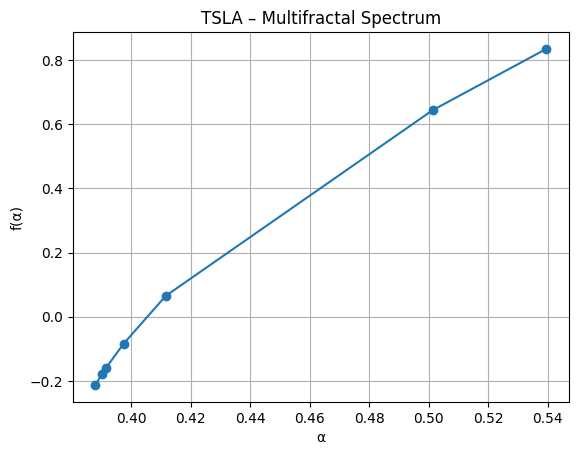


Processing AMZN...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_2600\325432460.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, progress=False)


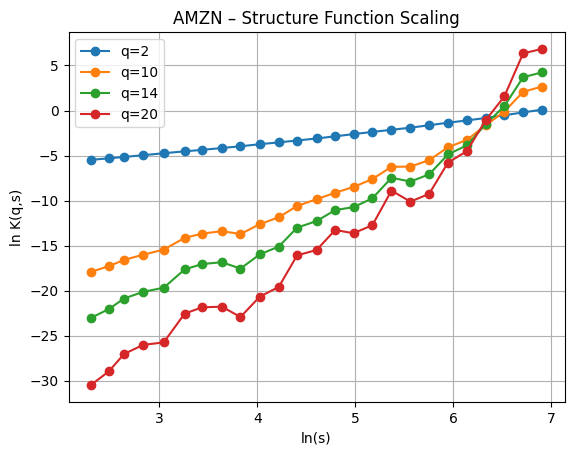

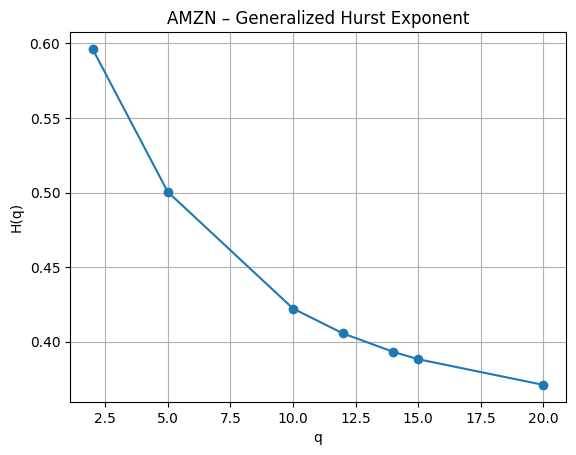

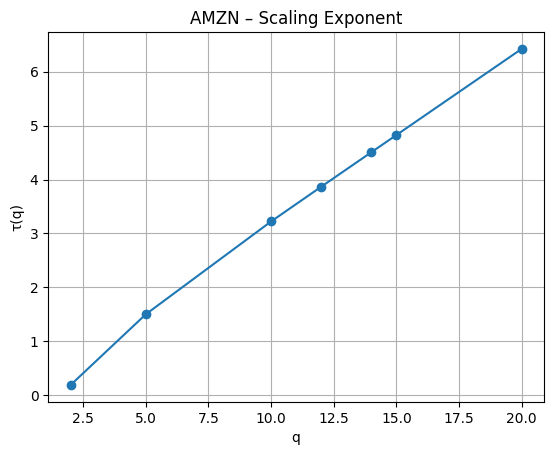

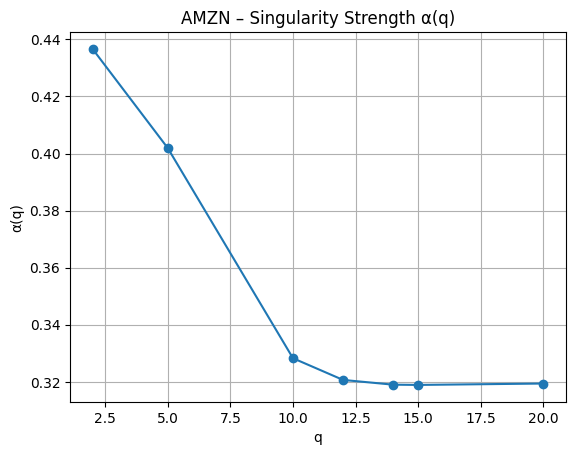

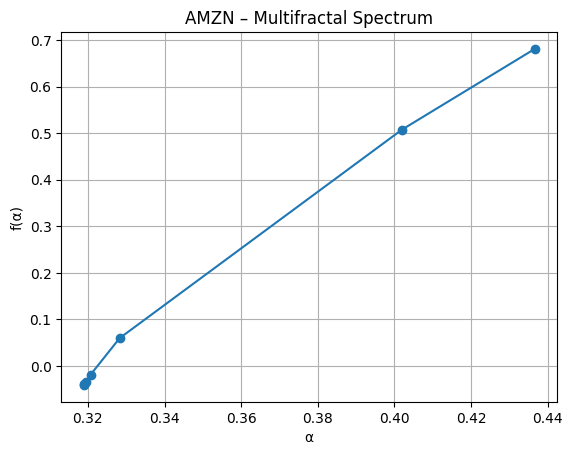


Processing GC=F...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_2600\325432460.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, progress=False)


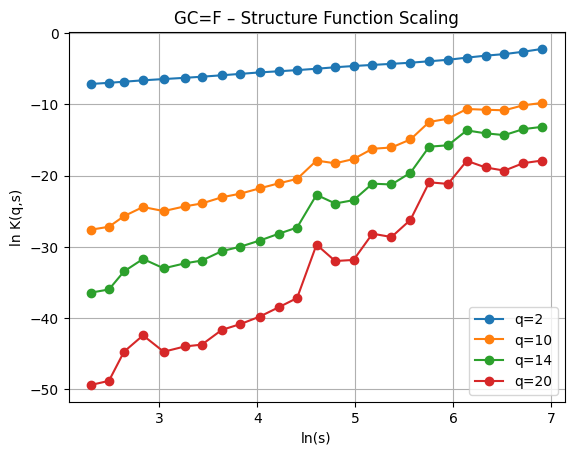

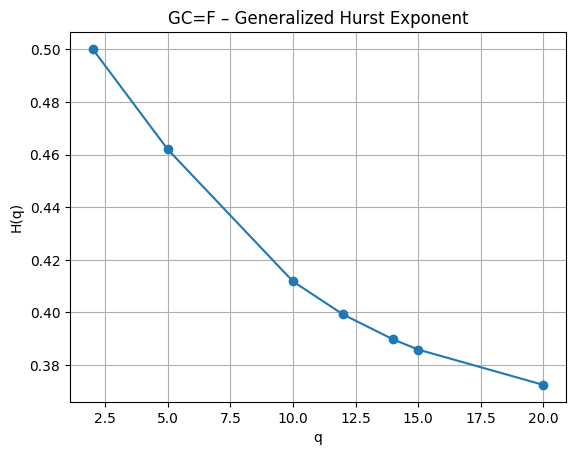

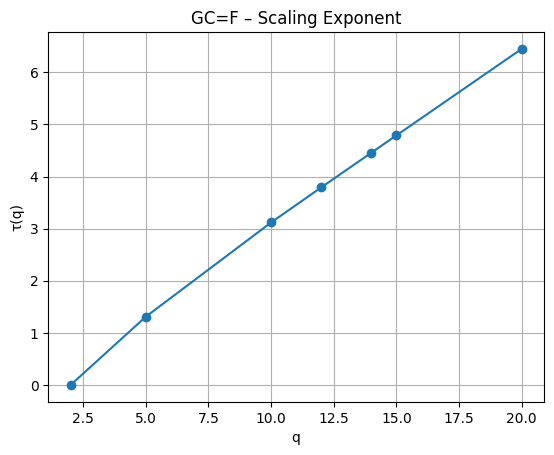

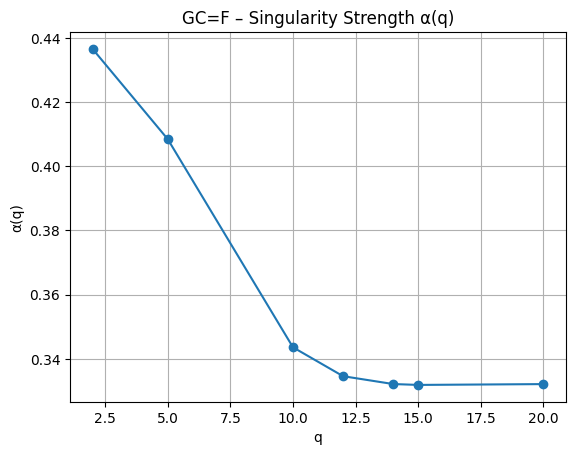

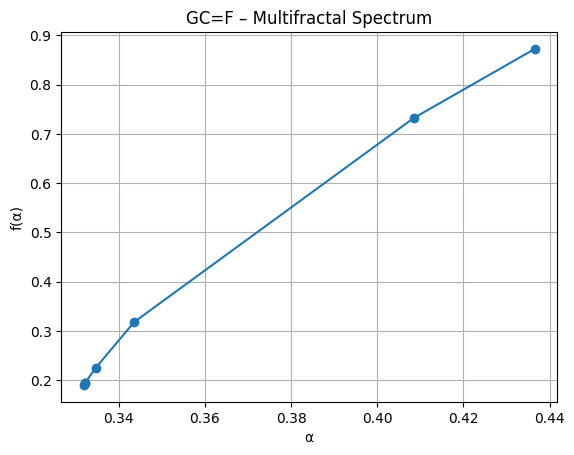


Processing BTC-USD...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_2600\325432460.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, progress=False)


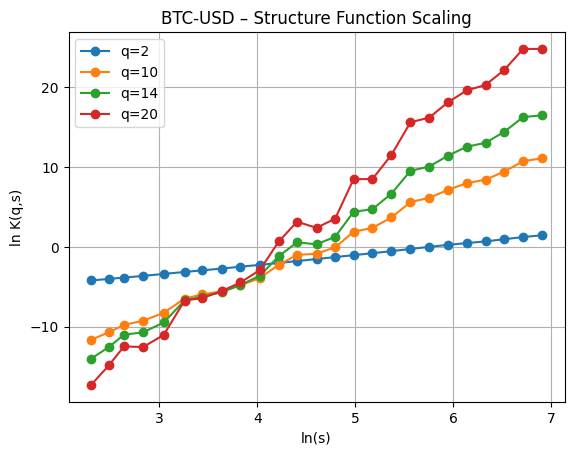

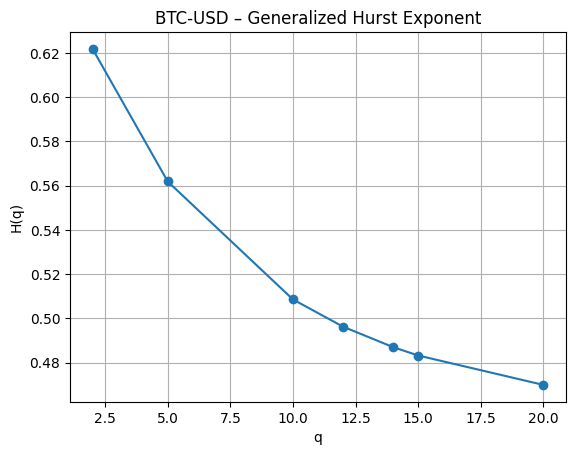

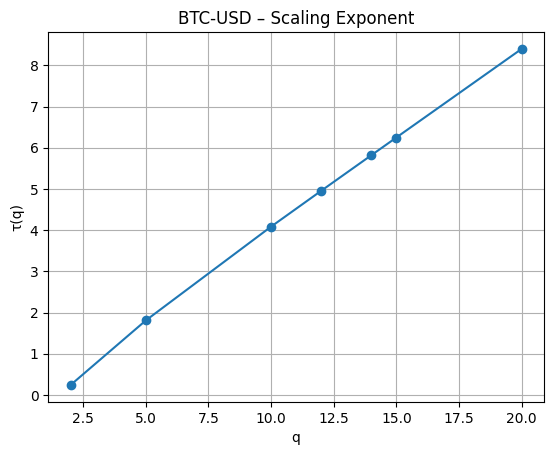

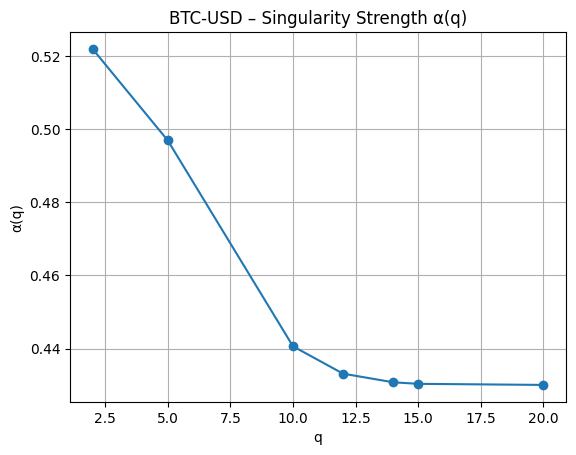

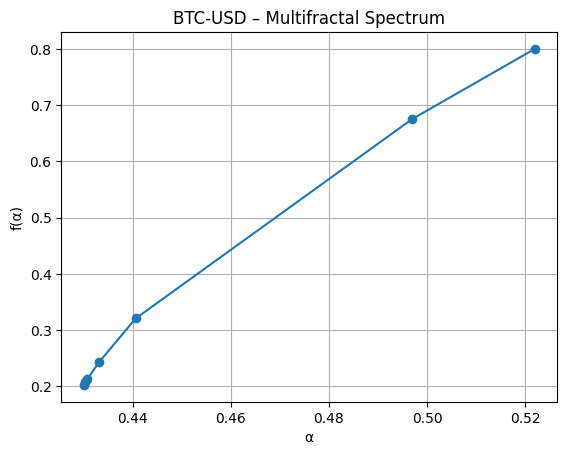

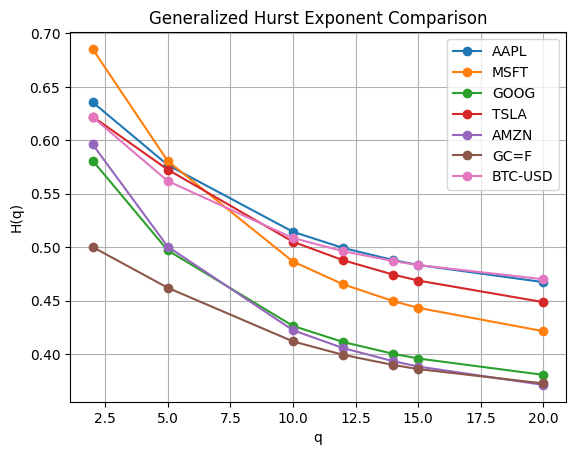

In [7]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import linregress

# =========================================================
# 1. SETTINGS
# =========================================================

stocks =  ["AAPL", "MSFT", "GOOG", "TSLA", "AMZN","GC=F","BTC-USD"]   # Multiple stocks
start_date = "2015-01-01"
end_date = "2024-01-01"

q_vals = [2, 5 , 10, 12, 14, 15, 20]      # q as natural numbers
s_vals = np.unique(np.logspace(1, 3, 25).astype(int))  # scales

# =========================================================
# 2. FUNCTIONS
# =========================================================

def get_log_price(ticker):
    data = yf.download(ticker, start=start_date, end=end_date, progress=False)
    return np.log(data["Close"].dropna().values)

def increments(X, s):
    return np.abs(X[s:] - X[:-s])

def structure_function(X, q, s):
    dx = increments(X, s)
    return np.mean(dx ** q)

# =========================================================
# 3. MAIN LOOP OVER STOCKS
# =========================================================

results = {}

for stock in stocks:
    print(f"\nProcessing {stock}...")
    
    X = get_log_price(stock)
    
    # ---- Compute K(q,s) ----
    K = np.zeros((len(q_vals), len(s_vals)))
    for i, q in enumerate(q_vals):
        for j, s in enumerate(s_vals):
            if s < len(X):
                K[i, j] = structure_function(X, q, s)
            else:
                K[i, j] = np.nan

    # ---- Estimate H(q) and τ(q) ----
    Hq = np.zeros(len(q_vals))
    tau_q = np.zeros(len(q_vals))
    log_s = np.log(s_vals)

    for i, q in enumerate(q_vals):
        valid = ~np.isnan(K[i])
        slope, _, _, _, _ = linregress(log_s[valid], np.log(K[i][valid]))
        Hq[i] = slope / q
        tau_q[i] = q * Hq[i] - 1

    # ---- α(q) and f(α) ----
    alpha = np.gradient(tau_q, q_vals)
    f_alpha = q_vals * alpha - tau_q

    results[stock] = {
        "K": K,
        "Hq": Hq,
        "tau_q": tau_q,
        "alpha": alpha,
        "f_alpha": f_alpha
    }

    # =====================================================
    # 4. PLOTS (PER STOCK)
    # =====================================================

    # ---- Plot 1: Structure function scaling ----
    plt.figure()
    for idx in [0, 2, 4, 6]:
        plt.plot(np.log(s_vals), np.log(K[idx]), 'o-', label=f'q={q_vals[idx]}')
    plt.xlabel("ln(s)")
    plt.ylabel("ln K(q,s)")
    plt.title(f"{stock} – Structure Function Scaling")
    plt.legend()
    plt.grid()
    plt.show()

    # ---- Plot 2: H(q) ----
    plt.figure()
    plt.plot(q_vals, Hq, 'o-')
    plt.xlabel("q")
    plt.ylabel("H(q)")
    plt.title(f"{stock} – Generalized Hurst Exponent")
    plt.grid()
    plt.show()

    # ---- Plot 3: τ(q) ----
    plt.figure()
    plt.plot(q_vals, tau_q, 'o-')
    plt.xlabel("q")
    plt.ylabel("τ(q)")
    plt.title(f"{stock} – Scaling Exponent")
    plt.grid()
    plt.show()

    # ---- Plot 4: α(q) vs q ----
    plt.figure()
    plt.plot(q_vals, alpha, 'o-')
    plt.xlabel("q")
    plt.ylabel("α(q)")
    plt.title(f"{stock} – Singularity Strength α(q)")
    plt.grid()
    plt.show()

    # ---- Plot 5: Multifractal spectrum ----
    plt.figure()
    plt.plot(alpha, f_alpha, 'o-')
    plt.xlabel("α")
    plt.ylabel("f(α)")
    plt.title(f"{stock} – Multifractal Spectrum")
    plt.grid()
    plt.show()

# =========================================================
# 5. COMPARISON PLOT (H(q) ACROSS STOCKS)
# =========================================================

plt.figure()
for stock in stocks:
    plt.plot(q_vals, results[stock]["Hq"], 'o-', label=stock)
plt.xlabel("q")
plt.ylabel("H(q)")
plt.title("Generalized Hurst Exponent Comparison")
plt.legend()
plt.grid()
plt.show()


# MF-FA


Processing AAPL


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\2422202548.py:53: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


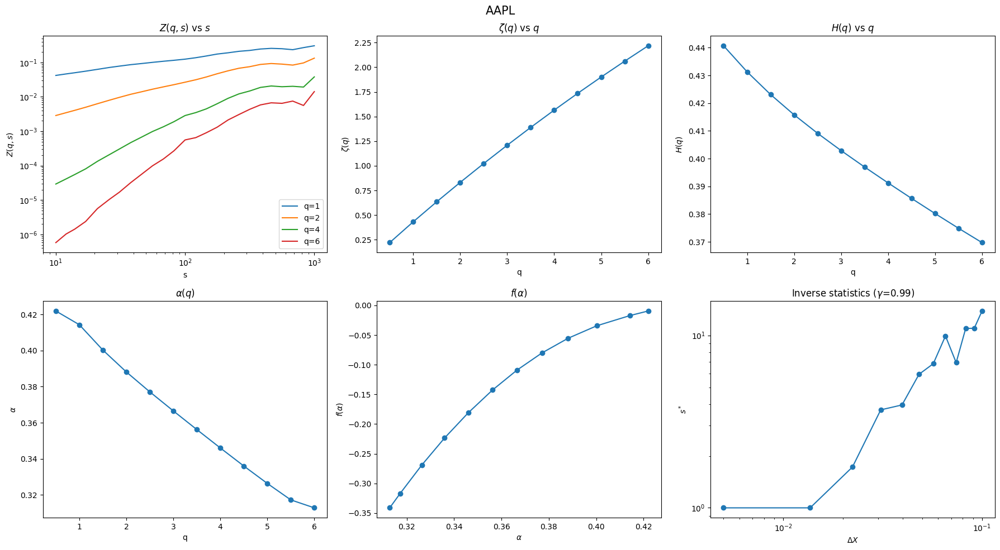

ζ(q):
q=0.5, ζ(q)=0.220
q=1.0, ζ(q)=0.431
q=1.5, ζ(q)=0.635
q=2.0, ζ(q)=0.832
q=2.5, ζ(q)=1.023
q=3.0, ζ(q)=1.209
q=3.5, ζ(q)=1.389
q=4.0, ζ(q)=1.565
q=4.5, ζ(q)=1.735
q=5.0, ζ(q)=1.901
q=5.5, ζ(q)=2.062
q=6.0, ζ(q)=2.218
Inverse scaling exponent γ ≈ 0.99

Processing MSFT


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\2422202548.py:53: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


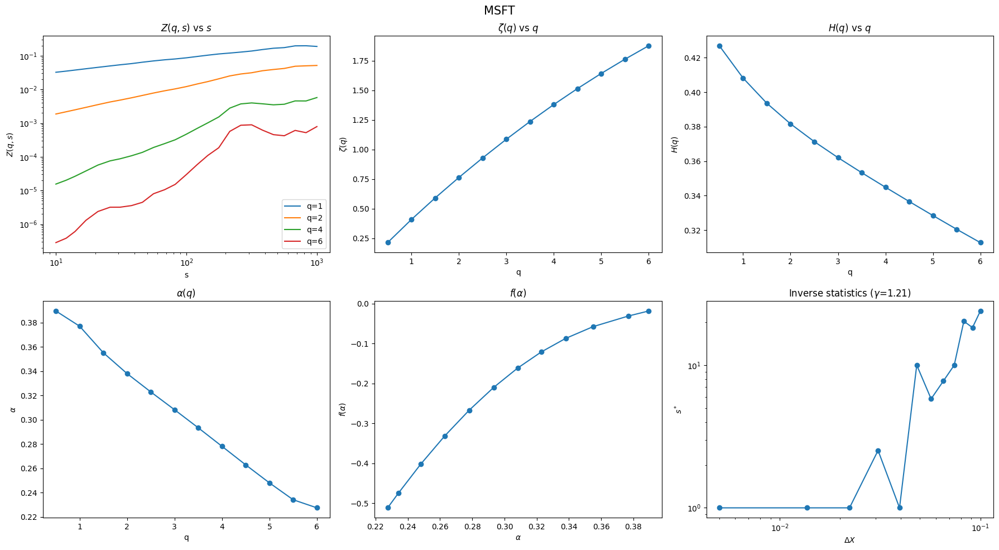

ζ(q):
q=0.5, ζ(q)=0.213
q=1.0, ζ(q)=0.408
q=1.5, ζ(q)=0.590
q=2.0, ζ(q)=0.763
q=2.5, ζ(q)=0.928
q=3.0, ζ(q)=1.086
q=3.5, ζ(q)=1.237
q=4.0, ζ(q)=1.379
q=4.5, ζ(q)=1.515
q=5.0, ζ(q)=1.642
q=5.5, ζ(q)=1.763
q=6.0, ζ(q)=1.876
Inverse scaling exponent γ ≈ 1.21

Processing GOOG


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\2422202548.py:53: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


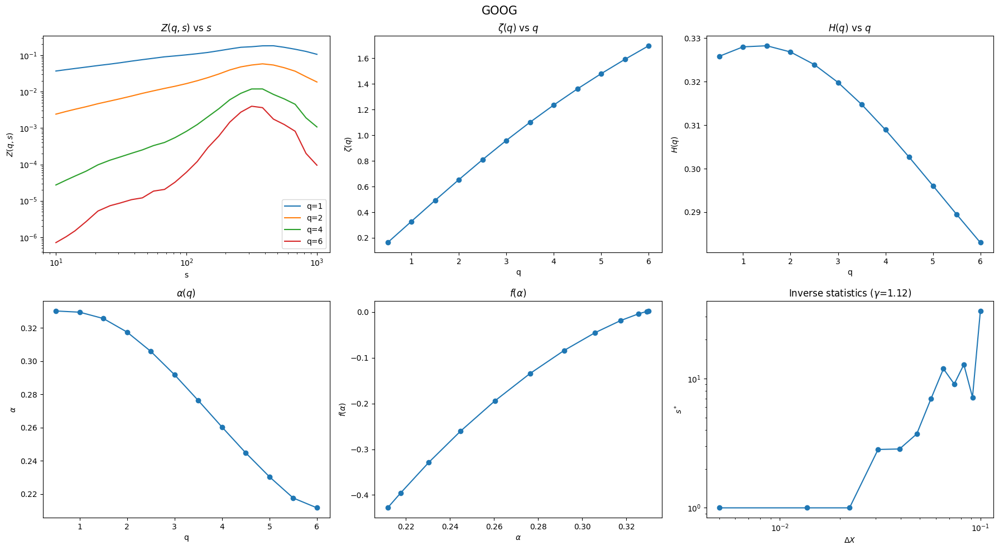

ζ(q):
q=0.5, ζ(q)=0.163
q=1.0, ζ(q)=0.328
q=1.5, ζ(q)=0.492
q=2.0, ζ(q)=0.654
q=2.5, ζ(q)=0.810
q=3.0, ζ(q)=0.959
q=3.5, ζ(q)=1.102
q=4.0, ζ(q)=1.236
q=4.5, ζ(q)=1.362
q=5.0, ζ(q)=1.480
q=5.5, ζ(q)=1.592
q=6.0, ζ(q)=1.698
Inverse scaling exponent γ ≈ 1.12

Processing TSLA


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\2422202548.py:53: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


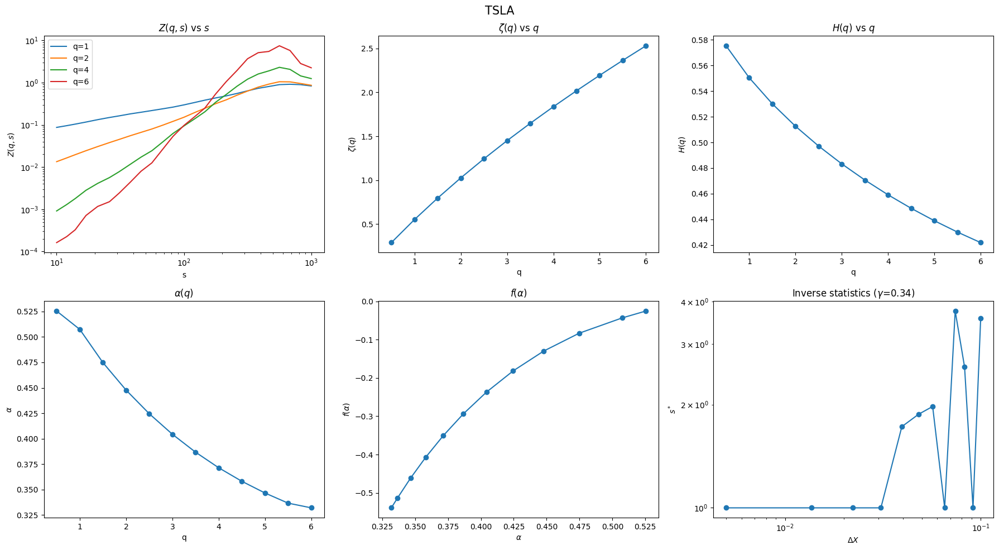

ζ(q):
q=0.5, ζ(q)=0.288
q=1.0, ζ(q)=0.550
q=1.5, ζ(q)=0.795
q=2.0, ζ(q)=1.025
q=2.5, ζ(q)=1.243
q=3.0, ζ(q)=1.450
q=3.5, ζ(q)=1.647
q=4.0, ζ(q)=1.836
q=4.5, ζ(q)=2.019
q=5.0, ζ(q)=2.195
q=5.5, ζ(q)=2.365
q=6.0, ζ(q)=2.531
Inverse scaling exponent γ ≈ 0.34

Processing AMZN


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\2422202548.py:53: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


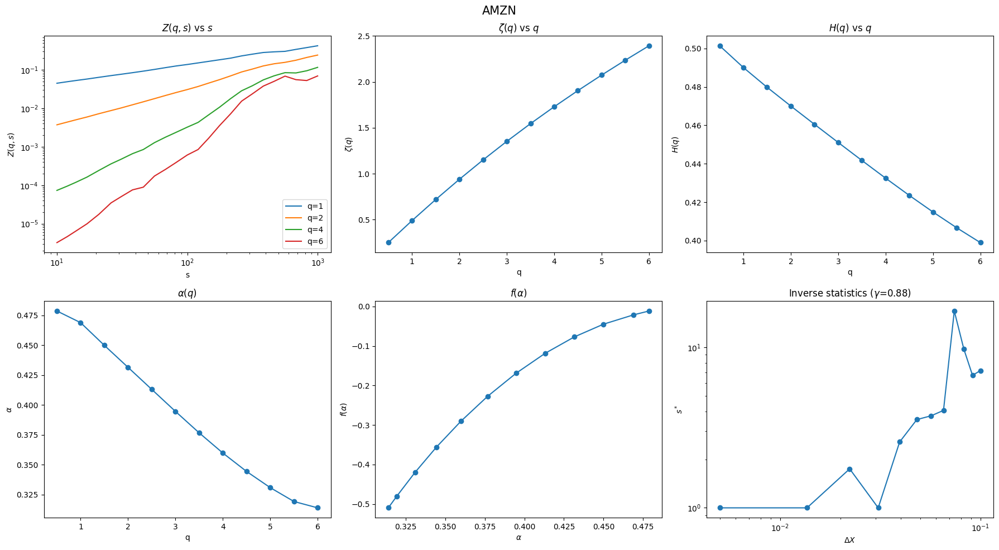

ζ(q):
q=0.5, ζ(q)=0.251
q=1.0, ζ(q)=0.490
q=1.5, ζ(q)=0.720
q=2.0, ζ(q)=0.940
q=2.5, ζ(q)=1.151
q=3.0, ζ(q)=1.353
q=3.5, ζ(q)=1.546
q=4.0, ζ(q)=1.730
q=4.5, ζ(q)=1.906
q=5.0, ζ(q)=2.074
q=5.5, ζ(q)=2.237
q=6.0, ζ(q)=2.394
Inverse scaling exponent γ ≈ 0.88

Processing GC=F


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\2422202548.py:53: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


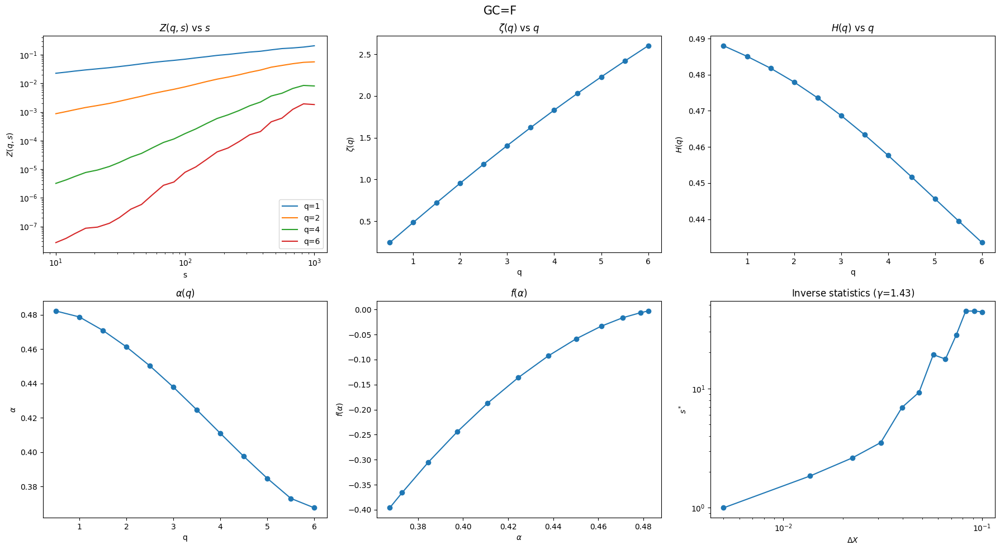

ζ(q):
q=0.5, ζ(q)=0.244
q=1.0, ζ(q)=0.485
q=1.5, ζ(q)=0.723
q=2.0, ζ(q)=0.956
q=2.5, ζ(q)=1.184
q=3.0, ζ(q)=1.406
q=3.5, ζ(q)=1.622
q=4.0, ζ(q)=1.831
q=4.5, ζ(q)=2.033
q=5.0, ζ(q)=2.228
q=5.5, ζ(q)=2.417
q=6.0, ζ(q)=2.601
Inverse scaling exponent γ ≈ 1.43

Processing BTC-USD


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\2422202548.py:53: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


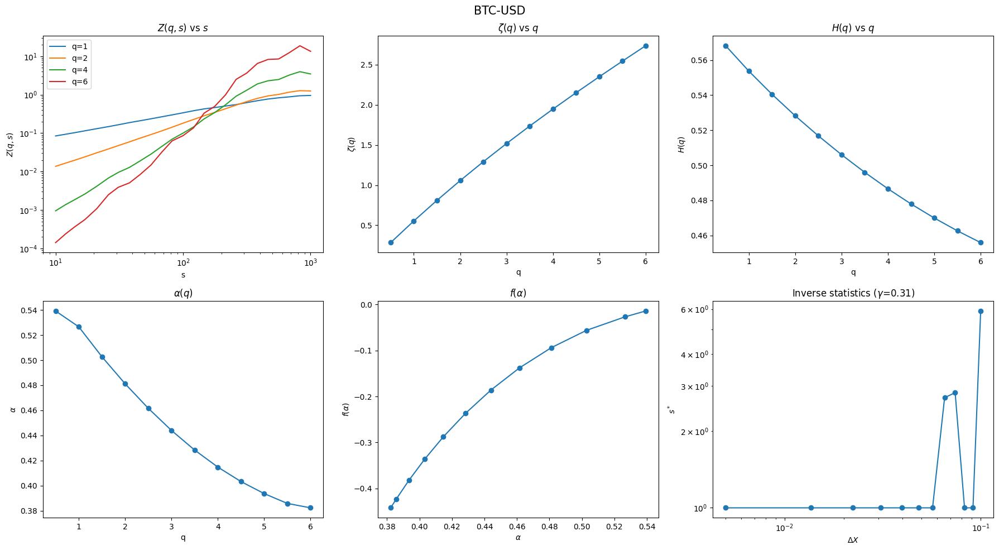

ζ(q):
q=0.5, ζ(q)=0.284
q=1.0, ζ(q)=0.554
q=1.5, ζ(q)=0.811
q=2.0, ζ(q)=1.056
q=2.5, ζ(q)=1.292
q=3.0, ζ(q)=1.518
q=3.5, ζ(q)=1.736
q=4.0, ζ(q)=1.946
q=4.5, ζ(q)=2.151
q=5.0, ζ(q)=2.350
q=5.5, ζ(q)=2.544
q=6.0, ζ(q)=2.735
Inverse scaling exponent γ ≈ 0.31


In [11]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import linregress

# =========================================================
# PARAMETERS
# =========================================================
tickers = ["AAPL", "MSFT", "GOOG", "TSLA", "AMZN", "GC=F", "BTC-USD"]
start = "2012-01-01"
end = "2025-01-01"

q_vals = np.arange(0.5, 6.5, 0.5)
scales = np.unique(np.logspace(1, 3, 25).astype(int))
delta_X_vals = np.linspace(0.005, 0.1, 12)

# =========================================================
# MF-FA (Increment-based, classical)
# =========================================================
def mf_fa(series, q_vals, scales):
    Z = {q: [] for q in q_vals}
    zeta = []

    for q in q_vals:
        for s in scales:
            inc = series[s:] - series[:-s]
            inc -= inc.mean()
            Z[q].append(np.mean(np.abs(inc) ** q))

        slope, _, _, _, _ = linregress(np.log(scales), np.log(Z[q]))
        zeta.append(slope)

    return np.array(zeta), Z

# =========================================================
# INVERSE STATISTICS
# =========================================================
def inverse_exit_times(series, delta_X):
    exit_times = []
    for i in range(len(series)):
        for s in range(1, len(series) - i):
            if abs(series[i + s] - series[i]) >= delta_X:
                exit_times.append(s)
                break
    return np.array(exit_times)

# =========================================================
# MAIN LOOP
# =========================================================
for ticker in tickers:
    print(f"\nProcessing {ticker}")

    data = yf.download(ticker, start=start, end=end, progress=False)
    log_prices = np.log(data["Close"].dropna().values)

    # ---------------- MF-FA ----------------
    zeta_q, Zqs = mf_fa(log_prices, q_vals, scales)
    Hq = zeta_q / q_vals

    alpha = np.gradient(zeta_q, q_vals)
    f_alpha = q_vals * alpha - zeta_q

    # ---------------- Inverse statistics ----------------
    s_star = []
    for dx in delta_X_vals:
        exits = inverse_exit_times(log_prices, dx)
        if len(exits) > 0:
            hist, bins = np.histogram(exits, bins=40, density=True)
            s_star.append(bins[np.argmax(hist)])
        else:
            s_star.append(np.nan)

    valid = ~np.isnan(s_star)
    gamma, _, _, _, _ = linregress(
        np.log(delta_X_vals[valid]),
        np.log(np.array(s_star)[valid])
    )

    # =====================================================
    # PLOTS
    # =====================================================
    fig, axs = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle(ticker, fontsize=15)

    # (1) Z(q,s) vs s (log-log)
    for q in [1, 2, 4, 6]:
        axs[0, 0].loglog(scales, Zqs[q], label=f"q={q}")
    axs[0, 0].set_title(r"$Z(q,s)$ vs $s$")
    axs[0, 0].set_xlabel("s")
    axs[0, 0].set_ylabel(r"$Z(q,s)$")
    axs[0, 0].legend()

    # (2) ζ(q)
    axs[0, 1].plot(q_vals, zeta_q, 'o-')
    axs[0, 1].set_title(r"$\zeta(q)$ vs $q$")
    axs[0, 1].set_xlabel("q")
    axs[0, 1].set_ylabel(r"$\zeta(q)$")

    # (3) H(q)
    axs[0, 2].plot(q_vals, Hq, 'o-')
    axs[0, 2].set_title(r"$H(q)$ vs $q$")
    axs[0, 2].set_xlabel("q")
    axs[0, 2].set_ylabel(r"$H(q)$")

    # (4) α(q)
    axs[1, 0].plot(q_vals, alpha, 'o-')
    axs[1, 0].set_title(r"$\alpha(q)$")
    axs[1, 0].set_xlabel("q")
    axs[1, 0].set_ylabel(r"$\alpha$")

    # (5) f(α)
    axs[1, 1].plot(alpha, f_alpha, 'o-')
    axs[1, 1].set_title(r"$f(\alpha)$")
    axs[1, 1].set_xlabel(r"$\alpha$")
    axs[1, 1].set_ylabel(r"$f(\alpha)$")

    # (6) Inverse statistics
    axs[1, 2].loglog(delta_X_vals, s_star, 'o-')
    axs[1, 2].set_title(rf"Inverse statistics ($\gamma$={gamma:.2f})")
    axs[1, 2].set_xlabel(r"$\Delta X$")
    axs[1, 2].set_ylabel(r"$s^*$")

    plt.tight_layout()
    plt.show()

    # ---------------- PRINT NUMBERS ----------------
    print("ζ(q):")
    for q, z in zip(q_vals, zeta_q):
        print(f"q={q:.1f}, ζ(q)={z:.3f}")

    print(f"Inverse scaling exponent γ ≈ {gamma:.2f}")


Processing AAPL...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\724628588.py:43: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


Processing MSFT...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\724628588.py:43: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


Processing GOOG...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\724628588.py:43: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


Processing TSLA...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\724628588.py:43: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


Processing AMZN...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\724628588.py:43: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


Processing GC=F...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\724628588.py:43: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


Processing BTC-USD...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\724628588.py:43: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


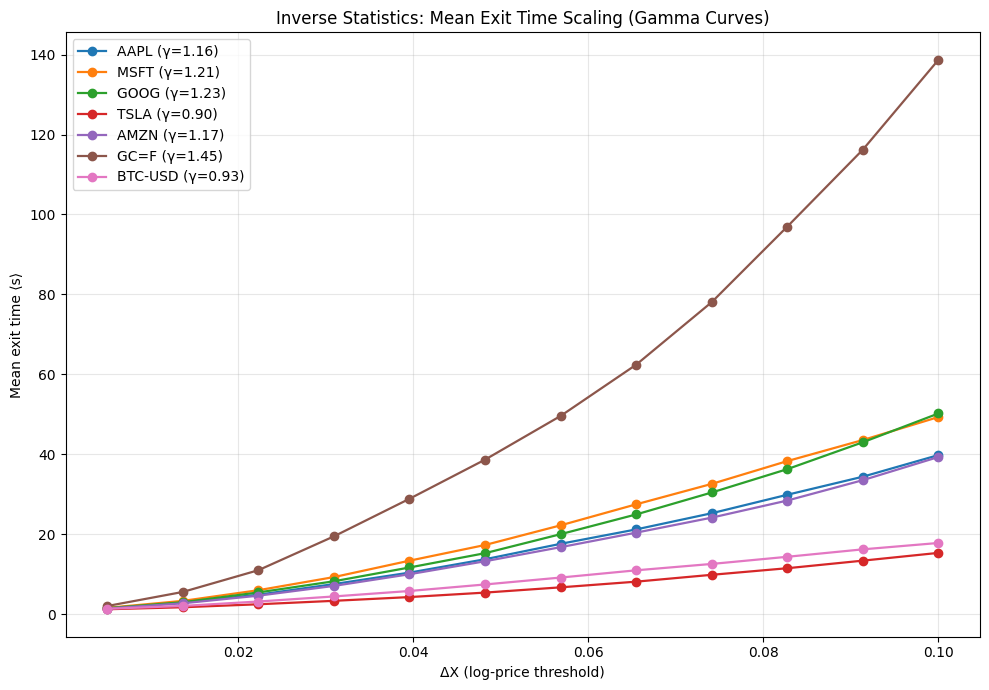

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\724628588.py:86: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\724628588.py:86: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\724628588.py:86: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\724628588.py:86: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\724628588.py:86: FutureWarning: YF.download() has changed argument auto_adjust default to True
  

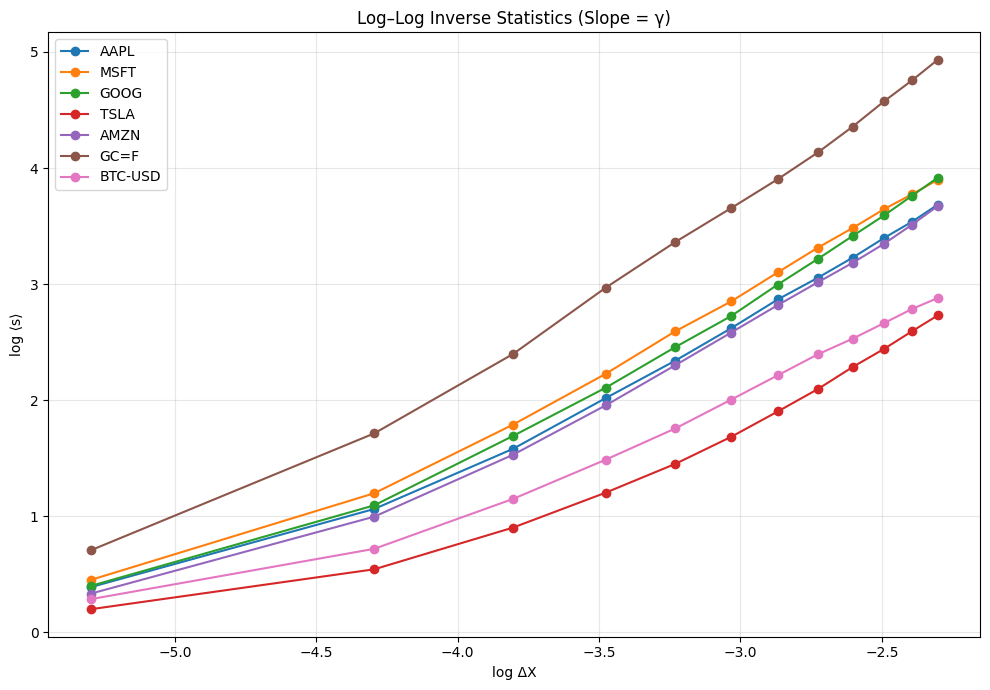


Estimated Gamma Exponents:
AAPL       : γ = 1.155
MSFT       : γ = 1.213
GOOG       : γ = 1.228
TSLA       : γ = 0.896
AMZN       : γ = 1.166
GC=F       : γ = 1.452
BTC-USD    : γ = 0.931


In [10]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

# =============================
# Parameters
# =============================
tickers = ["AAPL", "MSFT", "GOOG", "TSLA", "AMZN", "GC=F", "BTC-USD"]
start = "2015-01-01"
end   = "2025-01-01"

delta_X_vals = np.linspace(0.005, 0.1, 12)  # thresholds
max_search = 2000                            # safety cap

# =============================
# Mean exit time function
# =============================
def mean_exit_time(log_prices, delta_X):
    N = len(log_prices)
    exit_times = []

    for t in range(N):
        for s in range(1, min(max_search, N - t)):
            if abs(log_prices[t + s] - log_prices[t]) >= delta_X:
                exit_times.append(s)
                break

    if len(exit_times) == 0:
        return np.nan

    return np.mean(exit_times)

# =============================
# Main experiment
# =============================
plt.figure(figsize=(10, 7))

gamma_results = {}

for ticker in tickers:
    print(f"Processing {ticker}...")

    data = yf.download(ticker, start=start, end=end, progress=False)
    prices = data["Close"].dropna().values

    # Log prices (CRITICAL)
    log_prices = np.log(prices)

    mean_s = np.array([
        mean_exit_time(log_prices, dx)
        for dx in delta_X_vals
    ])

    # Remove NaNs
    valid = ~np.isnan(mean_s)
    dx = delta_X_vals[valid]
    s  = mean_s[valid]

    # Gamma fit
    log_dx = np.log(dx)
    log_s  = np.log(s)

    gamma, intercept = np.polyfit(log_dx, log_s, 1)
    gamma_results[ticker] = gamma

    # Plot gamma curve
    plt.plot(dx, s, marker="o", linewidth=1.6, label=f"{ticker} (γ={gamma:.2f})")

# =============================
# Plot styling
# =============================
plt.xlabel("ΔX (log-price threshold)")
plt.ylabel("Mean exit time ⟨s⟩")
plt.title("Inverse Statistics: Mean Exit Time Scaling (Gamma Curves)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# =============================
# Log–log plot (optional but recommended)
# =============================
plt.figure(figsize=(10, 7))

for ticker in tickers:
    data = yf.download(ticker, start=start, end=end, progress=False)
    prices = data["Close"].dropna().values
    log_prices = np.log(prices)

    mean_s = np.array([
        mean_exit_time(log_prices, dx)
        for dx in delta_X_vals
    ])

    valid = ~np.isnan(mean_s)
    dx = delta_X_vals[valid]
    s  = mean_s[valid]

    plt.plot(np.log(dx), np.log(s), marker="o", linewidth=1.5, label=ticker)

plt.xlabel("log ΔX")
plt.ylabel("log ⟨s⟩")
plt.title("Log–Log Inverse Statistics (Slope = γ)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# =============================
# Print gamma values
# =============================
print("\nEstimated Gamma Exponents:")
for k, v in gamma_results.items():
    print(f"{k:10s} : γ = {v:.3f}")


# MF-FA using ESS

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\3714163415.py:30: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2010-01-01", progress=False)


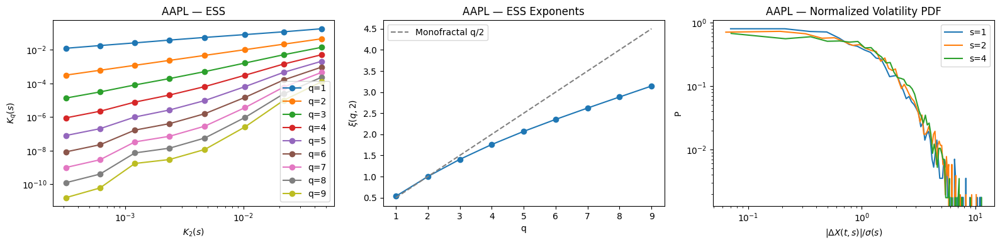

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\3714163415.py:30: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2010-01-01", progress=False)


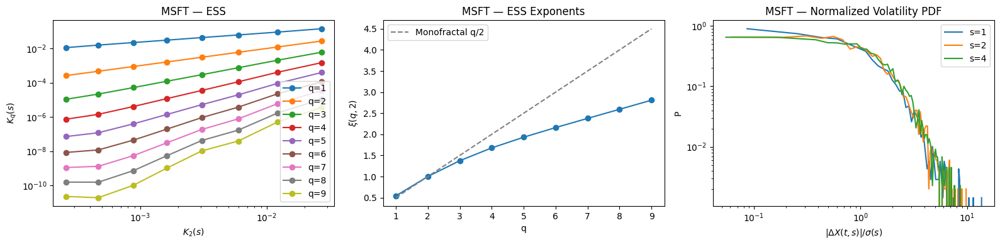

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\3714163415.py:30: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2010-01-01", progress=False)


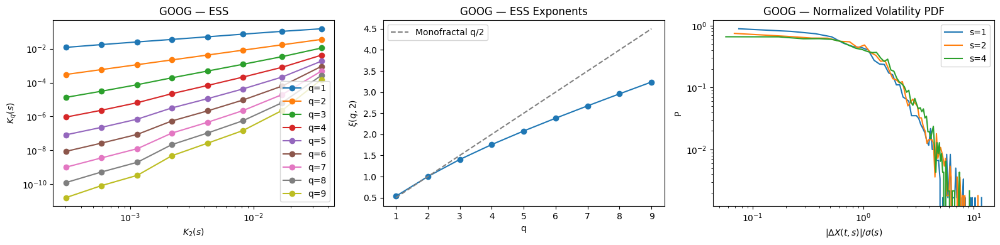

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\3714163415.py:30: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2010-01-01", progress=False)


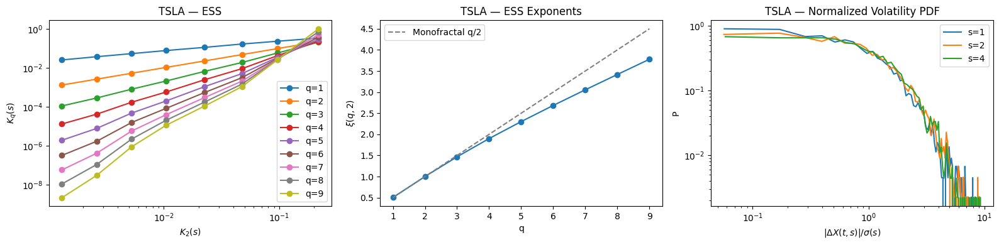

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\3714163415.py:30: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2010-01-01", progress=False)


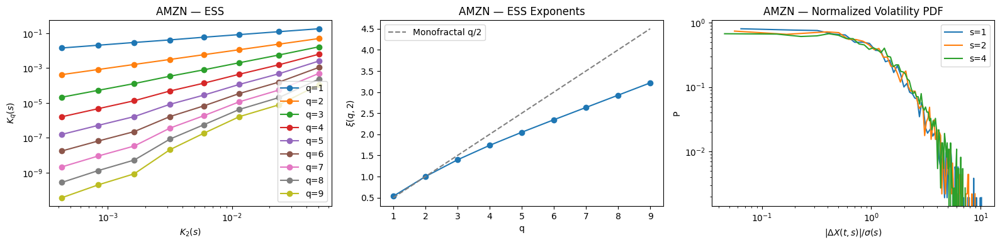

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\3714163415.py:30: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2010-01-01", progress=False)


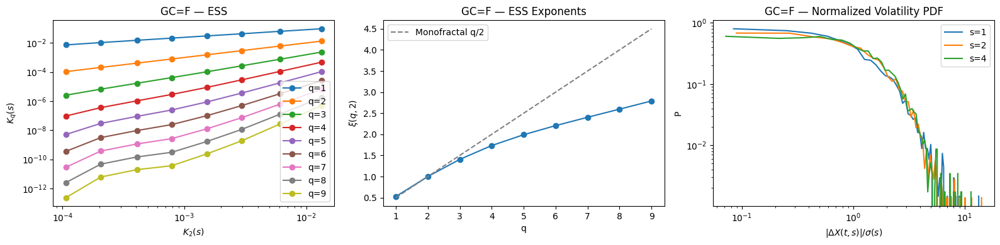

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_14372\3714163415.py:30: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2010-01-01", progress=False)


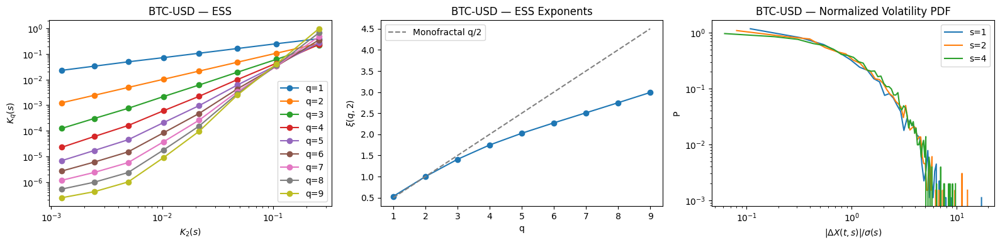

In [7]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import linregress

# ------------------------------------
# Stocks
# ------------------------------------
tickers = ["AAPL", "MSFT", "GOOG", "TSLA", "AMZN", "GC=F", "BTC-USD"]

# ------------------------------------
# Parameters
# ------------------------------------
qs = np.arange(1, 10)
q0 = 2
scales = np.array([1, 2, 4, 8, 16, 32, 64, 128])

# ------------------------------------
# Structure function K(q,s)
# ------------------------------------
def structure_function(x, q, s):
    dx = np.abs(x[s:] - x[:-s])
    return np.mean(dx**q)

# ------------------------------------
# Loop over assets
# ------------------------------------
for ticker in tickers:

    data = yf.download(ticker, start="2010-01-01", progress=False)
    prices = data["Close"].dropna().values

    if len(prices) < 1500:
        continue

    x = np.log(prices)

    # --------------------------------
    # Compute K(q,s)
    # --------------------------------
    K = {q: [] for q in qs}
    for s in scales:
        for q in qs:
            K[q].append(structure_function(x, q, s))

    # --------------------------------
    # ESS exponents ξ(q,2)
    # --------------------------------
    xi = []
    for q in qs:
        slope, _, _, _, _ = linregress(
            np.log(K[q0]),
            np.log(K[q])
        )
        xi.append(slope)

    # --------------------------------
    # Plot
    # --------------------------------
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    # (a) ESS plot
    for q in qs:
        axes[0].plot(
            K[q0],
            K[q],
            marker="o",
            label=f"q={q}"
        )

    axes[0].set_xscale("log")
    axes[0].set_yscale("log")
    axes[0].set_xlabel(r"$K_2(s)$")
    axes[0].set_ylabel(r"$K_q(s)$")
    axes[0].set_title(f"{ticker} — ESS")
    axes[0].legend()

    # (b) ξ(q,2)
    axes[1].plot(qs, xi, marker="o")
    axes[1].plot(qs, qs/2, "--", color="gray", label="Monofractal q/2")
    axes[1].set_xlabel("q")
    axes[1].set_ylabel(r"$\xi(q,2)$")
    axes[1].set_title(f"{ticker} — ESS Exponents")
    axes[1].legend()

    # (c) Normalized volatility PDFs
    for s in [1, 2, 4]:
        v = np.abs(x[s:] - x[:-s])
        v /= np.std(v)

        hist, bins = np.histogram(v, bins=80, density=True)
        centers = 0.5 * (bins[1:] + bins[:-1])

        axes[2].plot(
            centers,
            hist,
            label=f"s={s}"
        )

    axes[2].set_xscale("log")
    axes[2].set_yscale("log")
    axes[2].set_xlabel(r"$|\Delta X(t,s)|/\sigma(s)$")
    axes[2].set_ylabel("P")
    axes[2].set_title(f"{ticker} — Normalized Volatility PDF")
    axes[2].legend()

    plt.tight_layout()
    plt.show()


# MF- WT

In [4]:
!pip install PyWavelets


   ---------------------------------------- 0.0/4.2 MB ? eta -:--:--
   ------- -------------------------------- 0.8/4.2 MB 4.8 MB/s eta 0:00:01
   ----------------- ---------------------- 1.8/4.2 MB 5.0 MB/s eta 0:00:01
   ----------------------------- ---------- 3.1/4.2 MB 5.8 MB/s eta 0:00:01
   ---------------------------------------- 4.2/4.2 MB 5.9 MB/s eta 0:00:00



[notice] A new release of pip is available: 25.0.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\152931186.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=START, end=END)
[*********************100%***********************]  1 of 1 completed


Analyzing AAPL



C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\152931186.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=START, end=END)
[*********************100%***********************]  1 of 1 completed


Analyzing MSFT



C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\152931186.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=START, end=END)
[*********************100%***********************]  1 of 1 completed


Analyzing GOOG



C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\152931186.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=START, end=END)
[*********************100%***********************]  1 of 1 completed


Analyzing TSLA



C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\152931186.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=START, end=END)
[*********************100%***********************]  1 of 1 completed


Analyzing AMZN



Analyzing GC=F


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\152931186.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=START, end=END)
[*********************100%***********************]  1 of 1 completed



Analyzing BTC-USD


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\152931186.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=START, end=END)
[*********************100%***********************]  1 of 1 completed



Plotting results...


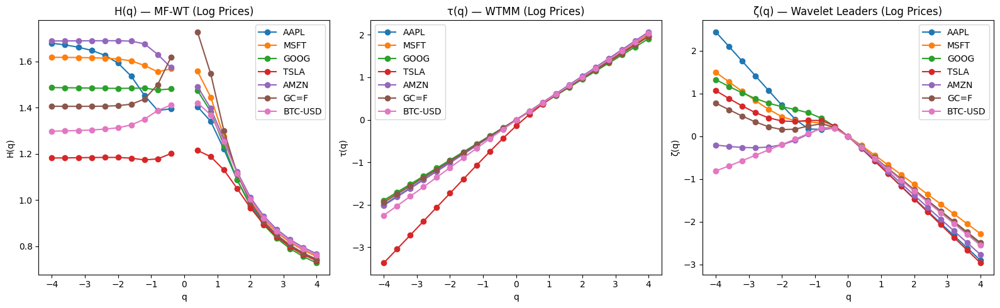


Done.


In [12]:
import numpy as np
import pandas as pd
import yfinance as yf
import pywt
import matplotlib.pyplot as plt

from scipy.signal import find_peaks
from scipy.stats import linregress


# =====================================================
# PARAMETERS
# =====================================================

TICKERS =  ["AAPL", "MSFT", "GOOG", "TSLA", "AMZN", "GC=F", "BTC-USD"]

START = "2018-01-01"
END = "2026-01-01"

Q = np.linspace(-4, 4, 21)
SCALES = np.arange(2, 256)

WAVELET = "mexh"   # Mexican hat


# =====================================================
# DATA LOADER (LOG PRICES)
# =====================================================

def load_log_prices(ticker):

    data = yf.download(ticker, start=START, end=END)

    price = data["Close"]

    # Safety: force Series
    if isinstance(price, pd.DataFrame):
        price = price.iloc[:, 0]

    price = price.dropna()

    log_price = np.log(price)

    return log_price.values.flatten()


# =====================================================
# CONTINUOUS WAVELET TRANSFORM
# =====================================================

def compute_cwt(signal):

    signal = np.asarray(signal).flatten()

    coef, _ = pywt.cwt(
        signal,
        scales=SCALES,
        wavelet=WAVELET
    )

    return np.squeeze(coef)   # (scale, time)


# =====================================================
# MF-WT (MOMENT METHOD)
# =====================================================

def mf_wt(coef):

    coef = np.squeeze(coef)

    moments = {}

    for q in Q:

        mq = []

        for i in range(coef.shape[0]):

            W = np.abs(coef[i]).flatten()

            if q < 0:
                W = W[W > 1e-10]

            if len(W) == 0:
                continue

            mq.append(np.mean(W ** q))

        moments[q] = np.array(mq)

    return moments


def estimate_Hq(moments):

    Hq = {}

    log_s = np.log(SCALES)

    for q in Q:

        mq = moments[q]

        if len(mq) < 10:
            Hq[q] = np.nan
            continue

        log_m = np.log(mq)

        slope, _, _, _, _ = linregress(
            log_s[:len(log_m)],
            log_m
        )

        if abs(q) < 0.2:
            Hq[q] = np.nan
        else:
            Hq[q] = slope / q

    return Hq


# =====================================================
# WTMM
# =====================================================

def wtmm_partition(coef):

    coef = np.squeeze(coef)

    Z = {}

    for q in Q:

        Zq = []

        for i in range(coef.shape[0]):

            W = np.abs(coef[i]).flatten()

            if len(W) < 10:
                continue

            # Find meaningful maxima
            peaks, _ = find_peaks(
                W,
                distance=3,
                prominence=np.std(W)
            )

            if len(peaks) < 1:
                continue

            Wmax = W[peaks]

            if q < 0:
                Wmax = Wmax[Wmax > 1e-10]

            if len(Wmax) == 0:
                continue

            Zq.append(np.sum(Wmax ** q))

        Z[q] = np.array(Zq)

    return Z


def estimate_tau(Z):

    tau = {}

    valid_lengths = [
        len(v) for v in Z.values() if len(v) > 10
    ]

    if len(valid_lengths) == 0:
        return {q: np.nan for q in Q}

    base_len = min(valid_lengths)

    log_s = np.log(SCALES[:base_len])

    for q in Q:

        Zq = Z[q][:base_len]

        if len(Zq) < 5:
            tau[q] = np.nan
            continue

        logZ = np.log(Zq)

        slope, _, _, _, _ = linregress(
            log_s,
            logZ
        )

        tau[q] = slope

    return tau


# =====================================================
# WAVELET LEADERS
# =====================================================

def wavelet_leaders(signal, level=7):

    signal = np.asarray(signal).flatten()

    coeffs = pywt.wavedec(signal, "db2", level=level)

    leaders = []

    for j in range(1, len(coeffs)):

        detail = np.abs(coeffs[j])

        # Local sup (simplified leader)
        leader = np.maximum.accumulate(detail)

        leaders.append(leader)

    return leaders


def leader_moments(leaders):

    M = {}

    for q in Q:

        mq = []

        for L in leaders:

            L = np.asarray(L).flatten()

            if q < 0:
                L = L[L > 1e-10]

            if len(L) == 0:
                continue

            mq.append(np.mean(L ** q))

        M[q] = np.array(mq)

    return M


def estimate_zeta(M):

    zeta = {}

    j = np.arange(1, len(list(M.values())[0]) + 1)

    log_s = np.log(2 ** j)

    for q in Q:

        Mq = M[q]

        if len(Mq) < 5:
            zeta[q] = np.nan
            continue

        logM = np.log(Mq)

        slope, _, _, _, _ = linregress(
            log_s[:len(logM)],
            logM
        )

        zeta[q] = slope

    return zeta


# =====================================================
# ANALYSIS PER STOCK
# =====================================================

def analyze_stock(ticker):

    print(f"\nAnalyzing {ticker}")

    signal = load_log_prices(ticker)

    coef = compute_cwt(signal)

    # MF-WT
    moments = mf_wt(coef)
    Hq = estimate_Hq(moments)

    # WTMM
    Z = wtmm_partition(coef)
    tau = estimate_tau(Z)

    # Leaders
    leaders = wavelet_leaders(signal)
    leaders_M = leader_moments(leaders)
    zeta = estimate_zeta(leaders_M)

    return Hq, tau, zeta


# =====================================================
# COMPARISON PLOTS
# =====================================================

def plot_multifractal_spectra(results):

    plt.figure(figsize=(16, 5))

    # ---------- H(q)
    plt.subplot(1, 3, 1)

    for ticker, res in results.items():

        plt.plot(
            Q,
            list(res["Hq"].values()),
            marker="o",
            label=ticker
        )

    plt.title("H(q) — MF-WT (Log Prices)")
    plt.xlabel("q")
    plt.ylabel("H(q)")
    plt.legend()


    # ---------- tau(q)
    plt.subplot(1, 3, 2)

    for ticker, res in results.items():

        plt.plot(
            Q,
            list(res["tau"].values()),
            marker="o",
            label=ticker
        )

    plt.title("τ(q) — WTMM (Log Prices)")
    plt.xlabel("q")
    plt.ylabel("τ(q)")
    plt.legend()


    # ---------- zeta(q)
    plt.subplot(1, 3, 3)

    for ticker, res in results.items():

        plt.plot(
            Q,
            list(res["zeta"].values()),
            marker="o",
            label=ticker
        )

    plt.title("ζ(q) — Wavelet Leaders (Log Prices)")
    plt.xlabel("q")
    plt.ylabel("ζ(q)")
    plt.legend()


    plt.tight_layout()
    plt.show()


# =====================================================
# MAIN PIPELINE
# =====================================================

def main():

    results = {}

    for ticker in TICKERS:

        Hq, tau, zeta = analyze_stock(ticker)

        results[ticker] = {
            "Hq": Hq,
            "tau": tau,
            "zeta": zeta
        }

    print("\nPlotting results...")
    plot_multifractal_spectra(results)

    print("\nDone.")


# =====================================================
# RUN
# =====================================================

if __name__ == "__main__":
    main()


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\4041494226.py:30: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=START, end=END)
[*********************100%***********************]  1 of 1 completed
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\4041494226.py:30: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=START, end=END)
[*********************100%***********************]  1 of 1 completed

Processing AAPL...
Processing MSFT...
Processing GOOG...



C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\4041494226.py:30: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=START, end=END)
[*********************100%***********************]  1 of 1 completed
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\4041494226.py:30: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=START, end=END)
[*********************100%***********************]  1 of 1 completed
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\4041494226.py:30: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=START, end=END)
[*********************100%***********************]  1 of 1 completed
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\4041494226.py:30: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=START, end=END)


Processing TSLA...
Processing AMZN...
Processing GC=F...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\4041494226.py:30: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=START, end=END)
[*********************100%***********************]  1 of 1 completed


Processing BTC-USD...


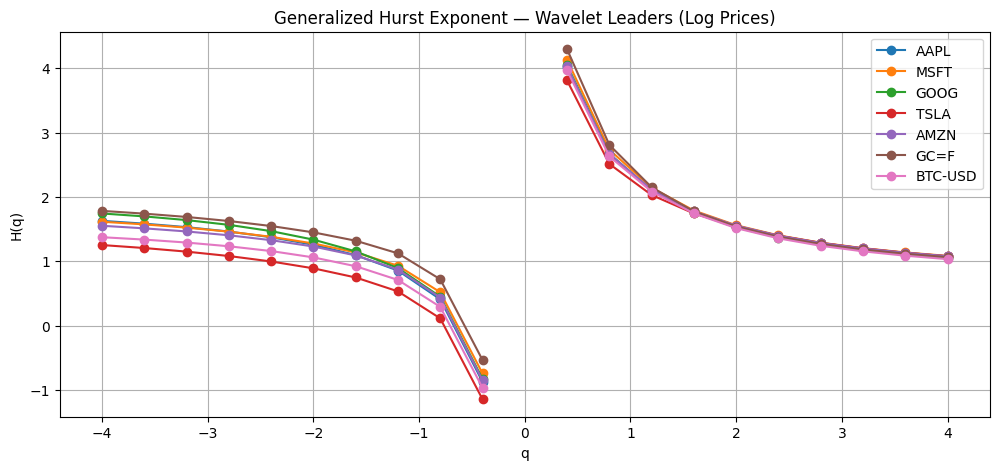

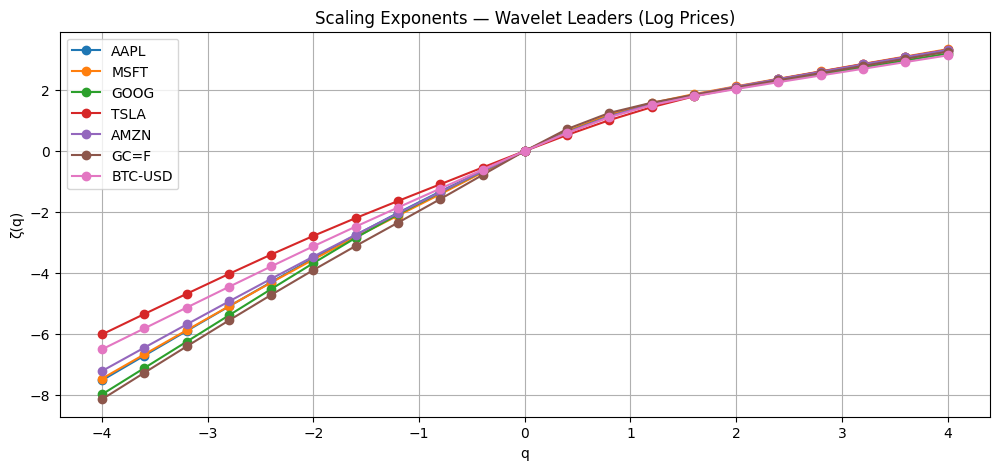

In [13]:
import numpy as np
import pandas as pd
import yfinance as yf
import pywt
import matplotlib.pyplot as plt
from scipy.stats import linregress


# =====================================================
# PARAMETERS
# =====================================================

TICKERS = ["AAPL", "MSFT", "GOOG", "TSLA", "AMZN", "GC=F", "BTC-USD"]

START = "2018-01-01"
END   = "2026-01-01"

WAVELET = "mexh"          # Mexican hat = removes quadratic trend
SCALES = np.logspace(1, 3, 30).astype(int)

Q = np.linspace(-4, 4, 21)


# =====================================================
# DATA
# =====================================================

def load_log_prices(ticker):

    data = yf.download(ticker, start=START, end=END)

    price = data["Close"]

    if isinstance(price, pd.DataFrame):
        price = price.iloc[:, 0]

    logp = np.log(price).dropna()

    return logp.values.flatten()


# =====================================================
# CWT
# =====================================================

def compute_cwt(signal):

    signal = np.asarray(signal).flatten()

    coef, _ = pywt.cwt(
        signal,
        scales=SCALES,
        wavelet=WAVELET
    )

    return np.abs(coef)


# =====================================================
# WAVELET LEADERS
# =====================================================

def compute_leaders(coef):

    leaders = []

    for i in range(coef.shape[0] - 1):

        W1 = coef[i]
        W2 = coef[i + 1]

        L = np.maximum(W1, W2)

        leaders.append(L)

    return np.array(leaders)


# =====================================================
# PARTITION FUNCTION (LEADERS)
# =====================================================

def leader_partition(leaders):

    Z = {}

    eps = 1e-10

    for q in Q:

        Zq = []

        for j in range(leaders.shape[0]):

            L = leaders[j].flatten()

            if q < 0:
                L = L[L > eps]

            if len(L) < 20:
                continue

            Zq.append(np.mean(L ** q))

        Z[q] = np.array(Zq)

    return Z


# =====================================================
# SCALING EXPONENT
# =====================================================

def estimate_zeta(Z):

    zeta = {}

    valid = [len(v) for v in Z.values() if len(v) > 5]

    if len(valid) == 0:
        return {q: np.nan for q in Q}

    n = min(valid)

    log_s = np.log(SCALES[:n])

    for q in Q:

        Zq = Z[q][:n]

        if len(Zq) < 5:
            zeta[q] = np.nan
            continue

        logZ = np.log(Zq)

        slope, _, _, _, _ = linregress(log_s, logZ)

        zeta[q] = slope

    return zeta


# =====================================================
# HURST FROM ZETA
# =====================================================

def compute_Hq(zeta):

    Hq = {}

    for q in Q:

        if abs(q) < 0.2:
            Hq[q] = np.nan
        else:
            Hq[q] = (zeta[q] + 1) / q

    return Hq


# =====================================================
# PIPELINE
# =====================================================

def analyze_stock(ticker):

    print(f"Processing {ticker}...")

    signal = load_log_prices(ticker)

    coef = compute_cwt(signal)

    leaders = compute_leaders(coef)

    Z = leader_partition(leaders)

    zeta = estimate_zeta(Z)

    Hq = compute_Hq(zeta)

    return Hq, zeta


# =====================================================
# RUN
# =====================================================

def main():

    results = {}

    for t in TICKERS:

        Hq, zeta = analyze_stock(t)

        results[t] = {
            "Hq": Hq,
            "zeta": zeta
        }


    # -------------------------------
    # PLOT H(q)
    # -------------------------------

    plt.figure(figsize=(12,5))

    for t in TICKERS:

        q = np.array(list(results[t]["Hq"].keys()))
        H = np.array(list(results[t]["Hq"].values()))

        plt.plot(q, H, marker="o", label=t)

    plt.xlabel("q")
    plt.ylabel("H(q)")
    plt.title("Generalized Hurst Exponent — Wavelet Leaders (Log Prices)")
    plt.legend()
    plt.grid(True)
    plt.show()


    # -------------------------------
    # PLOT zeta(q)
    # -------------------------------

    plt.figure(figsize=(12,5))

    for t in TICKERS:

        q = np.array(list(results[t]["zeta"].keys()))
        z = np.array(list(results[t]["zeta"].values()))

        plt.plot(q, z, marker="o", label=t)

    plt.xlabel("q")
    plt.ylabel("ζ(q)")
    plt.title("Scaling Exponents — Wavelet Leaders (Log Prices)")
    plt.legend()
    plt.grid(True)
    plt.show()


if __name__ == "__main__":
    main()


| Method                 | Handles q<0 | Stability | Finance-ready |
| ---------------------- | ----------- | --------- | ------------- |
| **MF-DFA**             | ✅           | ⭐⭐⭐⭐⭐     | ✅✅✅           |
| **Wavelet (WTMM)**     | ✅           | ⭐⭐⭐       | ⚠️            |
| **MF-SF**              | ⚠️          | ⭐⭐        | ⚠️            |
| **Partition Function** | ❌           | ⭐         | ❌             |


# EMD- MF- DFA


Processing AAPL...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\701224498.py:86: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


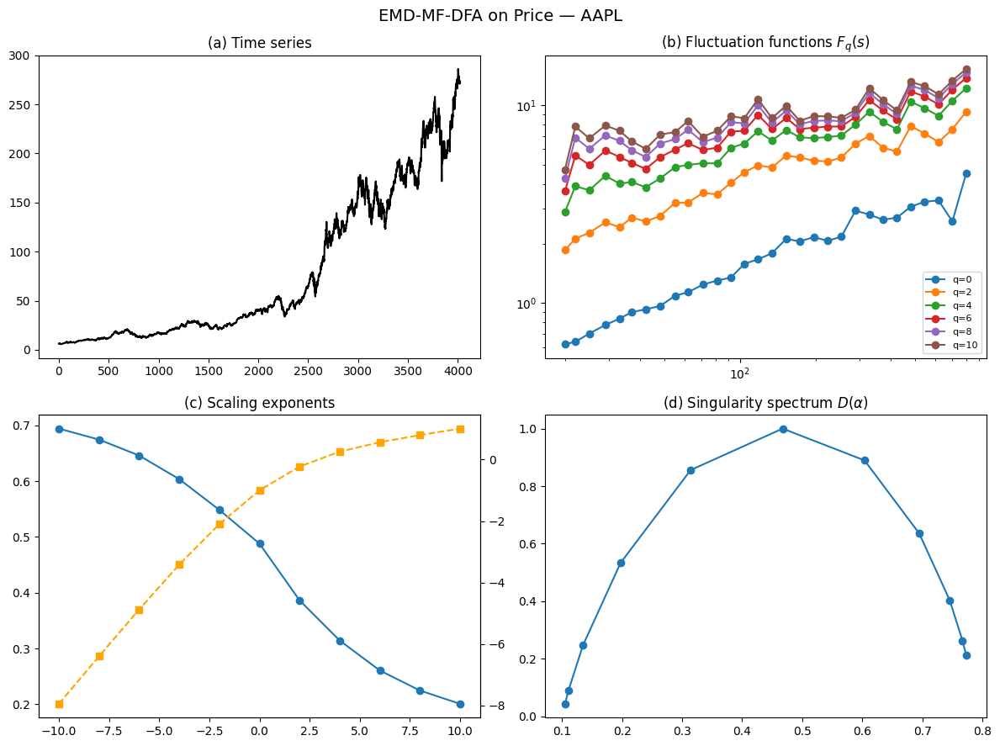

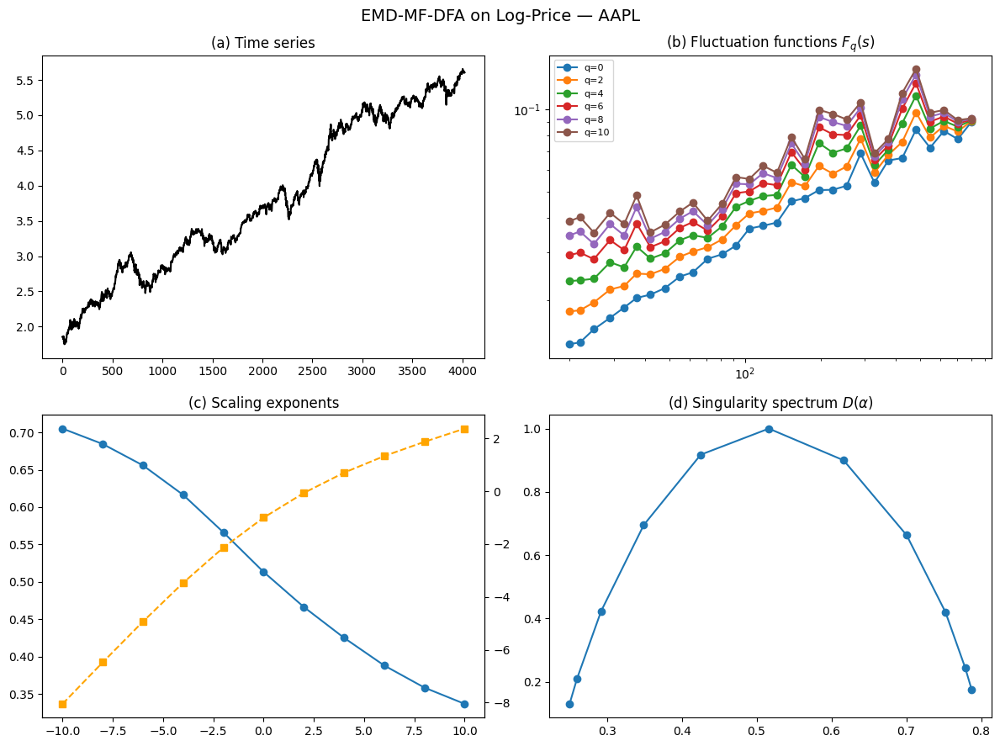


Processing MSFT...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\701224498.py:86: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


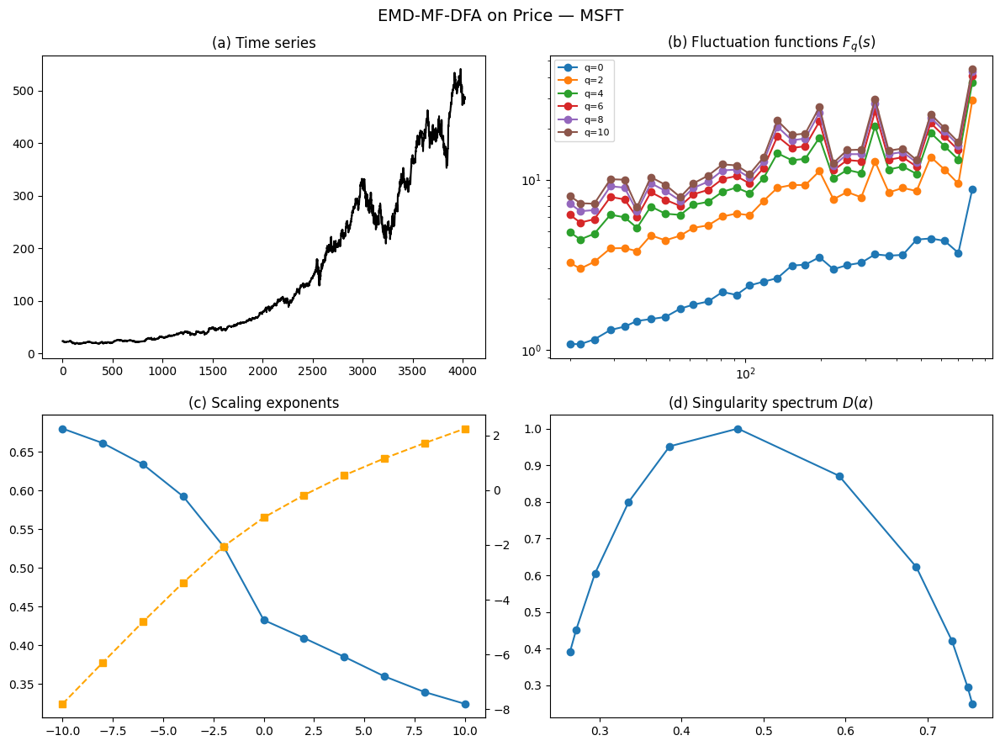

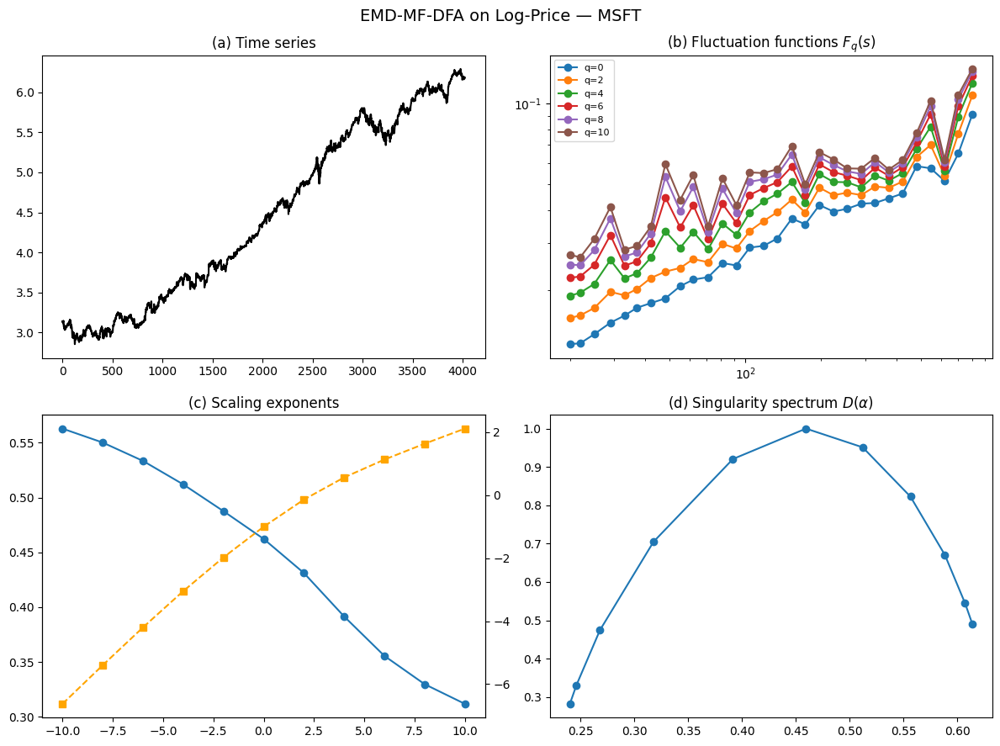


Processing GOOG...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\701224498.py:86: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


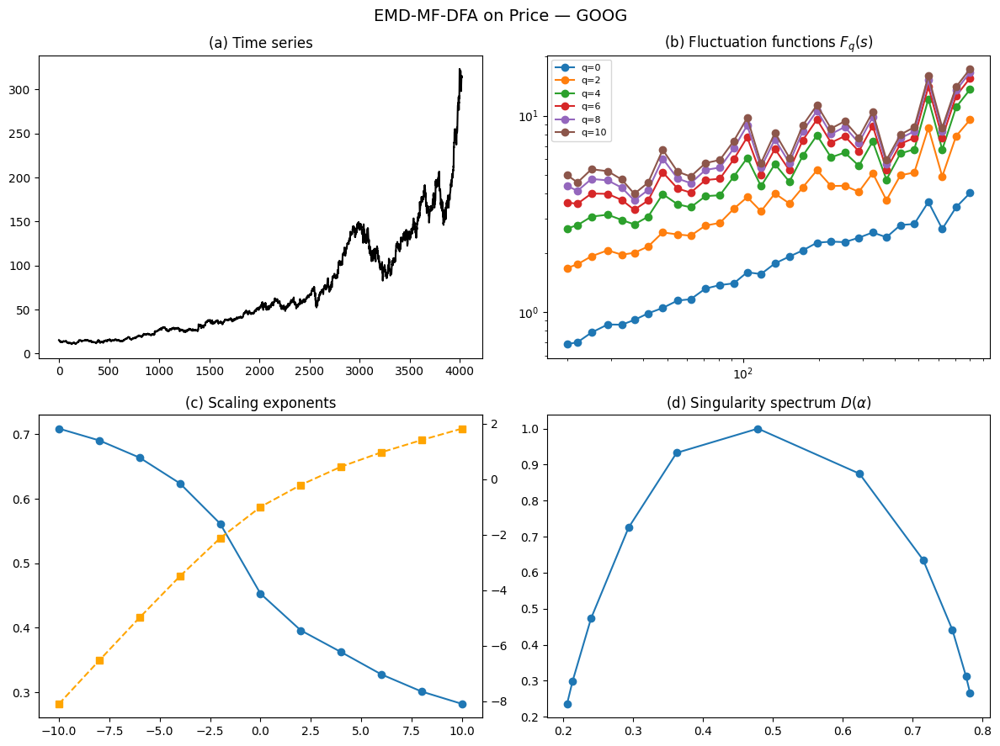

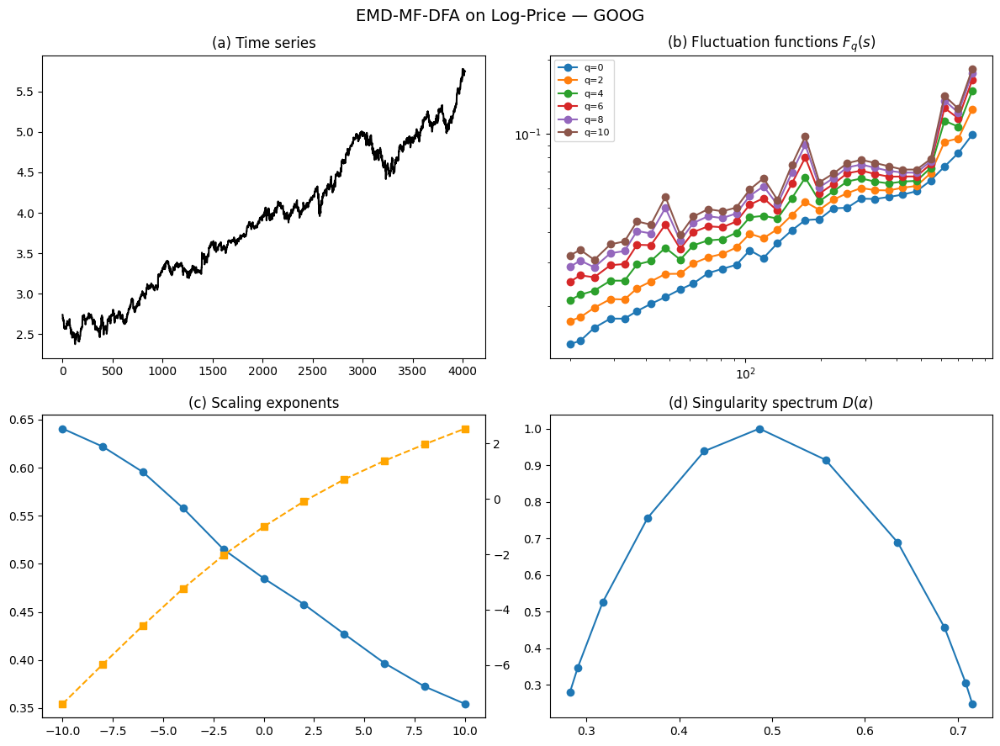


Processing TSLA...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\701224498.py:86: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


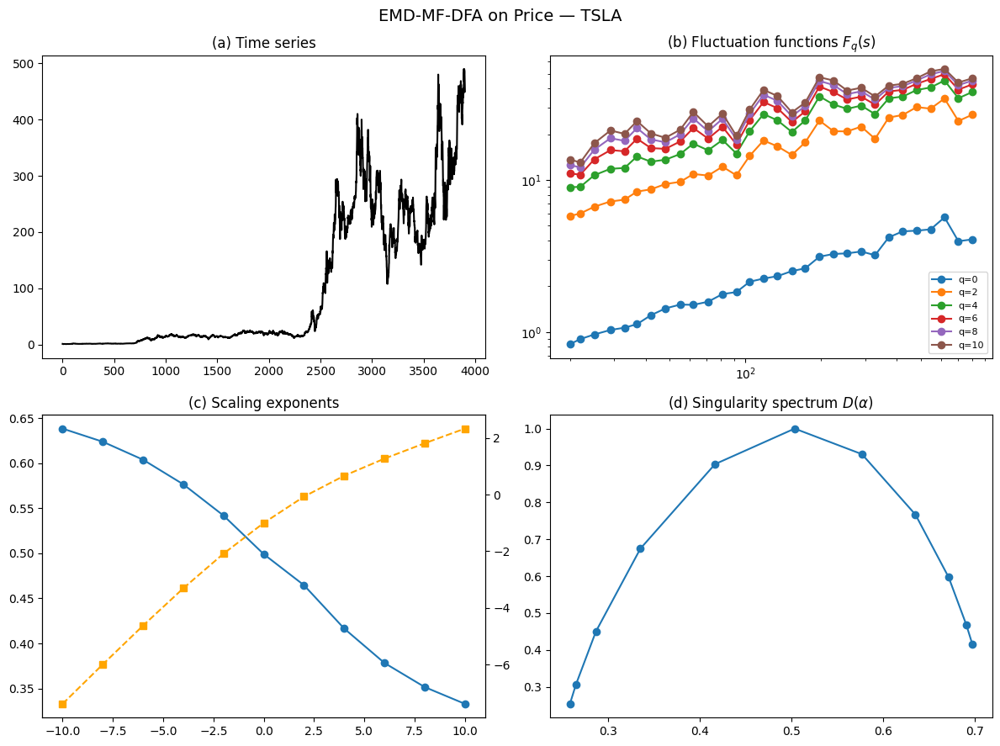

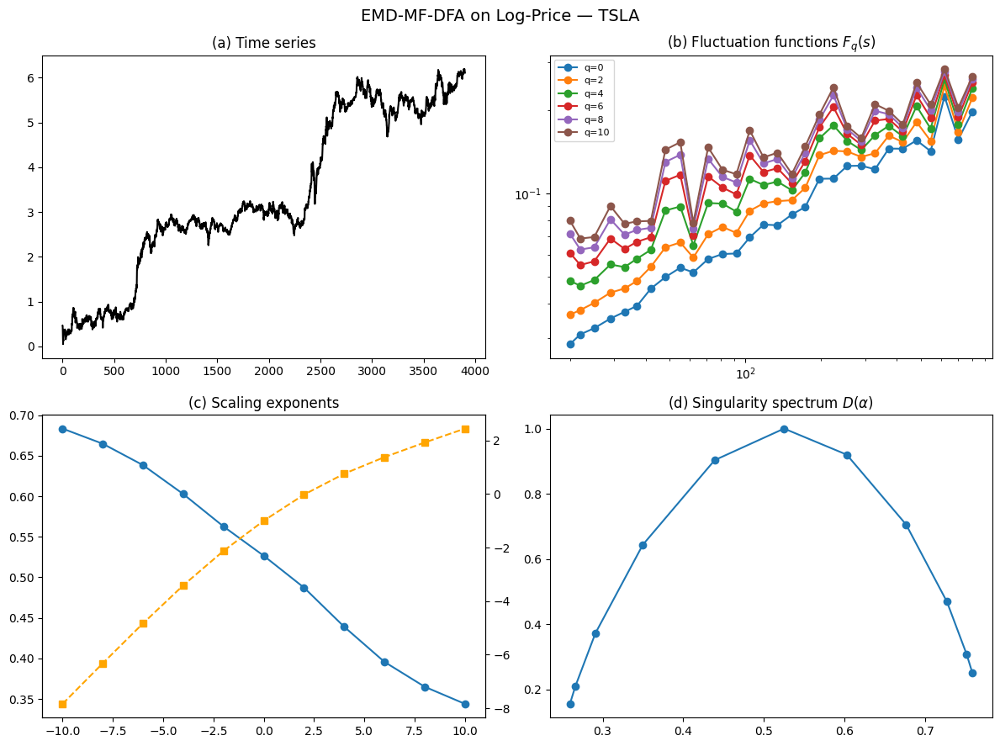


Processing AMZN...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\701224498.py:86: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


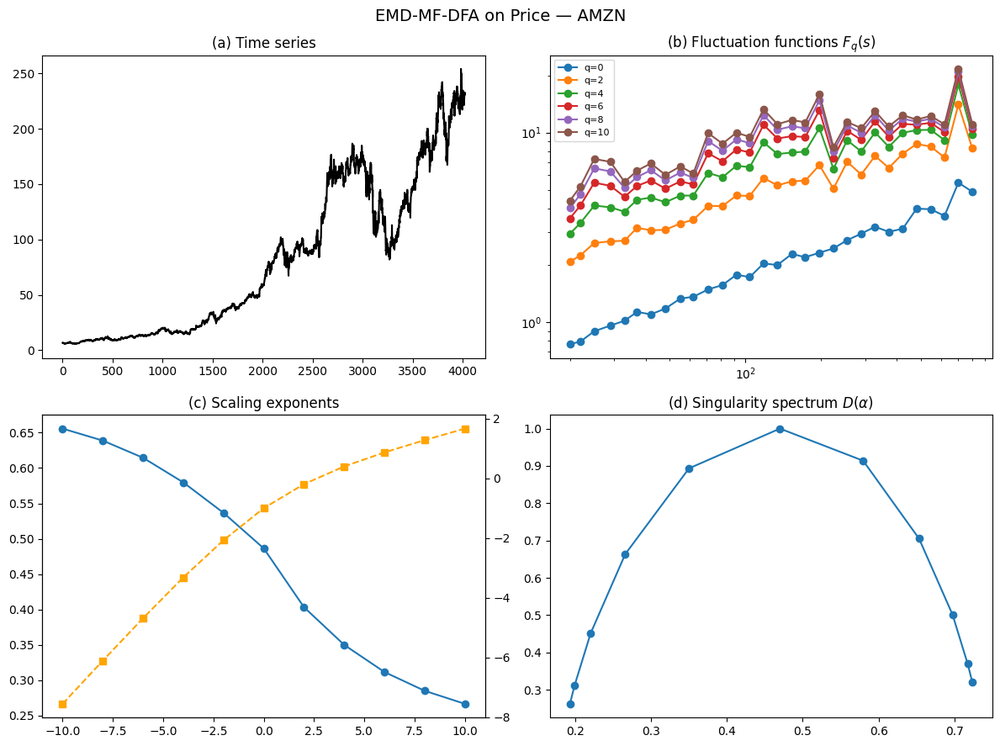

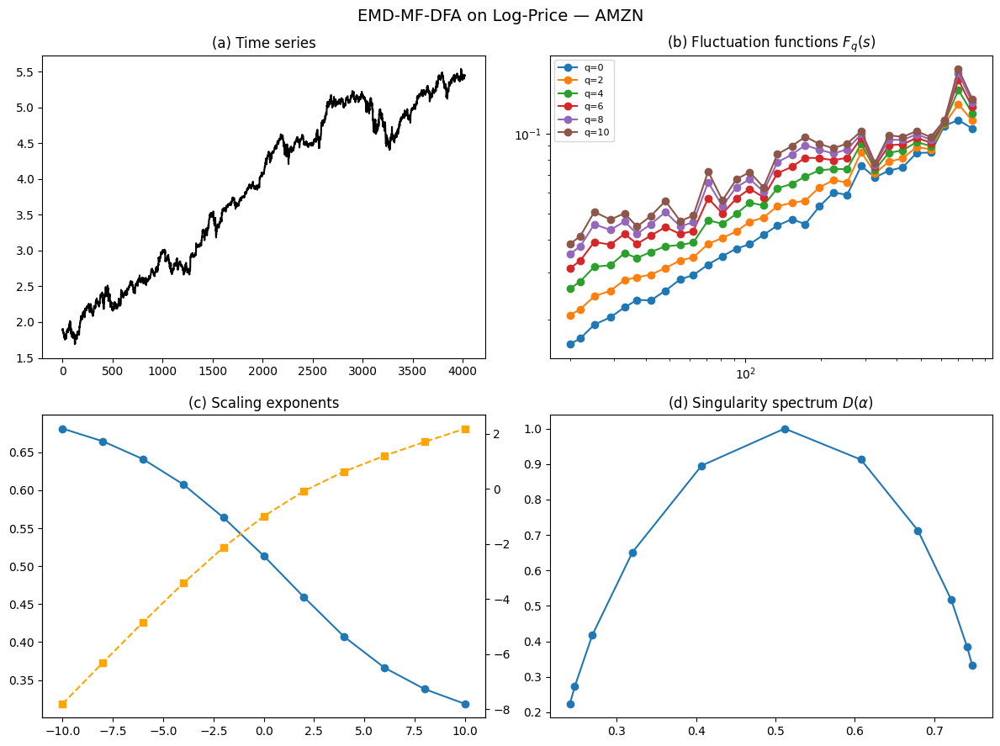


Processing GC=F...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\701224498.py:86: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


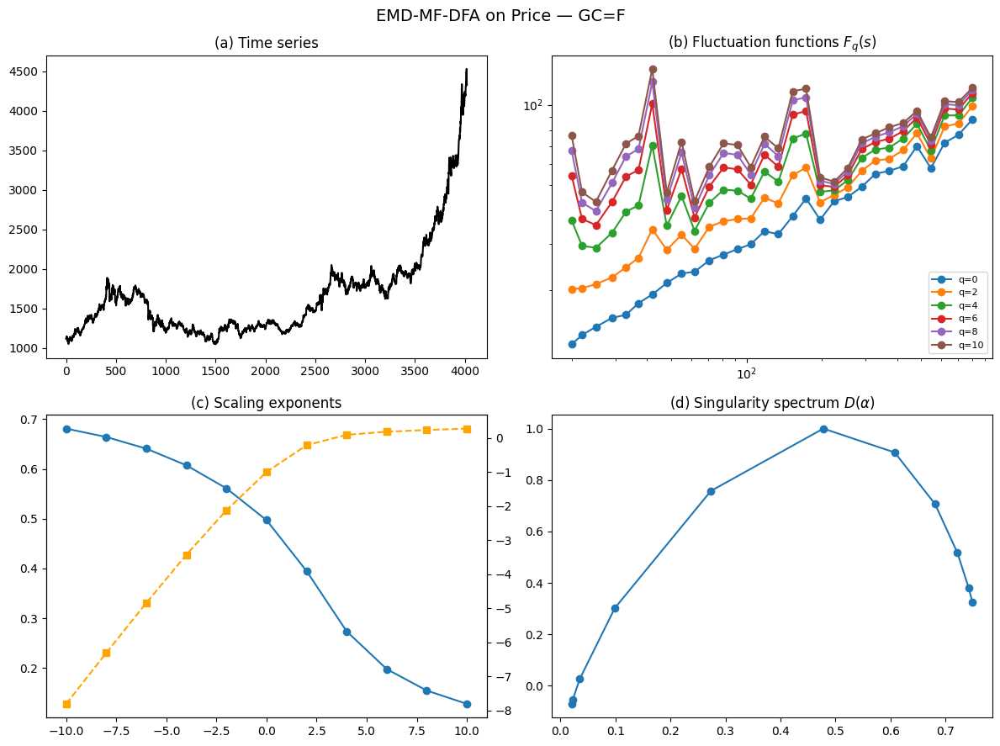

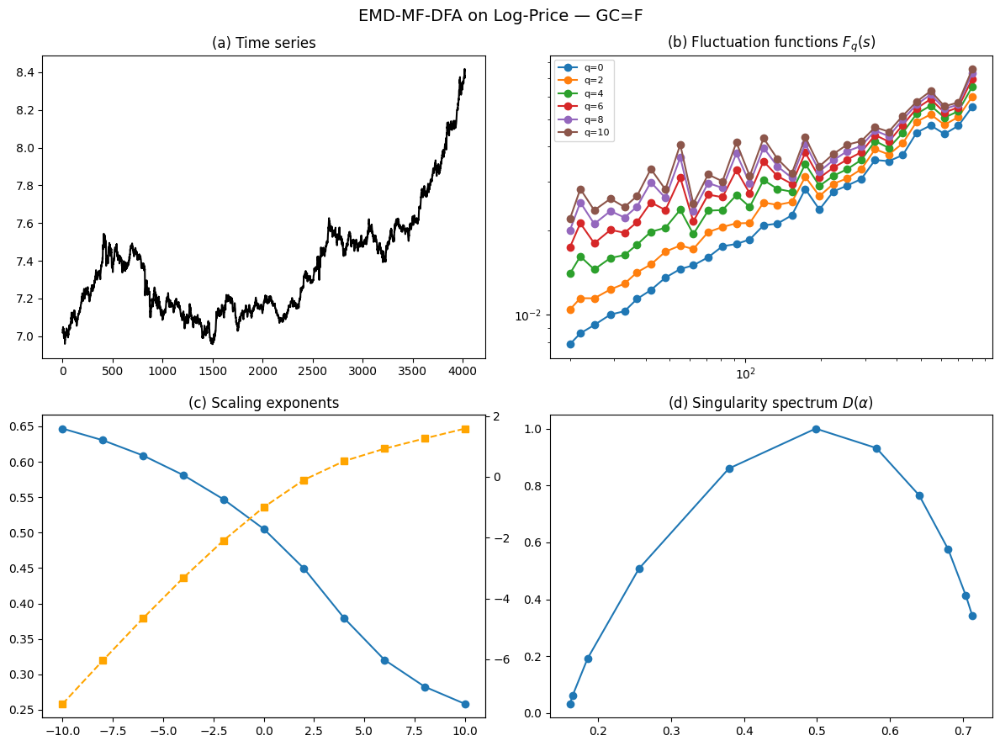


Processing BTC-USD...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11980\701224498.py:86: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


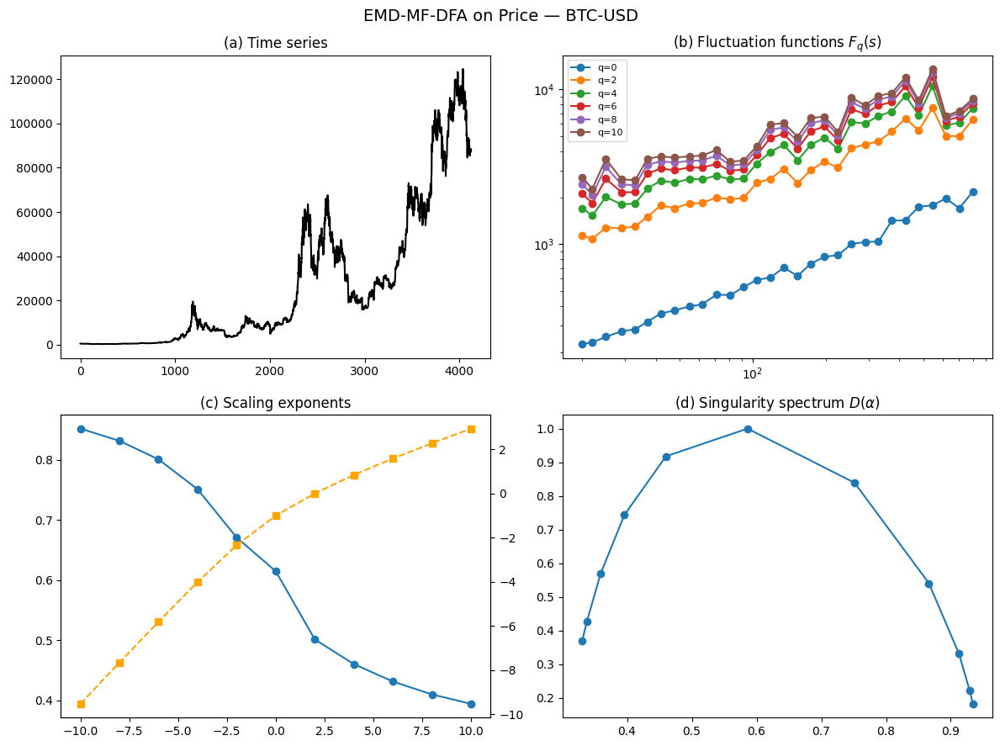

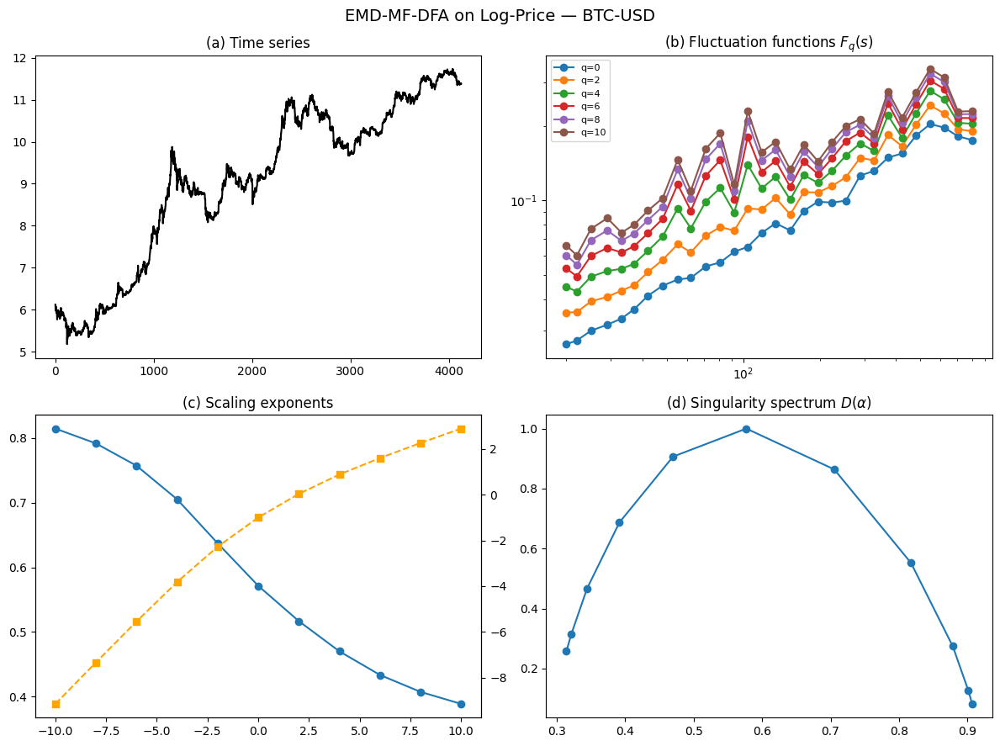

In [45]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from PyEMD import EMD

# =====================================
# PARAMETERS
# =====================================
tickers = ["AAPL", "MSFT", "GOOG", "TSLA", "AMZN", "GC=F", "BTC-USD"]
start = "2010-01-01"
end = "2026-01-01"

q_vals = np.arange(-10, 12, 2)
scale_min = 20
scale_max = 800
n_scales = 30

# =====================================
# EMD-BASED DETRENDING
# =====================================
def emd_detrend(signal):
    signal = np.asarray(signal).flatten()
    n = len(signal)

    if n < 5:
        return signal  # too short for EMD

    t = np.arange(n)   # 🔑 explicit time array

    emd = EMD()
    imfs = emd(signal, t)

    if imfs is None or imfs.shape[0] == 0:
        return signal

    trend = imfs[-1]   # residual / slowest mode
    return signal - trend

# =====================================
# EMD-MF-DFA CORE FUNCTION
# =====================================
def emd_mfdfa(x, q_vals, scale_min, scale_max, n_scales):
    scales = np.unique(
        np.logspace(np.log10(scale_min), np.log10(scale_max), n_scales).astype(int)
    )

    Fqs = np.zeros((len(q_vals), len(scales)))

    for i, s in enumerate(scales):
        Ns = len(x) // s
        rms = []

        for v in range(Ns):
            seg = x[v*s:(v+1)*s]

            # EMD detrending
            detrended = emd_detrend(seg)

            # RMS fluctuation (FULL SQUARE)
            rms.append(np.sqrt(np.mean(detrended**2)))

        rms = np.array(rms)
        rms = rms[rms > 0]  # stability for negative q

        for j, q in enumerate(q_vals):
            if q == 0:
                Fqs[j, i] = np.exp(0.5 * np.mean(np.log(rms**2)))
            else:
                Fqs[j, i] = (np.mean(rms**q))**(1/q)

    # Scaling exponents h(q)
    hq = np.array([
        np.polyfit(np.log(scales), np.log(Fqs[j]), 1)[0]
        for j in range(len(q_vals))
    ])

    return scales, Fqs, hq

# =====================================
# MAIN LOOP
# =====================================
for ticker in tickers:
    print(f"\nProcessing {ticker}...")

    data = yf.download(ticker, start=start, end=end, progress=False)
    price = data["Close"].dropna().values
    log_price = np.log(price)

    for series, label in [(price, "Price"), (log_price, "Log-Price")]:
        scales, Fqs, hq = emd_mfdfa(
            series, q_vals, scale_min, scale_max, n_scales
        )

        # Multifractal exponents
        tau_q = hq * q_vals - 1
        alpha = np.gradient(tau_q, q_vals)
        D_alpha = q_vals * alpha - tau_q

        # =====================================
        # PLOTS (4-panel layout)
        # =====================================
        fig, axs = plt.subplots(2, 2, figsize=(12, 9))
        fig.suptitle(f"EMD-MF-DFA on {label} — {ticker}", fontsize=14)

        # (a) Time series
        axs[0, 0].plot(series, color="black")
        axs[0, 0].set_title("(a) Time series")

        # (b) F_q(s)
        for q in q_vals[q_vals >= 0]:
            idx = np.where(q_vals == q)[0][0]
            axs[0, 1].loglog(scales, Fqs[idx], 'o-', label=f"q={q}")

        axs[0, 1].set_title("(b) Fluctuation functions $F_q(s)$")
        axs[0, 1].legend(fontsize=8)

        # (c) h(q) and tau(q)
        axs[1, 0].plot(q_vals, hq, 'o-', label="$h(q)$")
        axs[1, 0].set_title("(c) Scaling exponents")

        ax2 = axs[1, 0].twinx()
        ax2.plot(q_vals, tau_q, 's--', color="orange", label=r"$\tau(q)$")

        # (d) Singularity spectrum
        axs[1, 1].plot(alpha, D_alpha, 'o-')
        axs[1, 1].set_title("(d) Singularity spectrum $D(\\alpha)$")

        plt.tight_layout()
        plt.show()
